# Проектная работа

Тема: *«Детектирование скрытых дефектов железнодорожных тоннелей по данным георадиолокации»*

**Автор:** Сизиков Константин Александрович

**Курс:** Компьютерное зрение (OTUS)

## Описание работы

**Задача.** Обделка тоннеля — это бетонная оболочка, которая держит породу вокруг
тоннеля. Со временем в ней и за ней появляются дефекты, которых не видно глазом:
пустоты, скопления воды, разуплотнение, расслоения. Годами они растут незаметно, а
потом проявляются как вывалы бетона, протечки и деформации пути.

Такие дефекты ищут **георадаром**: антенну ведут вдоль стены тоннеля и получают
картинку-разрез — **георадарограмму**. Сейчас её расшифровывает специалист вручную.
Цель работы — обучить модель компьютерного зрения, которая сама находит на
георадарограмме дефекты и конструктивные элементы и обводит их рамкой.

Приоритетные классы (по убыванию важности): **пустоты, вода, трещины, нарушение
плотности, арматура, трубы.**

**Главная трудность — данные.** Открытого размеченного набора георадарограмм
железнодорожных тоннелей найти не удалось. Поэтому в работе используются:

* синтетика **TunGPR** — численное моделирование тоннельной обделки, 6 классов;
* реальные размеченные наборы из соседних областей: дороги (**URDD**), железобетон
  (**P-GPR**), классификационный набор **TIGPR**;
* реальные тоннельные записи без разметки (**Guangzhou**) и несколько наборов для
  проверки гипотез (USBR, GPRbase, Solla, composite lining);
* собственная синтетика, сгенерированная в gprMax под частоту 200 МГц.

**Подход.**

1. обзор источников, загрузка данных, чтение сырых форматов георадаров (IDS `.dt`,
   Sensors & Software `.dt1`, GSSI `.DZT`, MALÅ `.rd3`);
2. разведочный анализ (EDA) и анализ без учителя: эмбеддинги ResNet-18,
   кластеризация, поиск дубликатов, оценка разницы между синтетикой и реальными
   данными;
3. подготовка данных: единый формат, удаление дубликатов, разбиение без утечек;
4. детектор **YOLO11s** с аугментациями, которые не противоречат физике сигнала;
5. эксперименты: старт с синтетики против старта с COCO, зависимость от объёма
   разметки, дополнительные каналы сигнала, своя синтетика, TTA и ансамбли,
   перекрёстная проверка;
6. классификатор дефектов на TIGPR — для трещин и разуплотнения, у которых нет
   разметки рамками.

**Гипотеза.** Предобучение на синтетических георадарограммах улучшает детектор на
реальных данных, особенно когда реальной разметки мало.

**Оценка качества.** Основная метрика — mAP@0.5 с усреднением по классам;
дополнительно — метрики по каждому классу и recall при точности 0.5. Чтобы отличить
реальную разницу между моделями от случайной, используются парный бутстрэп и
перекрёстная проверка на 4 фолдах.

**Содержание:**

1. Постановка задачи
2. Данные
3. Разведочный анализ данных (EDA)
4. Анализ без учителя
5. Физическая проверка: что георадар видит вместо трещины
6. Подготовка данных
7. Метрики качества
8. Модель и аугментации
9. Обучение
10. Классификация дефектов на реальных данных (TIGPR)
11. Анализ результатов
12. Выводы

## Настройка окружения

Для запуска ноутбука нужно:

1. Создать виртуальное окружение и поставить зависимости (версии закреплены точно:
   от версии `ultralytics` зависят значения метрик, см. раздел 11.13):
   ```
   python3 -m venv --system-site-packages .venv
   .venv/bin/pip install -r requirements.txt
   .venv/bin/python -m ipykernel install --user --name rzhd-venv
   ```
2. Положить датасеты в каталог `data/` (источники перечислены в разделе 2 и в
   `README.md`), стартовые веса YOLO11 — в `weights/`.
3. Запустить ячейки по порядку. Для обучения нужен GPU (работа выполнена на
   NVIDIA RTX 3090). Уже обученные модели из `runs/` используются повторно, поэтому
   повторный прогон не переобучает их; чтобы обучить эксперимент заново, достаточно
   удалить его каталог `runs/<эксперимент>`.

Ноутбук собирается из исходников `notebook_src/*.py` скриптом
`tools/build_notebook.py`, поэтому текст и код правятся там.

## 1. Постановка задачи

### 1.1. Предметная область

**Георадар** (Ground Penetrating Radar, GPR) посылает в бетон короткий
электромагнитный импульс и принимает отражённый сигнал. Отражения возникают на
границах материалов с разной диэлектрической проницаемостью ε: бетона, воздуха, воды,
породы. Запись в одной точке — это временной ряд (**A-scan**). Если вести антенну
вдоль стены и поставить такие записи рядом, получится двумерная картинка —
**B-scan**, или георадарограмма:

* ось X — расстояние вдоль стены;
* ось Y — время прихода отражения (чем ниже, тем глубже);
* яркость — сила отражённого сигнала.

Именно поэтому задача относится к компьютерному зрению: у дефектов на B-scan есть
узнаваемый вид. Арматура и трубы дают гиперболы, границы материалов — протяжённые
полосы, пустоты и вода — участки с сильными отражениями.

### 1.2. Что вообще видно георадаром

Сила отражения на границе двух сред задаётся коэффициентом отражения:

$$R = \frac{\sqrt{\varepsilon_1} - \sqrt{\varepsilon_2}}{\sqrt{\varepsilon_1} + \sqrt{\varepsilon_2}}$$

Типичные значения: бетон ε ≈ 6–9, воздух ε = 1, вода ε ≈ 81, порода ε ≈ 5–12.
Из формулы следуют три важных для работы вывода.

1. **Пустоты с воздухом и с водой различимы.** Воздушная пустота даёт R ≈ +0.45:
   сильное отражение с тем же знаком, что и у исходного импульса. Пустота с водой
   даёт R ≈ −0.55: отражение ещё сильнее, но со **сменой знака**, а под ней сигнал
   быстро затухает. По знаку отражения специалист и отличает воздух от воды.
2. **Георадар видит не плотность, а разницу ε.** «Нарушение плотности» заметно
   только косвенно: плотность меняет ε, а прибор реагирует именно на разницу ε.
3. **Тонкие трещины практически не видны.** При частоте 800 МГц длина волны в
   бетоне (ε ≈ 7) около 14 см, и две границы тонкого слоя различаются, только если
   он толще примерно λ/4 ≈ 3.5 см. Более тонкий слой всё равно даёт отражение, но
   слабое: чем тоньше слой, тем слабее сигнал (это проверяется на реальных измерениях
   в разделе 5). Волосяная трещина в 0.2 мм — это λ/700, и её отклик тонет в шуме.
   Уверенно георадар видит только раскрытые трещины и расслоения, заполненные водой
   или воздухом.

Последний пункт — ограничение метода, а не модели. Его важно учесть сразу, при
постановке задачи.

### 1.3. Приоритетные классы

| № | Класс | Как выглядит на B-scan | Можно ли найти георадаром |
|---|---|---|---|
| 1 | **Пустоты** (воздушные) | сильное отражение без смены знака (R ≈ +0.45), повторные отражения | да |
| 2 | **Вода** (водонасыщение, пустоты с водой) | ещё более сильное отражение со сменой знака (R ≈ −0.55), затухание ниже | да |
| 3 | **Трещины** | видны только раскрытые или заполненные; волосяные не видны | ограниченно |
| 4 | **Нарушение плотности** | граница материалов смещена и размыта | частично |
| 5 | **Арматура** | ряд одинаковых узких гипербол | да |
| 6 | **Трубы** | одиночные широкие гиперболы, иногда с отражением изнутри | да |

### 1.4. Постановка задачи для компьютерного зрения

Задача ставится как **детекция объектов**: по картинке B-scan модель должна выдать
список рамок, для каждой — класс и уверенность.

*Почему не классификация кадра целиком.* Специалисту нужно знать, **где** дефект
(место вдоль тоннеля и глубину), а не только то, что он есть. К тому же на одном
кадре обычно несколько объектов сразу: арматура, граница, дефект.

*Почему не сегментация.* Разметка по пикселям требует эксперта и стоит намного
дороже. А границы дефекта на B-scan размыты, и эксперты расходятся в контуре. Рамки
надёжнее, и для решения о ремонте их достаточно.

### 1.5. Главная трудность и план работы

Открытого размеченного набора реальных георадарограмм железнодорожных тоннелей со
всеми шестью классами найти не удалось (поиск по Zenodo, Mendeley, Figshare,
Kaggle, GitHub, Papers with Code и публикациям, сентябрь 2026 года). Это результат
поиска, а не доказательство того, что таких данных нет.

Поэтому работа построена как **перенос знаний из численного моделирования**:

1. предобучить детектор на синтетике: модели тоннельной обделки, рассчитанные в
   программе gprMax (набор TunGPR);
2. дообучить его на реальных размеченных данных из похожих задач: дефекты дорог,
   железобетонные конструкции;
3. сравнить с обычным обучением только на реальных данных.

Проверяемая гипотеза: **предобучение на синтетических георадарограммах повышает
качество детектора на реальных данных, когда реальной разметки мало.**

### Импорт библиотек и общие настройки

In [1]:
# --- окружение и общие настройки ---
import os, sys, json, glob, random, warnings, subprocess, hashlib
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

ROOT = Path.cwd()
if not (ROOT / "data").exists() and (ROOT.parent / "data").exists():
    ROOT = ROOT.parent
DATA = ROOT / "data"
WORK = ROOT / "work"        # промежуточные артефакты
RUNS = ROOT / "runs"        # результаты обучения
for d in (WORK, RUNS):
    d.mkdir(exist_ok=True)

mpl.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": "white",
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 9,
})

print("корень проекта:", ROOT)
print("python:", sys.version.split()[0])

import torch
print("torch:", torch.__version__, "| CUDA:", torch.cuda.is_available(),
      "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")
DEVICE = 0 if torch.cuda.is_available() else "cpu"

корень проекта: /home/ubuntu/projects/ml/rzhd
python: 3.11.5
torch: 2.7.0.dev20250114+cu126 | CUDA: True | NVIDIA GeForce RTX 3090


---
## 2. Данные

### 2.1. Обзор доступных источников

Перед началом работы был проведён поиск открытых георадарных наборов данных: карточки
датасетов, статьи, репозитории авторов, облачные хранилища. Главный вывод:

> **Открытого размеченного набора реальных георадарограмм железнодорожных тоннелей
> со всеми шестью целевыми классами найти не удалось.** Реальные тоннельные данные
> либо не публикуют из-за ведомственных ограничений, либо публикуют без разметки,
> либо выдают по запросу у авторов.

Поэтому обучающие данные собраны из нескольких источников разного типа.

| Набор | Что это | Данные | Разметка | Лицензия | Зачем в работе |
|---|---|---|---|---|---|
| **TunGPR** | модели тоннельной обделки | синтетика gprMax, 800 МГц, 512×512 | рамки VOC XML, 6 классов | не указана | предобучение |
| **URDD** | реальные городские дороги | PNG, 200 МГц | рамки COCO/VOC/YOLO, 4 класса | CC BY 4.0 | основной реальный набор: пустоты, вода, разуплотнение |
| **P-GPR** | реальные бетонные стены | PNG, 1600 МГц | рамки YOLO, 2 класса | CC BY 4.0 | реальный набор: арматура и трубы |
| **GPR_Data (Morocco)** | реальные городские съёмки | JPG, 200/400 МГц | YOLO + VOC, 2 класса | CC BY 4.0 | EDA |
| **rebars YOLOv11** | железобетон, сводный набор | JPG | YOLO, класс `bar` | не указана | EDA, статистика по арматуре |
| **TIGPR** | транспортная инфраструктура | 7169 кадров 200×200 | 5 классов на кадр, без рамок | CC BY 4.0 | классификация (раздел 10) |
| **Solla cracks** | лабораторные бетонные плиты | сырые MALÅ `.rd3`, 2.3 ГГц | параметры трещин известны | см. карточку | физический эксперимент (раздел 5) |
| **Composite lining** | реальный тоннель со сборной обделкой | 15 разрезов, извлечены из EMF внутри DOCX | нет | CC BY 4.0 | визуальная проверка |
| **Guangzhou GPR DATASET** | реальные тоннели, трубы, арматура | сырые `.dt` (IDS), 67 тоннельных профилей, 1.7 млн трасс | нет | CC BY 4.0 | реальные тоннели без разметки |
| **USBR Void Detection** | облицовка канала и плиты с заложенными пустотами | сырые `.dt1` (Sensors & Software), 1 ГГц | положение пустот из отчёта | открытые данные Bureau of Reclamation | пустоты с известным положением |
| **GPRbase** (ds001, ds004, ds009, ds014) | стена из бетонных блоков с пустотами, железобетон с двойной сеткой | сырые `.DZT` (GSSI MiniXT) | нет | CC BY-NC-SA 4.0 | пустоты в кладке, экранирование сеткой |

Набор **LGSC / PGSC** (1787 кадров с рамками трещин, CC BY 4.0) в работу не попал:
он лежит в папке Google Drive, и скачивание остановилось на 41-м файле из 2645 из-за
квоты сервиса. Это был единственный найденный набор с рамками трещин.

Проверены и **исключены** источники, которые часто называют доступными, но
скачать их нельзя: TLAD-YOLO (данные по запросу у автора), набор Yue et al. на 2245
изображений тоннелей (описан в статье, но не опубликован), MGT-Net и
Multimodal-GPR-CHD (в репозиториях нет изображений), GPRInvNet (архив не
опубликован). Kaggle-набор «GPR Normal and Tunnel Anomaly» тоже исключён: в нём ищут
сам подземный ход с поверхности земли, а не дефекты обделки.

### 2.2. Что лежит в проекте

Содержимое каталога `data/`: объём, число файлов, форматы. Здесь же видно, какие
наборы скачались полностью.

In [2]:
def human(n):
    for u in ["Б", "КБ", "МБ", "ГБ"]:
        if n < 1024:
            return f"{n:.0f} {u}"
        n /= 1024
    return f"{n:.1f} ТБ"

IMG_EXT = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

def cache_ready(dir_path, pattern="*.jpg", min_files=1):
    """Готов ли кеш нарезки.

    Проверять только существование каталога недостаточно: каталог создаётся до
    записи файлов, и прерванный прогон оставляет пустую папку, из-за которой все
    последующие запуски молча пропускают подготовку. Именно так набор GPRbase один
    раз выпал из общего анализа, оставшись в ноутбуке строкой «нарезано окон: 0».
    """
    d = Path(dir_path)
    return d.exists() and len(list(d.glob(pattern))) >= min_files


def scan_dir(p: Path):
    n_files = n_img = n_xml = n_txt = 0
    size = 0
    ext = Counter()
    for dirpath, _, files in os.walk(p):
        for f in files:
            fp = Path(dirpath) / f
            try:
                size += fp.stat().st_size
            except OSError:
                continue
            n_files += 1
            e = fp.suffix.lower()
            ext[e] += 1
            if e in IMG_EXT:
                n_img += 1
            elif e == ".xml":
                n_xml += 1
            elif e == ".txt":
                n_txt += 1
    return dict(files=n_files, images=n_img, xml=n_xml, txt=n_txt, size=size,
                top_ext=", ".join(f"{k or '—'}:{v}" for k, v in ext.most_common(4)))

inv = []
for d in sorted([p for p in DATA.iterdir() if p.is_dir()]):
    s = scan_dir(d)
    inv.append({"набор": d.name, "файлов": s["files"], "изображений": s["images"],
                "xml": s["xml"], "txt": s["txt"], "объём": human(s["size"]),
                "форматы": s["top_ext"]})

inventory = pd.DataFrame(inv)
display(inventory)

,набор,файлов,изображений,xml,txt,объём,форматы
0,composite_lining,26,15,0,0,186 МБ,".png:15, .emf:10, .docx:1"
1,gprbase,162,0,0,0,84 МБ,".dzt:80, .dzx:78, .bzx:3, .dims:1"
2,guangzhou,352,0,0,45,8 ГБ,".srd:76, .dt:67, .bkg:52, .stc:52"
3,morocco,5203,2524,1339,1339,97 МБ,".jpg:2524, .xml:1339, .txt:1339, .rar:1"
4,pgpr,603,274,0,274,38 МБ,".txt:274, .png:274, —:17, .sample:12"
5,rebar_yolo,5059,2528,0,2529,60 МБ,".txt:2529, .jpg:2528, .zip:1, .yaml:1"
6,solla_cracks,213,0,0,0,14 МБ,".rad:33, .cor:30, .mrk:30, .rd3:30"
7,subsurface_cracks,41,41,0,0,4 МБ,.png:41
8,tigpr,8794,8793,0,0,564 МБ,".jpg:7169, .png:1624, .rar:1"
9,tungpr,8053,2778,1389,1859,3 ГБ,".jpg:2396, .txt:1859, .in:1550, .xml:1389"


### 2.3. Единый формат разметки

Наборы размечены в разных форматах: TunGPR — Pascal VOC XML, P-GPR и LGSC/PGSC —
YOLO, URDD — COCO JSON (и параллельно VOC/YOLO), TIGPR — классами по папкам. Чтобы
анализировать их вместе, вся разметка сводится в одну таблицу:

`dataset · image_path · width · height · class · xc · yc · w · h` (координаты
от 0 до 1, как в YOLO).

Для каждого кадра также записывается, откуда он: синтетика или реальная съёмка, тип
конструкции (тоннель / дорога / железобетон), частота антенны. Это нужно для EDA и
для разбиения на выборки: смешивать разные источники внутри одной выборки нельзя.

In [3]:
import xml.etree.ElementTree as ET

# Отклонённые файлы и рамки не должны исчезать молча: любая «потеря» кадров при
# загрузке потом всплывает как необъяснимое расхождение в таблицах EDA.
rejected = Counter()

def _img_index(root: Path):
    """Индекс изображений: (папка-владелец, имя без расширения) -> путь, плюс
    глобальный индекс по имени.

    Одного глобального индекса недостаточно: в TunGPR файлы `1000_8e8` есть и в
    исправной, и в дефектной группе, и сопоставление «по имени вообще» склеивает
    разные кадры — в первой версии это молча теряло треть корпуса.
    """
    by_dir, by_stem = {}, {}
    for dirpath, _, files in os.walk(root):
        for f in files:
            if Path(f).suffix.lower() in IMG_EXT:
                p = Path(dirpath) / f
                by_dir[(str(Path(dirpath).parent), p.stem)] = p
                by_dir[(str(dirpath), p.stem)] = p
                by_stem.setdefault(p.stem, p)
    return by_dir, by_stem


def _find_image(ann_path: Path, by_dir, by_stem):
    """Ищем картинку сначала рядом с разметкой (соседняя папка того же кейса),
    потом в той же папке, и только в последнюю очередь — по имени глобально."""
    stem = ann_path.stem
    for key in ((str(ann_path.parent.parent), stem), (str(ann_path.parent), stem),
                (str(ann_path.parent.parent.parent), stem)):
        if key in by_dir:
            return by_dir[key]
    return by_stem.get(stem)


def load_voc(root: Path, dataset: str, **meta):
    """Pascal VOC XML (TunGPR). Сопоставление картинки по имени файла, а не по
    тегу <filename>: в TunGPR этот тег не соответствует имени файла."""
    rows = []
    if not root.exists():
        return rows
    by_dir, by_stem = _img_index(root)
    for dirpath, _, files in os.walk(root):
        for f in files:
            if not f.lower().endswith(".xml"):
                continue
            p = Path(dirpath) / f
            try:
                r = ET.parse(p).getroot()
            except Exception:
                continue
            img = _find_image(p, by_dir, by_stem)
            if img is None:
                continue
            size = r.find("size")
            if size is None:
                continue
            W, H = float(size.findtext("width")), float(size.findtext("height"))
            for o in r.findall(".//object"):
                name = (o.findtext("name") or "").strip()
                bb, rb = o.find("bndbox"), o.find("robndbox")
                if bb is not None:
                    x1, y1, x2, y2 = (float(bb.findtext(k)) for k in ("xmin", "ymin", "xmax", "ymax"))
                elif rb is not None:  # roLabelImg, встречается в части TunGPR
                    cx, cy, w, h, ang = (float(rb.findtext(k)) for k in ("cx", "cy", "w", "h", "angle"))
                    ca, sa = abs(np.cos(ang)), abs(np.sin(ang))
                    ew, eh = w * ca + h * sa, w * sa + h * ca
                    x1, y1, x2, y2 = cx - ew / 2, cy - eh / 2, cx + ew / 2, cy + eh / 2
                else:
                    continue
                # каждую координату ограничиваем по отдельности: при sorted((max(0, x1),
                # min(W, x2))) полностью вылетевшая за кадр рамка (x1 > W и x2 > W)
                # остаётся за границей
                x1, x2 = sorted((x1, x2)); y1, y2 = sorted((y1, y2))
                x1, x2 = min(max(x1, 0.0), W), min(max(x2, 0.0), W)
                y1, y2 = min(max(y1, 0.0), H), min(max(y2, 0.0), H)
                if x2 - x1 <= 0 or y2 - y1 <= 0:
                    rejected["рамка вне кадра"] += 1
                    continue
                if x2 <= x1 or y2 <= y1:
                    continue
                rows.append(dict(dataset=dataset, image=str(img), width=W, height=H, cls=name,
                                 xc=(x1 + x2) / 2 / W, yc=(y1 + y2) / 2 / H,
                                 w=(x2 - x1) / W, h=(y2 - y1) / H, **meta))
    return rows


def load_yolo(img_root: Path, lbl_root: Path, names, dataset: str, **meta):
    """YOLO: labels/*.txt рядом с images/*. names — список или dict id->имя."""
    rows = []
    if not img_root.exists() or not lbl_root.exists():
        return rows
    if isinstance(names, dict):
        names = [names[k] for k in sorted(names)]
    from PIL import Image
    by_dir, by_stem = _img_index(img_root)
    for dirpath, _, files in os.walk(lbl_root):
        for f in files:
            if not f.endswith(".txt"):
                continue
            img = _find_image(Path(dirpath) / f, by_dir, by_stem)
            if img is None:
                continue
            try:
                W, H = Image.open(img).size
            except Exception:
                continue
            n_obj = 0
            for line in open(Path(dirpath) / f):
                parts = line.split()
                if len(parts) < 5:
                    continue
                c = int(float(parts[0]))
                xc, yc, w, h = (float(v) for v in parts[1:5])
                if not all(np.isfinite(v) for v in (xc, yc, w, h)) or w <= 0 or h <= 0:
                    rejected["нулевая или нечисловая рамка"] += 1
                    continue
                if c < 0 or c >= len(names):
                    rejected["класс вне словаря"] += 1
                    continue
                rows.append(dict(dataset=dataset, image=str(img), width=W, height=H,
                                 cls=names[c], xc=xc, yc=yc, w=w, h=h, **meta))
                n_obj += 1
            if n_obj == 0:
                # Пустой файл разметки — это проверенный отрицательный кадр, а не
                # отсутствие разметки. Если его молча выбросить, он исчезнет и из
                # обучения, и из статистики: так из rebar_yolo пропадали 20 кадров.
                rows.append(dict(dataset=dataset, image=str(img), width=W, height=H,
                                 cls=None, xc=np.nan, yc=np.nan, w=np.nan, h=np.nan,
                                 empty_label=True, **meta))
    return rows


def load_folder_classes(root: Path, dataset: str, **meta):
    """Наборы без рамок: класс задан именем папки (TIGPR)."""
    rows = []
    if not root.exists():
        return rows
    from PIL import Image
    for dirpath, _, files in os.walk(root):
        cls = Path(dirpath).name
        for f in files:
            if Path(f).suffix.lower() not in IMG_EXT:
                continue
            img = Path(dirpath) / f
            try:
                W, H = Image.open(img).size
            except Exception:
                continue
            rows.append(dict(dataset=dataset, image=str(img), width=W, height=H, cls=cls,
                             xc=np.nan, yc=np.nan, w=np.nan, h=np.nan, **meta))
    return rows


def load_images_only(root: Path, dataset: str, **meta):
    """Наборы без разметки вообще (composite lining, сырые поля)."""
    rows = []
    if not root.exists():
        return rows
    from PIL import Image
    for dirpath, _, files in os.walk(root):
        for f in files:
            if Path(f).suffix.lower() not in IMG_EXT:
                continue
            img = Path(dirpath) / f
            try:
                W, H = Image.open(img).size
            except Exception:
                continue
            rows.append(dict(dataset=dataset, image=str(img), width=W, height=H, cls=None,
                             xc=np.nan, yc=np.nan, w=np.nan, h=np.nan, **meta))
    return rows

print("загрузчики разметки определены")

загрузчики разметки определены


### 2.4. Реальные тоннельные записи: чтение формата IDS

Единственный доступный набор реальных тоннельных георадарограмм — GPR DATASET
группы проф. Hai Liu (Гуанчжоуский университет, CC BY 4.0). В нём три тоннеля
(Liangjiaying, Pingdingshan, Niujianzi), снятых по стандартной схеме продольными
линиями: свод (`GD`), плечи (`YGJ`, `ZGJ`), стены (`YBQ`, `ZBQ`), низ тоннеля (`YG`).

Разметки нет, а данные хранятся в сыром формате георадара IDS (`.dt`). Готовой
читалки на Python найти не удалось (`readgssi` читает только GSSI `.DZT`, RGPR
умеет IDS, но работает только в R), поэтому формат разобран вручную.

**Как устроен файл.** Первые четыре байта — `854`, следующие четыре — `1028`, и
размер файла делится на 1028 без остатка. Значит, файл состоит из записей по 1028
байт: первая служебная, остальные — трассы. В файле `Igr0001.Stc` первые числа —
`512` и `0.00000003`: 512 отсчётов на трассу и окно 30 нс. 512 отсчётов по 2 байта
дают 1024 байта, ещё 4 байта — заголовок трассы: 1028 = 4 + 512 × 2. Всё сходится.

In [4]:
from PIL import Image

GUANGZHOU_ROOT = DATA / "guangzhou/extracted/Data Set/tunnel"
TILES_DIR = WORK / "guangzhou_tiles"

SCAN_LINES = {"GD": "свод", "YGJ": "правое плечо", "ZGJ": "левое плечо",
              "YBQ": "правая стена", "ZBQ": "левая стена", "YG": "обратный свод"}
TUNNEL_NAMES = {"LJYSH": "Liangjiaying", "PDS": "Pingdingshan", "NJZ": "Niujianzi"}


def read_ids_dt(path, n_samples=512):
    """Чтение георадарограммы IDS GeoRadar (.dt).

    Запись: 4 байта служебного заголовка трассы + n_samples значений int16.
    Первая запись файла — заголовок, данные начинаются со второй.
    Возвращает матрицу (отсчёты × трассы).
    """
    rec = 4 + n_samples * 2
    raw = np.fromfile(path, dtype=np.uint8)
    if raw.size < 2 * rec or raw.size % rec:
        return None
    body = raw[rec:].reshape(-1, rec)[:, 4:]
    return np.frombuffer(body.tobytes(), dtype="<i2").reshape(-1, n_samples).T.astype(np.float32)


def read_stc_params(dt_path):
    """Параметры съёмки лежат рядом, в текстовом Igr*.Stc: отсчёты и окно, с."""
    for stc in sorted(Path(dt_path).parent.glob("Igr*.Stc")):
        try:
            head = open(stc, encoding="latin-1").read(64).split()
            return int(head[0]), float(head[1])
        except Exception:
            continue
    return 512, 30e-9


def gpr_normalize(a, gain_power=1.2):
    """Минимальная обработка: убрать прямую волну и выровнять затухание с глубиной."""
    a = a - a.mean(axis=1, keepdims=True)                 # background removal
    depth_gain = (np.arange(a.shape[0]) + 1.0) ** gain_power
    a = a * depth_gain[:, None] / depth_gain.mean()
    p = np.percentile(np.abs(a), 99.5)
    return np.clip(a / max(p, 1e-6), -1, 1)

In [5]:
dt_files = sorted(GUANGZHOU_ROOT.rglob("*.dt")) if GUANGZHOU_ROOT.exists() else []
print(f"найдено профилей .dt: {len(dt_files)}")

if dt_files:
    rows = []
    for f in dt_files:
        n, tw = read_stc_params(f)
        size = f.stat().st_size
        rec = 4 + n * 2
        tunnel = next((t for t in TUNNEL_NAMES if any(t in part for part in f.parts)), "?")
        line = next((l for l in SCAN_LINES if any(l in part for part in f.parts)), "?")
        rows.append({"тоннель": TUNNEL_NAMES.get(tunnel, tunnel), "линия": SCAN_LINES.get(line, line),
                     "трасс": size // rec - 1, "отсчётов": n, "окно, нс": round(tw * 1e9, 1),
                     "файл": str(f.relative_to(GUANGZHOU_ROOT))})
    gz = pd.DataFrame(rows)
    display(gz.groupby(["тоннель", "линия"]).agg(профилей=("трасс", "size"),
                                                 трасс_всего=("трасс", "sum")).reset_index())
    print(f"суммарно трасс: {gz['трасс'].sum():,}; окна: {sorted(gz['окно, нс'].unique())} нс")

найдено профилей .dt: 67


,тоннель,линия,профилей,трасс_всего
0,Liangjiaying,левое плечо,7,53310
1,Liangjiaying,обратный свод,8,184921
2,Liangjiaying,правое плечо,7,53310
3,Niujianzi,обратный свод,7,183643
4,Niujianzi,правое плечо,14,448362
5,Pingdingshan,?,16,563650
6,Pingdingshan,обратный свод,8,211656


суммарно трасс: 1,698,852; окна: [30.0, 80.0] нс


Ниже — реальные георадарограммы обделки по разным линиям съёмки (свод, стена, низ
тоннеля — показаны те, что есть в наборе). Обработка минимальная: вычитание фона и
компенсация затухания, чтобы было видно, как выглядит настоящий сигнал.

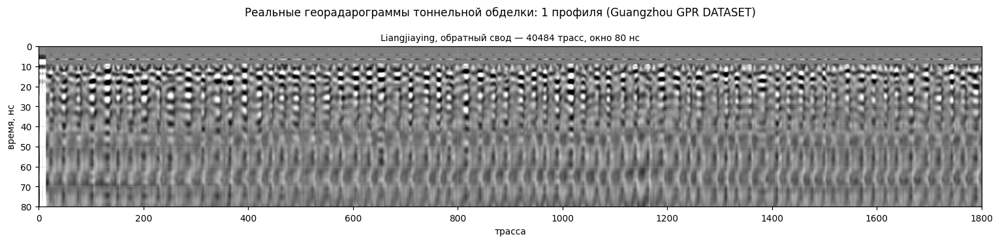

In [6]:
if dt_files:
    picks = []
    for line in ["GD", "ZBQ", "YG"]:
        cand = [f for f in dt_files
                if any(line in p for p in f.parts) and f.stat().st_size > 2_000_000]
        if cand:
            picks.append((line, cand[0]))

    fig, axes = plt.subplots(len(picks), 1, figsize=(14, 3.4 * len(picks)))
    for ax, (line, f) in zip(np.atleast_1d(axes), picks):
        n, tw = read_stc_params(f)
        data = read_ids_dt(f, n)
        if data is None:
            continue
        seg = gpr_normalize(data[:, :1800])
        ax.imshow(seg, cmap="gray", aspect="auto", vmin=-0.6, vmax=0.6,
                  extent=[0, seg.shape[1], tw * 1e9, 0])
        tunnel = next((TUNNEL_NAMES[t] for t in TUNNEL_NAMES if any(t in p for p in f.parts)), "?")
        ax.set_title(f"{tunnel}, {SCAN_LINES.get(line, line)} — {data.shape[1]} трасс, окно {tw*1e9:.0f} нс",
                     fontsize=9)
        ax.set_xlabel("трасса"); ax.set_ylabel("время, нс")
    plt.suptitle(f"Реальные георадарограммы тоннельной обделки: {len(picks)} профиля "
                 f"(Guangzhou GPR DATASET)", fontsize=11)
    plt.tight_layout(); plt.show()

На реальных данных видно то, чего нет в синтетике: сильная прямая волна вверху
кадра, горизонтальные полосы от аппаратуры, разное усиление вдоль профиля и более
шумный фон. Эти отличия и создают разницу между синтетикой и реальностью, которая
дальше измеряется численно.

Чтобы тоннельные записи можно было анализировать вместе с остальными наборами,
профили нарезаются на окна 512×512 и сохраняются как изображения.

In [7]:
if dt_files and not cache_ready(TILES_DIR, "*.jpg"):
    TILES_DIR.mkdir(parents=True, exist_ok=True)
    made = 0
    for f in dt_files:
        n, tw = read_stc_params(f)
        data = read_ids_dt(f, n)
        if data is None or data.shape[1] < 512:
            continue
        tunnel = next((t for t in TUNNEL_NAMES if any(t in p for p in f.parts)), "X")
        line = next((l for l in SCAN_LINES if any(l in p for p in f.parts)), "X")
        # берём не более 8 окон на профиль, равномерно по длине
        starts = np.linspace(0, data.shape[1] - 512, min(8, max(1, data.shape[1] // 512)), dtype=int)
        for k, s in enumerate(starts):
            tile = gpr_normalize(data[:, s:s + 512])
            img = Image.fromarray(((tile + 1) * 127.5).astype(np.uint8))
            # в имя обязательно входит и папка, и имя файла: в одной папке лежат
            # LID10001.dt и LID10002.dt, и без имени файла окна второго профиля
            # затирали бы окна первого
            name = f"{tunnel}_{line}_{f.parent.name[:12]}_{f.stem}_{k}.jpg"
            img.save(TILES_DIR / name, "JPEG", quality=95)
            made += 1
    print(f"нарезано окон: {made}")
elif cache_ready(TILES_DIR, "*.jpg"):
    print(f"окна уже нарезаны: {len(list(TILES_DIR.glob('*.jpg')))}")

окна уже нарезаны: 510


### 2.5. Пустоты с известным положением: данные Bureau of Reclamation

Пустоты — самый дефицитный класс в работе. В открытых наборах их либо мало (85 рамок
в URDD), либо они размечены только на уровне кадра. Набор **USBR Void Detection
Data** (проект S&T 21045, Бюро мелиорации США, опубликован 31.01.2025) интересен
тем, что пустоты в нём заложены специально и их положение известно.

Три площадки:

* **Exp2, Denver Federal Center** — испытательные бетонные плиты с заложенными
  пустотами. Плиты различаются армированием: без арматуры, одна сетка, две сетки,
  отдельные стержни. Опубликованы три сетки съёмки: `Project7-Grid1`, `-Grid2`,
  `-Grid3`.
* **Exp3, A-Canal (Кламат-Фоллс)** — реальная облицовка канала, снятая по своду
  (`Crown`) и стенам (`NW`, `SW`) — по той же схеме, что и тоннельная обделка.
* **Exp1, Glendo** — только измерения другим методом, георадара нет.

Файлы `.gpz` — это zip-архивы с данными **Sensors & Software (pulseEKKO / Noggin)**:
бинарный `.dt1` и текстовый заголовок `.HD`. Читаются просто, но есть две тонкости:

1. Размер отсчёта в заголовке не указан: на A-Canal это 2 байта, на плитах — 4.
   Он определяется по размеру файла.
2. Рядом с `.dt1` лежит `.dt1raw`. Файл `.dt1` уже обработан, и, судя по заметкам
   обработчика, участки с пенопластом в нём **заглушены** («Muted styrofoam portions
   of the y-lines b/c they were drowning out the desired signal — Muted positions
   (3.5ft to 6.5ft) (9.5ft to 12.5ft) (15.5ft to 18.5ft)»). Поэтому читается
   `.dt1raw`, где эти участки сохранены.

**Что сказано в заметках обработчика.** Все три файла `Grid N Processing Notes.docx`
были прочитаны, и картина в них менее оптимистичная, чем можно ожидать:

* Grid 2 и Grid 3: «In both of these blocks no obvious void signatures were found
  and the bottom of the slab could also not be resolved» — про блоки с сеткой;
  и отдельно про блок **без арматуры**: «no clear evidence of a void… It is
  strange to me that the slab with no reinforcement is not clearly resolving
  the void».
* Grid 4: единственное уверенное наблюдение пустоты во всём наборе, и оно сделано
  на плите **с арматурой**: «void signature – no polarity reversal… I would have
  said this was an air-filled void». Данных Grid 4 в публикации нет.

Выводы для работы. Первое: даже в контролируемом эксперименте специалист не увидел
пустоты ни на одной опубликованной сетке, включая плиту без арматуры. Второе:
замечание «no polarity reversal» подтверждает физику из раздела 1.2 — воздушная
пустота отражает без смены знака, и именно по этому признаку обработчик определил,
что пустота заполнена воздухом.

In [8]:
import zipfile
from PIL import Image

USBR_ROOT = DATA / "usbr_voids/extracted/Void Detection Data"
USBR_TILES = WORK / "usbr_tiles"
# отметки пенопластовых блоков вдоль y-линий, из заметок обработчика (в футах)
DFC_VOID_SPANS_FT = [(3.5, 6.5), (9.5, 12.5), (15.5, 18.5)]


def read_pulse_ekko(z: zipfile.ZipFile, hd_name: str, prefer_raw=True):
    """Чтение линии Sensors & Software из .gpz: заголовок .HD + бинарный .dt1.

    Запись трассы: 128 байт служебного заголовка + отсчёты. Разрядность отсчёта в
    заголовке не указана, поэтому подбирается по размеру файла (2 или 4 байта).
    """
    h = {}
    for line in z.read(hd_name).decode("latin-1").split("\n"):
        if "=" in line:
            k, v = line.split("=", 1)
            h[k.strip()] = v.strip()
    base = hd_name[:-3]
    order = [".dt1raw", ".dt1", ".DT1"] if prefer_raw else [".dt1", ".DT1", ".dt1raw"]
    names = set(z.namelist())
    name = next((base + e for e in order if base + e in names), None)
    if name is None:
        return None, h
    try:
        n = int(h["NUMBER OF PTS/TRC"]); nt = int(h["NUMBER OF TRACES"])
    except (KeyError, ValueError):
        return None, h
    raw = np.frombuffer(z.read(name), dtype=np.uint8)
    for dtype, size in (("<i2", 2), ("<i4", 4)):
        rec = 128 + n * size
        if rec and raw.size % rec == 0 and abs(raw.size // rec - nt) <= 1:
            body = raw.reshape(-1, rec)[:, 128:]
            return np.frombuffer(body.tobytes(), dtype=dtype).reshape(-1, n).T.astype(np.float32), h
    return None, h


def usbr_lines(gpz_path: Path):
    """Перечень линий внутри одного .gpz."""
    with zipfile.ZipFile(gpz_path) as z:
        return sorted(n for n in z.namelist() if n.lower().endswith(".hd"))


def gpr_prep(a, gain_power=0.8, clip=99.0):
    a = a - a.mean(axis=1, keepdims=True)
    g = (np.arange(a.shape[0]) + 1.0) ** gain_power
    a = a * g[:, None] / g.mean()
    p = np.percentile(np.abs(a), clip)
    return np.clip(a / max(p, 1e-6), -1, 1)

In [9]:
gpz_files = sorted(USBR_ROOT.rglob("*.gpz")) if USBR_ROOT.exists() else []
print(f"найдено проектов .gpz: {len(gpz_files)}")

usbr_inventory = []
if gpz_files:
    for gp in gpz_files:
        site = "DFC (плиты с пенопластом)" if "Exp2" in str(gp) else (
               "A-Canal (облицовка)" if "Exp3" in str(gp) else "прочее")
        with zipfile.ZipFile(gp) as z:
            hds = [n for n in z.namelist() if n.lower().endswith(".hd")]
            traces = pts = 0
            freq = tw = np.nan
            for hd in hds:
                d, h = read_pulse_ekko(z, hd)
                if d is None:
                    continue
                traces += d.shape[1]; pts = d.shape[0]
                freq = float(h.get("NOMINAL FREQUENCY", "nan"))
                tw = float(h.get("TOTAL TIME WINDOW", "nan"))
        usbr_inventory.append({"площадка": site, "проект": gp.stem, "линий": len(hds),
                               "трасс": traces, "отсчётов": pts,
                               "частота, МГц": freq, "окно, нс": tw})
    usbr_inv = pd.DataFrame(usbr_inventory)
    display(usbr_inv.groupby("площадка").agg(проектов=("проект", "size"), линий=("линий", "sum"),
                                             трасс=("трасс", "sum")).reset_index())
    print(f"суммарно трасс: {usbr_inv['трасс'].sum():,}; "
          f"частоты: {sorted(usbr_inv['частота, МГц'].dropna().unique())} МГц")

найдено проектов .gpz: 21


,площадка,проектов,линий,трасс
0,A-Canal (облицовка),18,798,1210029
1,DFC (плиты с пенопластом),3,106,24445


суммарно трасс: 1,234,474; частоты: [1000.0] МГц


#### Как выглядит пустота, положение которой известно заранее

Ниже — поперечная линия по испытательной плите. Оранжевым отмечены участки, где под
плитой лежат пенопластовые блоки. Отметки взяты из заметок обработчика, данные — без
обработки.

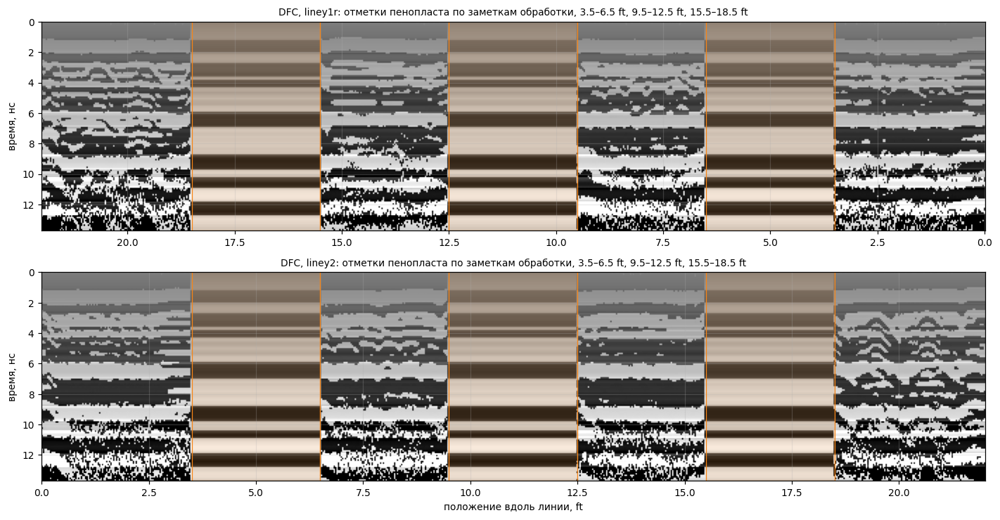

In [10]:
dfc = [g for g in gpz_files if "Exp2" in str(g)]
if dfc:
    with zipfile.ZipFile(dfc[0]) as z:
        ylines = [n for n in z.namelist() if n.lower().endswith(".hd") and "liney" in n.lower()]
        shown = 0
        fig, axes = plt.subplots(min(2, len(ylines)), 1, figsize=(13, 3.4 * min(2, len(ylines))))
        for ax, hd in zip(np.atleast_1d(axes), ylines[:2]):
            d, h = read_pulse_ekko(z, hd)
            if d is None:
                continue
            step = float(h["STEP SIZE USED"]); tw = float(h["TOTAL TIME WINDOW"])
            start = float(h.get("STARTING POSITION", 0))
            # шаг может быть отрицательным (линия снята в обратном направлении), а
            # начало — ненулевым: ось строится по фактическим координатам, иначе
            # отметки пенопласта лягут не туда, а симметрия трёх интервалов это скроет
            P = gpr_prep(d)
            ax.imshow(P, cmap="gray", aspect="auto", vmin=-0.8, vmax=0.8,
                      extent=[start, start + (P.shape[1] - 1) * step, tw, 0])
            for a0, b0 in DFC_VOID_SPANS_FT:
                ax.axvspan(a0, b0, color="#F58518", alpha=0.13)
                ax.axvline(a0, color="#F58518", lw=0.8); ax.axvline(b0, color="#F58518", lw=0.8)
            ax.set_title(f"DFC, {Path(hd).parent.name}: отметки пенопласта по заметкам обработки, "
                         f"{', '.join(f'{a}–{b} ft' for a, b in DFC_VOID_SPANS_FT)}", fontsize=9)
            ax.set_ylabel("время, нс"); shown += 1
        plt.xlabel("положение вдоль линии, ft")
        plt.tight_layout(); plt.show()

Внутри отмеченных участков отражение меняется: становится сильнее и сдвигается по
фазе. Но считать это откликом пустоты нельзя: по заметкам там лежит пенопласт, и
разница может объясняться им самим.

Сами авторы съёмки пустот на этих сетках не увидели — ни под сеткой, ни на плите без
армирования («It is strange to me that the slab with no reinforcement is not
clearly resolving the void»). Значит, дело не только в том, что арматура закрывает
пустоту: на частоте 1 ГГц её не увидели и там, где арматуры нет.

Поэтому этот набор не даёт надёжной разметки пустот. Зато он показывает, **насколько
задача трудная**: опытный специалист не выделил пустоты, даже зная, где они.
Сравнивать с этим результат модели имеет смысл, а обучать модель на такой разметке
как на истине — нет.

#### Реальная облицовка: свод и стены канала A-Canal

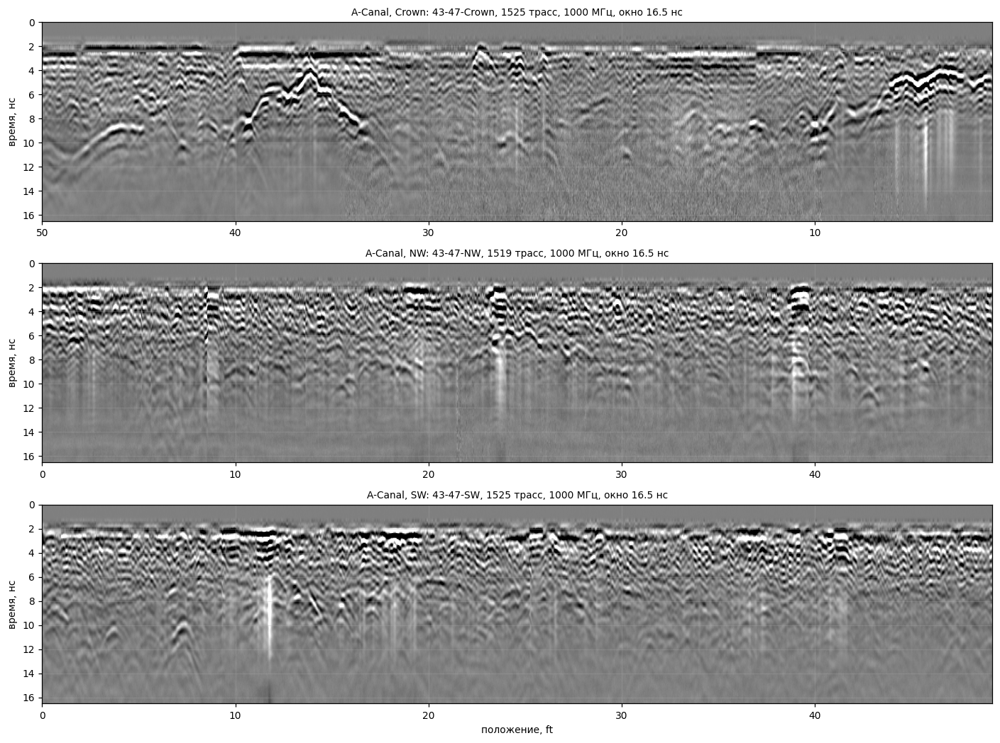

In [11]:
acanal = [g for g in gpz_files if "Exp3" in str(g)]
if acanal:
    picks = []
    for key in ["Crown", "NW", "SW"]:
        cand = [g for g in acanal if key in g.stem]
        if cand:
            picks.append((key, sorted(cand, key=lambda p: p.stat().st_size)[0]))
    fig, axes = plt.subplots(len(picks), 1, figsize=(13, 3.2 * len(picks)))
    for ax, (key, gp) in zip(np.atleast_1d(axes), picks):
        with zipfile.ZipFile(gp) as z:
            hd = next((n for n in sorted(z.namelist()) if n.lower().endswith(".hd")), None)
            d, h = read_pulse_ekko(z, hd)
        if d is None:
            continue
        tw = float(h["TOTAL TIME WINDOW"]); step = float(h["STEP SIZE USED"])
        start = float(h.get("STARTING POSITION", 0))
        P = gpr_prep(d[:, :1500])
        ax.imshow(P, cmap="gray", aspect="auto", vmin=-0.8, vmax=0.8,
                  extent=[start, start + (P.shape[1] - 1) * step, tw, 0])
        ax.set_title(f"A-Canal, {key}: {gp.stem}, {d.shape[1]} трасс, "
                     f"{h.get('NOMINAL FREQUENCY','?')} МГц, окно {tw} нс", fontsize=9)
        ax.set_ylabel("время, нс")
    plt.xlabel("положение, ft")
    plt.tight_layout(); plt.show()

Ряды одинаковых гипербол — это арматура облицовки. Частота 1 ГГц (у синтетики TunGPR
800 МГц), конструкция похожая: бетон с арматурной сеткой и заполнение за ним. Из всех
реальных наборов это самый близкий аналог тоннельной обделки после самих тоннельных
записей Guangzhou.

In [12]:
# Нарезка окон для общего анализа: как и для Guangzhou, кадры попадают в EDA и в
# оценку разрыва доменов наравне с остальными наборами.
if gpz_files and not cache_ready(USBR_TILES, "*.jpg"):
    USBR_TILES.mkdir(parents=True, exist_ok=True)
    made = 0
    for gp in gpz_files:
        site = "DFC" if "Exp2" in str(gp) else ("ACanal" if "Exp3" in str(gp) else "other")
        with zipfile.ZipFile(gp) as z:
            for hd in sorted(n for n in z.namelist() if n.lower().endswith(".hd")):
                d, h = read_pulse_ekko(z, hd)
                if d is None or d.shape[1] < 256:
                    continue
                starts = np.linspace(0, d.shape[1] - 256, min(2, max(1, d.shape[1] // 256)), dtype=int)
                for k, s in enumerate(starts):
                    tile = gpr_prep(d[:, s:s + 256])
                    img = Image.fromarray(((tile + 1) * 127.5).astype(np.uint8)).resize((256, 256))
                    # имена линий (linex0, liney1…) повторяются в каждой сетке каждого
                    # проекта, поэтому в имя окна идёт хеш полного пути внутри архива
                    uid = hashlib.md5(f"{gp.stem}/{hd}".encode()).hexdigest()[:10]
                    img.save(USBR_TILES / f"{site}_{uid}_{k}.jpg", "JPEG", quality=95)
                    made += 1
    print(f"нарезано окон: {made}")
elif cache_ready(USBR_TILES, "*.jpg"):
    print(f"окна уже нарезаны: {len(list(USBR_TILES.glob('*.jpg')))}")

окна уже нарезаны: 1635


#### Разметка пустот USBR: из текста отчёта в рамки

Из заметок обработчика берутся три участка вдоль каждой линии, и по ним строятся
рамки:

* **по горизонтали** — участок в футах пересчитывается в номера трасс по полям
  `STARTING POSITION` и `STEP SIZE USED` из заголовка;
* **по вертикали** — по трассам **вне** этих участков считается средняя энергия
  сигнала, после прямой волны в ней ищется главный максимум, и рамка строится в
  окне ±1.5 нс вокруг него.

**Ограничения такой разметки.** Участки `3.5–6.5`, `9.5–12.5`, `15.5–18.5 ft` взяты
из фразы про заглушение, и в заметках это положения **пенопласта**. Совпадают ли они
с заложенными пустотами, по опубликованным документам проверить нельзя: схемы
стенда в публикации нет. Вертикальная граница тоже приблизительная — на рисунке ниже
видно, что от линии к линии она заметно меняется.

Поэтому это **слабая разметка**, и эксперимент в разделе 11.15 проверяет, может ли
модель её воспроизвести, а не качество поиска пустот. Для настоящей проверки нужна
схема стенда (и данные Grid 4), которую имеет смысл запросить у авторов.

In [13]:
USBR_VOID = WORK / "usbr_void"

def dfc_label_line(d, h, spans_ft=DFC_VOID_SPANS_FT, half_ns=1.5, direct_ns=1.2):
    """Рамки пустот для одной y-линии DFC: (x0, x1, y0, y1) в долях кадра."""
    n_t, n_tr = d.shape
    tw = float(h["TOTAL TIME WINDOW"])
    start = float(h.get("STARTING POSITION", 0)); step = float(h["STEP SIZE USED"])
    pos = start + np.arange(n_tr) * step                       # положение трасс, ft
    t = np.linspace(0, tw, n_t)

    inside = np.zeros(n_tr, dtype=bool)
    for a0, b0 in spans_ft:
        inside |= (pos >= min(a0, b0)) & (pos <= max(a0, b0))
    if inside.sum() < 8 or (~inside).sum() < 8:
        return []

    proc = d - d.mean(axis=1, keepdims=True)
    energy = np.abs(proc[:, ~inside]).mean(axis=1)             # фон вне пустот
    energy[t < direct_ns] = 0                                  # прямую волну не берём
    k = int(np.argmax(energy))
    t_mid = t[k]
    y0, y1 = max(0.0, (t_mid - half_ns) / tw), min(1.0, (t_mid + half_ns) / tw)

    boxes = []
    for a0, b0 in spans_ft:
        m = (pos >= min(a0, b0)) & (pos <= max(a0, b0))
        if m.sum() < 4:
            continue
        i0, i1 = int(np.argmax(m)), int(len(m) - 1 - np.argmax(m[::-1]))
        boxes.append((i0 / n_tr, (i1 + 1) / n_tr, y0, y1))
    return boxes


def build_usbr_void_corpus(win=256, stride=64):
    """Нарезка окон со слабыми рамками; разбиение по сеткам съёмки.

    Grid2 и Grid3 идут в обучение, Grid1 — в контроль: разделение по сеткам, а не по
    окнам, иначе соседние окна одной линии попадут в обе части.
    """
    if (USBR_VOID / "data.yaml").exists() and cache_ready(USBR_VOID / "images" / "train"):
        return USBR_VOID / "data.yaml"
    counts = Counter()
    for gp in [g for g in gpz_files if "Exp2" in str(g)]:
        grid = gp.stem                                          # Project7-Grid2 и т.п.
        split = {"Project7-Grid2": "train", "Project7-Grid3": "train"}.get(grid, "val")
        with zipfile.ZipFile(gp) as z:
            for hd in sorted(n for n in z.namelist() if n.lower().endswith(".hd")
                             and "liney" in n.lower()):
                d, h = read_pulse_ekko(z, hd)
                if d is None or d.shape[1] < win:
                    continue
                boxes = dfc_label_line(d, h)
                if not boxes:
                    continue
                for s0 in range(0, d.shape[1] - win + 1, stride):
                    sub = gpr_prep(d[:, s0:s0 + win])
                    img_dir = USBR_VOID / "images" / split
                    lbl_dir = USBR_VOID / "labels" / split
                    img_dir.mkdir(parents=True, exist_ok=True)
                    lbl_dir.mkdir(parents=True, exist_ok=True)
                    uid = hashlib.md5(f"{grid}/{hd}/{s0}".encode()).hexdigest()[:12]
                    Image.fromarray(((sub + 1) * 127.5).astype(np.uint8)).resize((512, 512)) \
                         .save(img_dir / f"{uid}.jpg", "JPEG", quality=95)
                    lines = []
                    for x0, x1, y0, y1 in boxes:
                        # переводим рамку линии в координаты окна
                        bx0 = (x0 * d.shape[1] - s0) / win
                        bx1 = (x1 * d.shape[1] - s0) / win
                        bx0, bx1 = max(0.0, bx0), min(1.0, bx1)
                        if bx1 - bx0 < 0.06:                    # обрезки по краям не берём
                            continue
                        xc, w = (bx0 + bx1) / 2, bx1 - bx0
                        yc, hgt = (y0 + y1) / 2, y1 - y0
                        lines.append(f"0 {xc:.6f} {yc:.6f} {w:.6f} {hgt:.6f}")
                        counts[(split, "рамок")] += 1
                    (lbl_dir / f"{uid}.txt").write_text("\n".join(lines))
                    counts[(split, "кадров")] += 1
    if not counts:
        return None
    with open(USBR_VOID / "data.yaml", "w") as fh:
        fh.write(f"path: {USBR_VOID.resolve()}\ntrain: images/train\nval: images/val\n\nnames:\n  0: void\n")
    rows = defaultdict(dict)
    for (split, what), v in counts.items():
        rows[what][split] = v
    display(pd.DataFrame(rows).T.fillna(0).astype(int).rename_axis("USBR_VOID"))
    return USBR_VOID / "data.yaml"


usbr_void_yaml = build_usbr_void_corpus() if gpz_files else None
print("корпус пустот USBR:", usbr_void_yaml)

корпус пустот USBR: /home/ubuntu/projects/ml/rzhd/work/usbr_void/data.yaml


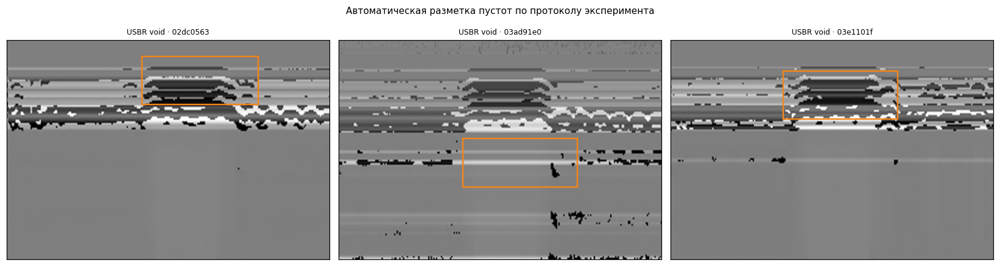

In [14]:
# Проверяем разметку глазами: три кадра с наложенными рамками
if usbr_void_yaml:
    import matplotlib.patches as mp
    imgs = sorted((USBR_VOID / "images" / "train").glob("*.jpg"))
    picked = [p for p in imgs if (USBR_VOID / "labels" / "train" / f"{p.stem}.txt").read_text().strip()][:3]
    if picked:
        fig, axes = plt.subplots(1, len(picked), figsize=(5 * len(picked), 4))
        for ax, p in zip(np.atleast_1d(axes), picked):
            ax.imshow(np.asarray(Image.open(p)), cmap="gray", aspect="auto")
            for line in (USBR_VOID / "labels" / "train" / f"{p.stem}.txt").read_text().split("\n"):
                if not line.strip():
                    continue
                _, xc, yc, w, hgt = (float(v) for v in line.split())
                ax.add_patch(mp.Rectangle(((xc - w / 2) * 512, (yc - hgt / 2) * 512),
                                          w * 512, hgt * 512, fill=False,
                                          edgecolor="#F58518", lw=1.6))
            ax.set_title(f"USBR void · {p.stem[:8]}", fontsize=8)
            ax.set_xticks([]); ax.set_yticks([])
        plt.suptitle("Автоматическая разметка пустот по протоколу эксперимента", fontsize=10)
        plt.tight_layout(); plt.show()

### 2.6. Пустоты в бетонной кладке: наборы GPRbase

GPRbase — библиотека реальных георадарограмм, снятых аппаратурой GSSI на настоящих
бетонных конструкциях. Файлы выдаются по запросу через форму на сайте, лицензия
**CC BY-NC-SA 4.0**: только некоммерческое использование со ссылкой на источник.
Для учебной работы это подходит, для коммерческого продукта — нет.

Взяты четыре набора:

| Набор | Что снято | Зачем |
|---|---|---|
| `ds014` | профиль стены из бетонных блоков с пустотами | пустота в кладке с известным положением |
| `ds001` | та же стена, трёхмерная съёмка, два канала | те же пустоты в плане |
| `ds009` | железобетон с двумя слоями арматурной сетки | пример, когда плотная сетка закрывает всё под собой |
| `ds004` | двойное армирование и смена конструкции | примеры без дефектов и переход между зонами |

Формат — GSSI `.DZT` плюс файл метаданных `.DZX`. Две тонкости при чтении:

1. Начало данных задаётся полем `rh_data`: смещение равно `1024 × rh_data`, здесь
   131 072 байта, а не обычные 1024.
2. При `rh_bits = 32` отсчёты — **знаковые** `int32`. Если читать их как
   беззнаковые, картинка выглядит правдоподобно, но полностью испорчена.

In [15]:
from PIL import Image

GPRBASE_ROOT = DATA / "gprbase"
GPRBASE_TILES = WORK / "gprbase_tiles"

DZT_DTYPE = {8: ("<u1", 128.0), 16: ("<u2", 32768.0), 32: ("<i4", 0.0)}


def read_dzt(path):
    """Чтение георадарограммы GSSI (.DZT). Возвращает (отсчёты × трассы) и заголовок."""
    raw = np.fromfile(path, dtype=np.uint8)
    if raw.size < 1024:
        return None, {}
    g = lambda o, t: np.frombuffer(raw[o:o + np.dtype(t).itemsize].tobytes(), dtype=t)[0]
    nsamp, bits, rh_data = int(g(4, "<u2")), int(g(6, "<u2")), int(g(2, "<u2"))
    if bits not in DZT_DTYPE or not nsamp:
        return None, {}
    hdr = dict(nsamp=nsamp, bits=bits, range_ns=float(g(26, "<f4")),
               scans_per_m=float(g(14, "<f4")), scans_per_s=float(g(10, "<f4")))
    off = 1024 * rh_data if rh_data else 1024
    dt, zero = DZT_DTYPE[bits]
    per = nsamp * (bits // 8)
    body = raw[off:]
    ntr = len(body) // per
    if ntr < 8:
        return None, hdr
    a = (np.frombuffer(body[:ntr * per].tobytes(), dtype=dt)
           .reshape(ntr, nsamp).T.astype(np.float32)) - zero
    hdr["traces"] = ntr
    return a, hdr


def dzx_meta(dzt_path):
    """Немного метаданных из сопутствующего XML: прибор и диэлектрическая проницаемость."""
    for cand in (Path(str(dzt_path)[:-4] + ".DZX"), Path(str(dzt_path)[:-4] + ".dzx")):
        if cand.exists():
            t = cand.read_bytes().decode("utf-8", "replace")
            out = {}
            for tag in ("system", "dielectric", "unitsPerScan"):
                i = t.find(f"<{tag}>")
                if i >= 0:
                    out[tag] = t[i + len(tag) + 2: t.find(f"</{tag}>", i)]
            return out
    return {}

In [16]:
dzt_files = sorted(GPRBASE_ROOT.rglob("*.dzt")) + sorted(GPRBASE_ROOT.rglob("*.DZT")) \
    if GPRBASE_ROOT.exists() else []
dzt_files = sorted(set(dzt_files))
print(f"найдено файлов GSSI: {len(dzt_files)}")

if dzt_files:
    rows = []
    for f in dzt_files:
        a, h = read_dzt(f)
        if a is None:
            continue
        m = dzx_meta(f)
        ds = next((p for p in f.parts if p.startswith("gprbase.com-")), "?").replace("gprbase.com-", "")
        rows.append({"набор": ds, "файл": f.name, "отсчётов": h["nsamp"], "трасс": h["traces"],
                     "окно, нс": round(h["range_ns"], 1),
                     "трасс на метр": round(h["scans_per_m"], 0),
                     "прибор": m.get("system", ""), "ε по прибору": m.get("dielectric", "")})
    gprbase_inv = pd.DataFrame(rows)
    display(gprbase_inv.groupby("набор").agg(файлов=("файл", "size"), трасс=("трасс", "sum"),
                                             окно_нс=("окно, нс", "median")).reset_index())
    print(f"суммарно трасс: {gprbase_inv['трасс'].sum():,}")

найдено файлов GSSI: 80


,набор,файлов,трасс,окно_нс
0,ds001,51,12291,25.0
1,ds004,1,658,10.6
2,ds009,26,6266,11.1
3,ds014,1,2908,25.0


суммарно трасс: 22,123


Ниже два набора рядом: стена с пустотами и железобетон с двойной сеткой. Под
плотной сеткой всё, что глубже, закрыто её отражениями.

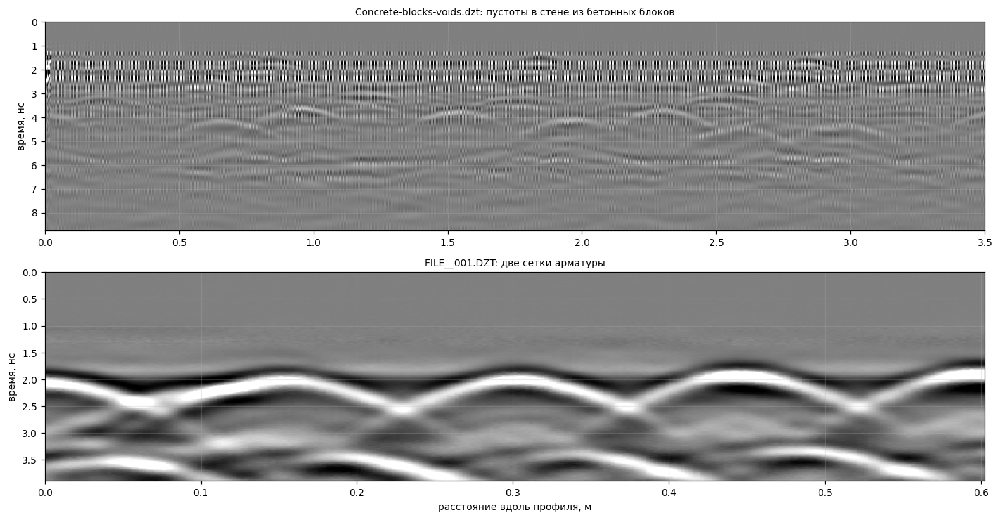

In [17]:
def gprbase_prep(a, gain_power=1.0, clip=99.0):
    a = a - a.mean(axis=1, keepdims=True)
    g = (np.arange(a.shape[0]) + 1.0) ** gain_power
    a = a * g[:, None] / g.mean()
    return np.clip(a / max(np.percentile(np.abs(a), clip), 1e-6), -1, 1)


if dzt_files:
    picks = []
    for key, title in [("ds014", "пустоты в стене из бетонных блоков"),
                       ("ds009", "две сетки арматуры")]:
        f = next((x for x in dzt_files if key in str(x)), None)
        if f:
            picks.append((f, title))
    fig, axes = plt.subplots(len(picks), 1, figsize=(13, 3.4 * len(picks)))
    for ax, (f, title) in zip(np.atleast_1d(axes), picks):
        a, h = read_dzt(f)
        if a is None:
            continue
        # для тонких конструкций полезен только верх временного окна
        keep = max(64, int(a.shape[0] * 0.35))
        P = gprbase_prep(a[:keep, :1400])
        ax.imshow(P, cmap="gray", aspect="auto", vmin=-0.8, vmax=0.8,
                  extent=[0, P.shape[1] / max(h["scans_per_m"], 1), h["range_ns"] * keep / a.shape[0], 0])
        ax.set_title(f"{f.name}: {title}", fontsize=9)
        ax.set_ylabel("время, нс")
    plt.xlabel("расстояние вдоль профиля, м")
    plt.tight_layout(); plt.show()

In [18]:
# Нарезка окон для общего анализа доменов
# Ширина окна подбирается под линию, а не фиксируется. Это важно: в этом наборе
# 77 файлов из 80 содержат ровно 241 трассу, и жёсткое окно в 256 трасс отбрасывало
# их все — набор попадал в ноутбук, но в анализ доменов не входил.
GPRBASE_WIN = 192          # трасс в окне; кадр всё равно масштабируется до 256×256
GPRBASE_MIN = 128          # короче этого линию не режем

if dzt_files and not cache_ready(GPRBASE_TILES, "*.jpg"):
    GPRBASE_TILES.mkdir(parents=True, exist_ok=True)
    made, skipped = 0, 0
    for f in dzt_files:
        a, h = read_dzt(f)
        if a is None or a.shape[1] < GPRBASE_MIN:
            skipped += 1
            continue
        keep = max(64, int(a.shape[0] * 0.35))
        a = a[:keep]
        win = min(GPRBASE_WIN, a.shape[1])
        ds = next((p for p in f.parts if p.startswith("gprbase.com-")), "ds").replace("gprbase.com-", "")
        n_win = min(4, max(1, a.shape[1] // win))
        starts = np.linspace(0, a.shape[1] - win, n_win, dtype=int)
        for k, s in enumerate(starts):
            tile = gprbase_prep(a[:, s:s + win])
            img = Image.fromarray(((tile + 1) * 127.5).astype(np.uint8)).resize((256, 256))
            uid = hashlib.md5(f"{f}|{k}".encode()).hexdigest()[:10]
            img.save(GPRBASE_TILES / f"{ds}_{uid}.jpg", "JPEG", quality=95)
            made += 1
    print(f"нарезано окон: {made}; пропущено коротких линий: {skipped}")
elif cache_ready(GPRBASE_TILES, "*.jpg"):
    print(f"окна уже нарезаны: {len(list(GPRBASE_TILES.glob('*.jpg')))}")

окна уже нарезаны: 84


### 2.7. Реестр наборов и общая таблица

Каждому набору приписываются свойства, которые дальше используются при разбиении и
анализе: происхождение (`synthetic` / `field`), тип конструкции (`tunnel` / `road` /
`concrete` / `pavement`) и частота антенны. Частота важна: при 200 МГц и при
1600 МГц одни и те же объекты выглядят в совершенно разном масштабе, и модель,
обученная на одной частоте, не обязана работать на другой.

In [19]:
REGISTRY = [
    # (имя, загрузчик, аргументы, метаданные)
    dict(name="tungpr_lining", loader="voc", root=DATA / "tungpr/lining",
         origin="synthetic", structure="tunnel", freq_mhz=800,
         note="FDTD-модели обделки: арматура, границы сред, пустоты, вода, расслоение"),
    dict(name="tungpr_hyperbola", loader="voc", root=DATA / "tungpr/hyperbola",
         origin="synthetic", structure="tunnel", freq_mhz=800,
         note="отдельная часть TunGPR: только гиперболические сигнатуры"),
    dict(name="urdd", loader="yolo", root=DATA / "urdd/extracted/DURDD",
         img_sub="JPEGImages", lbl_sub="TXT",
         names=["Cavity", "Detachment", "Looseness", "Water-rich"],
         origin="field", structure="road", freq_mhz=200,
         note="реальные городские дороги, размечены пустоты/отслоение/разуплотнение/вода"),
    dict(name="pgpr", loader="yolo", root=DATA / "pgpr/dataset",
         img_sub=".", lbl_sub=".", names=["steel", "pipe"],
         origin="field", structure="concrete", freq_mhz=1600,
         note="реальные бетонные стены: арматура против труб"),
    # Morocco размечен только в аугментированных папках, и в каждой из них класс
    # записан как id 0 — пространства меток у папок разные. Поэтому два отдельных
    # входа, иначе коммуникации превратятся в полости.
    dict(name="morocco_cavity", loader="yolo", root=DATA / "morocco/GPR_data/augmented_cavities",
         img_sub=".", lbl_sub="annotations/Yolo_format", names=["Cavity"],
         origin="field", structure="urban", freq_mhz=300,
         note="реальные съёмки 200/400 МГц, полости; изображения — аугментированные патчи 224×224"),
    dict(name="morocco_utility", loader="yolo", root=DATA / "morocco/GPR_data/augmented_utilities",
         img_sub=".", lbl_sub="annotations/YOLO_format", names=["Utility"],
         origin="field", structure="urban", freq_mhz=300,
         note="те же съёмки, подземные коммуникации"),
    dict(name="rebar_yolo", loader="yolo",
         root=DATA / "rebar_yolo/extracted/rebars_yolov11_No_augmentation",
         img_sub=".", lbl_sub=".", names=["bar"],
         origin="field", structure="concrete", freq_mhz=np.nan,
         note="сводный набор арматуры из открытых источников (в т.ч. SDNET2021, "
              "FHWA InfoBridge) — при объединении возможны пересечения"),
    dict(name="cracks_lgsc", loader="yolo", root=DATA / "subsurface_cracks/Data/GPR_LGSC",
         img_sub=".", lbl_sub=".", names=["crack"],
         origin="field", structure="pavement", freq_mhz=1000,
         note="подповерхностные трещины дорожной одежды (LTPP)"),
    dict(name="cracks_pgsc", loader="yolo", root=DATA / "subsurface_cracks/Data/GPR_PGSC",
         img_sub=".", lbl_sub=".", names=["crack"],
         origin="field", structure="pavement", freq_mhz=1600,
         note="подповерхностные трещины, вторая площадка"),
    dict(name="tigpr", loader="folders", root=DATA / "tigpr/TIGPR/Damage Classification",
         origin="field", structure="mixed", freq_mhz=np.nan,
         note="реальные кадры 200×200, 5 классов по папкам: Crack, Void, Loose, "
              "Interlayer_bonding_deficiency, No_damage; рамок нет"),
    dict(name="gprbase_concrete", loader="images", root=WORK / "gprbase_tiles",
         origin="field", structure="concrete", freq_mhz=np.nan,
         note="GPRbase: стена из бетонных блоков с пустотами и железобетон с двойной "
              "арматурной сеткой; лицензия CC BY-NC-SA 4.0, только некоммерческое использование"),
    dict(name="usbr_lining", loader="images", root=WORK / "usbr_tiles",
         origin="field", structure="lining", freq_mhz=1000,
         note="USBR: облицовка канала (свод/стены) и плиты с пенопластовыми пустотами; "
              "положение пустот известно, но рамочной разметки нет"),
    dict(name="guangzhou_tunnel", loader="images", root=WORK / "guangzhou_tiles",
         origin="field", structure="tunnel", freq_mhz=np.nan,
         note="реальные обделки трёх тоннелей, окна 512×512 из сырых .dt; разметки нет"),
    dict(name="composite_lining", loader="images", root=DATA / "composite_lining/png",
         origin="field", structure="tunnel", freq_mhz=np.nan,
         note="реальные разрезы сборной обделки, разметки нет"),
]


def build_annotations():
    rows, missing = [], []
    for spec in REGISTRY:
        root = spec["root"]
        meta = dict(origin=spec["origin"], structure=spec["structure"], freq_mhz=spec["freq_mhz"])
        if not root.exists():
            missing.append(spec["name"])
            continue
        if spec["loader"] == "voc":
            r = load_voc(root, spec["name"], **meta)
        elif spec["loader"] == "yolo":
            img_root = root / spec["img_sub"] if spec["img_sub"] != "." else root
            lbl_root = root / spec["lbl_sub"] if spec["lbl_sub"] != "." else root
            r = load_yolo(img_root, lbl_root, spec["names"], spec["name"], **meta)
        elif spec["loader"] == "folders":
            r = load_folder_classes(root, spec["name"], **meta)
        else:
            r = load_images_only(root, spec["name"], **meta)
        if not r:
            missing.append(spec["name"])
        rows += r
    return pd.DataFrame(rows), missing


ann, missing = build_annotations()
ann["image"] = ann["image"].astype(str)

print("не найдено / пусто:", ", ".join(missing) if missing else "—")
print(f"всего объектов разметки: {len(ann)}, изображений: {ann['image'].nunique()}")

summary = (ann.groupby(["dataset", "origin", "structure"])
             .agg(изображений=("image", "nunique"), объектов=("cls", "size"),
                  классов=("cls", "nunique"))
             .reset_index()
             .sort_values("объектов", ascending=False))
display(summary)

не найдено / пусто: cracks_lgsc, cracks_pgsc
всего объектов разметки: 31113, изображений: 15469


,dataset,origin,structure,изображений,объектов,классов
6,rebar_yolo,field,concrete,2528,11664,1
7,tigpr,field,mixed,7169,7169,5
9,tungpr_lining,synthetic,tunnel,852,5769,6
11,usbr_lining,field,lining,1635,1635,0
5,pgpr,field,concrete,273,1490,2
4,morocco_utility,field,urban,786,1007,1
10,urdd,field,road,527,620,4
3,morocco_cavity,field,urban,553,600,1
8,tungpr_hyperbola,synthetic,tunnel,537,550,1
2,guangzhou_tunnel,field,tunnel,510,510,0


In [20]:
# Распределение классов внутри каждого набора
cls_table = (ann.dropna(subset=["cls"])
               .groupby(["dataset", "cls"]).size()
               .unstack(fill_value=0))
display(cls_table)

cls,Cavity,Crack,Detachment,Interlayer_bonding_deficiency,Loose,Looseness,No_damage,Utility,Void,Water-rich,air_void,bar,grout_surface,hyperbola,pipe,rebar,rock_surface,separation,steel,water_void
dataset,,,,,,,,,,,,,,,,,,,,
morocco_cavity,600,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
morocco_utility,0,0,0,0,0,0,0,1005,0,0,0,0,0,0,0,0,0,0,0,0
pgpr,0,0,0,0,0,0,0,0,0,0,0,0,0,0,379,0,0,0,1111,0
rebar_yolo,0,0,0,0,0,0,0,0,0,0,0,11644,0,0,0,0,0,0,0,0
tigpr,0,1224,0,2020,2100,0,1520,0,305,0,0,0,0,0,0,0,0,0,0,0
tungpr_hyperbola,0,0,0,0,0,0,0,0,0,0,0,0,0,550,0,0,0,0,0,0
tungpr_lining,0,0,0,0,0,0,0,0,0,0,194,0,852,0,0,3408,852,284,0,179
urdd,85,0,414,0,0,115,0,0,0,6,0,0,0,0,0,0,0,0,0,0


### 2.8. Своя синтетика под частоту дорожных данных (gprMax, 200 МГц)

В разделе 11 выясняется, что предобучение на TunGPR **ухудшает** поиск пустот в
дорожном наборе на 11–12 п.п., хотя в среднем по классам помогает. Возможная причина:
в TunGPR пустота — небольшой контрастный объект в бетоне при 800 МГц, а в URDD —
длинная слабоконтрастная зона под дорожным покрытием при 200 МГц. Модель переносит
неверное представление о том, как выглядит пустота.

Чтобы это проверить, генерируется своя синтетика **с параметрами дорожной съёмки**, и
два предобучения сравниваются на одной задаче.

Параметры модели (gprMax 4, генератор в `tools/gen_gprmax200.py`):

| Параметр | Значение | Почему так |
|---|---|---|
| частота | 200 МГц, импульс Рикера | как у URDD |
| шаг сетки | 1 см | 11 ячеек на длину волны в самом «медленном» материале (ε = 20) |
| окно по времени | 75 нс | захватывает дорожную конструкцию и верх грунта |
| профиль | 48 трасс с шагом 10 см | 4.8 м, как фрагмент дорожного профиля |
| конструкция | покрытие 8–20 см (ε 4–7), основание 25–55 см (ε 7–12), грунт (ε 6–16) | параметры случайные в каждой сцене |
| пустота | в 60% сцен: длина 0.25–1.4 м, высота 4–25 см | размеры из литературы по дорожным провалам |
| заполнение | воздух, влажный песок (ε 20), разуплотнение (ε 4.5) | три разных контраста |

Воду (ε = 81) не моделировали: при 200 МГц для неё нужна сетка 5 мм и примерно в
8 раз больше вычислений. Вместо воды используется влажный песок.

Разметка получается из самой модели: положение пустоты известно точно и
пересчитывается в номера трасс и время прихода. Это точная истина, а не
интерпретация.

In [21]:
import shutil, json
from PIL import Image

ROAD200_RAW = WORK / "src_road200"
ROAD200 = WORK / "src_road200_yolo"

def road200_to_yolo(raw_dir: Path, out_dir: Path, height=512, width=512, val_frac=0.2):
    """Перевод сырых профилей gprMax в YOLO-корпус с одним классом `void`."""
    metas = sorted((raw_dir / "meta").glob("*.json"))
    if not metas:
        return None, {}
    if out_dir.exists():
        shutil.rmtree(out_dir)
    counts = Counter()
    rng = np.random.default_rng(SEED)
    for m in metas:
        meta = json.loads(m.read_text())
        arr = np.load(raw_dir / "npy" / f"{m.stem}.npy")
        if arr.ndim != 2 or arr.shape[1] < 8:
            continue
        # убираем прямую волну и выравниваем затухание, затем приводим к 512×512
        a = arr - arr.mean(axis=1, keepdims=True)
        g = (np.arange(a.shape[0]) + 1.0) ** 1.4
        a = a * g[:, None] / g.mean()
        a = np.clip(a / max(np.percentile(np.abs(a), 99.5), 1e-12), -1, 1)
        img = Image.fromarray(((a + 1) * 127.5).astype(np.uint8)).resize((width, height))
        split = "val" if rng.random() < val_frac else "train"
        (out_dir / "images" / split).mkdir(parents=True, exist_ok=True)
        (out_dir / "labels" / split).mkdir(parents=True, exist_ok=True)
        img.save(out_dir / "images" / split / f"{m.stem}.jpg", "JPEG", quality=95)

        lines = []
        lab = meta.get("label")
        if lab:
            n_tr = meta["n_traces"]; tw = meta["time_window"]
            x0, x1 = lab["i0"] / n_tr, (lab["i1"] + 1) / n_tr
            y0, y1 = lab["t_top"] / tw, lab["t_bot"] / tw
            y0, y1 = max(0.0, min(1.0, y0)), max(0.0, min(1.0, y1))
            if x1 > x0 and y1 > y0:
                lines.append(f"0 {(x0+x1)/2:.6f} {(y0+y1)/2:.6f} {x1-x0:.6f} {y1-y0:.6f}")
                counts[(split, f"void/{lab['fill']}")] += 1
        (out_dir / "labels" / split / f"{m.stem}.txt").write_text("\n".join(lines))
        counts[(split, "кадров")] += 1

    with open(out_dir / "data.yaml", "w") as fh:
        fh.write(f"path: {out_dir.resolve()}\ntrain: images/train\nval: images/val\n\nnames:\n  0: void\n")
    return out_dir / "data.yaml", counts


road200_yaml, road200_counts = road200_to_yolo(ROAD200_RAW, ROAD200)
if road200_yaml:
    rows = defaultdict(dict)
    for (split, what), v in road200_counts.items():
        rows[what][split] = v
    display(pd.DataFrame(rows).T.fillna(0).astype(int).rename_axis("SRC_ROAD200"))
    print("корпус синтетики 200 МГц:", road200_yaml)
else:
    print("синтетика 200 МГц не найдена — раздел пропускается "
          "(сгенерировать: python3 tools/gen_gprmax200.py --n 180 --workers 8)")

,train,val
SRC_ROAD200,,
кадров,109,31
void/air,27,9
void/loose,18,3
void/wet_sand,16,5


корпус синтетики 200 МГц: /home/ubuntu/projects/ml/rzhd/work/src_road200_yolo/data.yaml


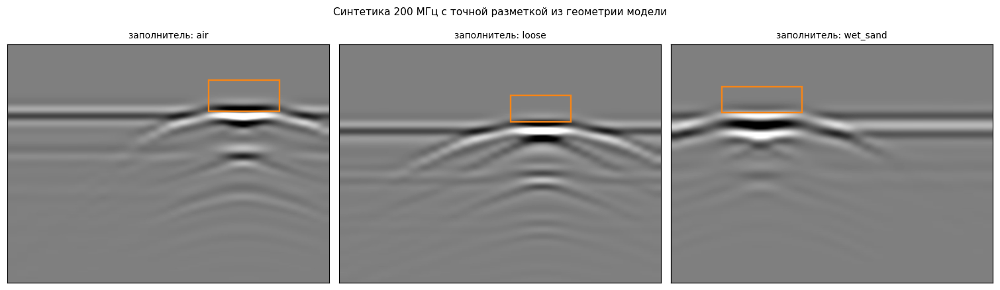

In [22]:
# Как выглядит своя синтетика: кадры с пустотами разного заполнения
if road200_yaml:
    import matplotlib.patches as mpatch
    metas = sorted((ROAD200_RAW / "meta").glob("*.json"))
    shown, fills = [], set()
    for m in metas:
        lab = json.loads(m.read_text()).get("label")
        if lab and lab["fill"] not in fills:
            fills.add(lab["fill"]); shown.append((m.stem, lab))
        if len(shown) == 3:
            break
    if shown:
        fig, axes = plt.subplots(1, len(shown), figsize=(4.6 * len(shown), 4))
        for ax, (stem, lab) in zip(np.atleast_1d(axes), shown):
            p = next((ROAD200 / "images" / s / f"{stem}.jpg" for s in ("train", "val")
                      if (ROAD200 / "images" / s / f"{stem}.jpg").exists()), None)
            if p is None:
                continue
            ax.imshow(np.asarray(Image.open(p)), cmap="gray", aspect="auto")
            meta = json.loads((ROAD200_RAW / "meta" / f"{stem}.json").read_text())
            x0 = lab["i0"] / meta["n_traces"] * 512
            x1 = (lab["i1"] + 1) / meta["n_traces"] * 512
            y0 = lab["t_top"] / meta["time_window"] * 512
            y1 = lab["t_bot"] / meta["time_window"] * 512
            ax.add_patch(mpatch.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False,
                                          edgecolor="#F58518", lw=1.6))
            ax.set_title(f"заполнитель: {lab['fill']}", fontsize=9)
            ax.set_xticks([]); ax.set_yticks([])
        plt.suptitle("Синтетика 200 МГц с точной разметкой из геометрии модели", fontsize=10)
        plt.tight_layout(); plt.show()

---
## 3. Разведочный анализ данных (EDA)

Вопросы этого раздела:

1. Насколько несбалансированы классы и как это влияет на выбор метрик.
2. Какого размера объекты — от этого зависят разрешение входа и архитектура
   детектора.
3. На какой глубине лежат объекты: ось Y — это глубина, и если класс всегда на
   одной глубине, модель может запомнить положение вместо формы сигнала.
4. Насколько наборы отличаются по яркости — это оценка того, насколько трудным будет
   перенос между ними.
5. Нет ли технических утечек: дубликатов кадров, разных форматов файлов у разных
   классов.

In [23]:
# Разметка в наборах разного типа, и складывать её в одну кучу нельзя:
#   * рамка (bbox) — объект с координатами;
#   * метка кадра — класс без локализации (TIGPR);
#   * кадр без разметки вообще (реальные тоннельные записи).
if "empty_label" not in ann.columns:
    ann["empty_label"] = False
ann["empty_label"] = ann["empty_label"].fillna(False).astype(bool)
# Пустой файл разметки и отсутствие файла — разные вещи: первое означает «эксперт
# посмотрел и не нашёл ничего», второе — «неизвестно». Для обучения первое полезно
# как отрицательный пример, второе бесполезно.
ann["ann_kind"] = np.where(ann["xc"].notna(), "рамка",
                    np.where(ann["cls"].notna(), "метка кадра",
                      np.where(ann["empty_label"], "проверенный пустой кадр", "без разметки")))

frames = (ann.groupby(["dataset", "image", "origin", "structure", "freq_mhz"], dropna=False)
            .agg(boxes=("ann_kind", lambda s: (s == "рамка").sum()),
                 width=("width", "first"), height=("height", "first"),
                 kind=("ann_kind", "first"))
            .reset_index())
frames["ext"] = frames["image"].map(lambda p: Path(p).suffix.lower())
frames["aspect"] = frames["width"] / frames["height"]

print(f"кадров всего: {len(frames)}; из них с рамками: {(frames['boxes'] > 0).sum()}")
if rejected:
    print("отклонено при загрузке:", dict(rejected))
display(frames.groupby(["dataset", "kind"]).agg(
    кадров=("image", "size"),
    рамок=("boxes", "sum"),
    рамок_на_кадр=("boxes", "mean"),
    ширина=("width", "median"),
    высота=("height", "median"),
).round(2))

кадров всего: 15469; из них с рамками: 6034
отклонено при загрузке: {'нулевая или нечисловая рамка': 2}


кадров  рамок  рамок_на_кадр  \
dataset          kind                                                    
composite_lining без разметки                 15      0           0.00   
gprbase_concrete без разметки                 84      0           0.00   
guangzhou_tunnel без разметки                510      0           0.00   
morocco_cavity   рамка                       553    600           1.08   
morocco_utility  проверенный пустой кадр       2      0           0.00   
                 рамка                       784   1005           1.28   
pgpr             рамка                       273   1490           5.46   
rebar_yolo       проверенный пустой кадр      20      0           0.00   
                 рамка                      2508  11644           4.64   
tigpr            метка кадра                7169      0           0.00   
tungpr_hyperbola рамка                       537    550           1.02   
tungpr_lining    рамка                       852   5769           6.77   
urdd             рамка                       527    620           1.18   
usbr_lining      без разметки               1635      0           0.00   

                                          ширина  высота  
dataset          kind                                     
composite_lining без разметки             1197.0   530.0  
gprbase_concrete без разметки              256.0   256.0  
guangzhou_tunnel без разметки              512.0   512.0  
morocco_cavity   рамка                     224.0   224.0  
morocco_utility  проверенный пустой кадр   224.0   224.0  
                 рамка                     224.0   224.0  
pgpr             рамка                     889.0   256.0  
rebar_yolo       проверенный пустой кадр   320.0   320.0  
                 рамка                     320.0   320.0  
tigpr            метка кадра               200.0   200.0  
tungpr_hyperbola рамка                     512.0   512.0  
tungpr_lining    рамка                     512.0   512.0  
urdd             рамка                    1763.0   548.0  
usbr_lining      без разметки              256.0   256.0

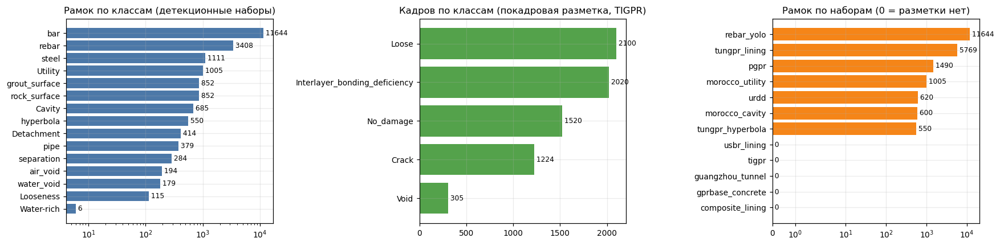

дисбаланс рамок: bar (11644) против Water-rich (6) — 1941:1
редкие классы (<100 рамок): Water-rich
наборов без разметки: composite_lining, gprbase_concrete, guangzhou_tunnel, tigpr, usbr_lining


In [24]:
# Распределение классов: отдельно рамки, отдельно покадровые метки
boxes_cnt = ann[ann.ann_kind == "рамка"]["cls"].value_counts()
frame_cnt = ann[ann.ann_kind == "метка кадра"]["cls"].value_counts()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].barh(boxes_cnt.index[::-1], boxes_cnt.values[::-1], color="#4C78A8")
axes[0].set_title("Рамок по классам (детекционные наборы)"); axes[0].set_xscale("log")
for i, v in enumerate(boxes_cnt.values[::-1]):
    axes[0].text(v, i, f" {v}", va="center", fontsize=8)

if len(frame_cnt):
    axes[1].barh(frame_cnt.index[::-1], frame_cnt.values[::-1], color="#54A24B")
    axes[1].set_title("Кадров по классам (покадровая разметка, TIGPR)")
    for i, v in enumerate(frame_cnt.values[::-1]):
        axes[1].text(v, i, f" {v}", va="center", fontsize=8)

ds_counts = frames.groupby("dataset")["boxes"].sum().sort_values()
axes[2].barh(ds_counts.index, ds_counts.values, color="#F58518")
axes[2].set_title("Рамок по наборам (0 = разметки нет)"); axes[2].set_xscale("symlog")
for i, v in enumerate(ds_counts.values):
    axes[2].text(v, i, f" {v}", va="center", fontsize=8)
plt.tight_layout(); plt.show()

imbalance = boxes_cnt.max() / boxes_cnt.min()
print(f"дисбаланс рамок: {boxes_cnt.idxmax()} ({boxes_cnt.max()}) против "
      f"{boxes_cnt.idxmin()} ({boxes_cnt.min()}) — {imbalance:.0f}:1")
print("редкие классы (<100 рамок):", ", ".join(boxes_cnt[boxes_cnt < 100].index))
print("наборов без разметки:", ", ".join(sorted(ds_counts[ds_counts == 0].index)) or "нет")

**Дисбаланс огромный.** Арматуры тысячи рамок (в синтетике по четыре стержня на
каждом кадре, плюс отдельный набор `rebar_yolo`), а водонасыщенных зон в реальном
дорожном наборе — шесть на весь набор. Отсюда два решения:

* метрику нужно считать **по каждому классу** и усреднять по классам (macro-mAP),
  иначе результат будет определяться арматурой;
* по классу `Water-rich` из URDD (6 объектов) сделать вывод нельзя: честный ответ —
  «данных недостаточно», а не «модель плохо находит воду».

На третьем графике видно, что у двух наборов реальных тоннельных записей нет ни
одной рамки. Это не ошибка загрузки: размеченных тоннельных данных действительно
нет, поэтому на тоннелях модель проверяется только визуально.

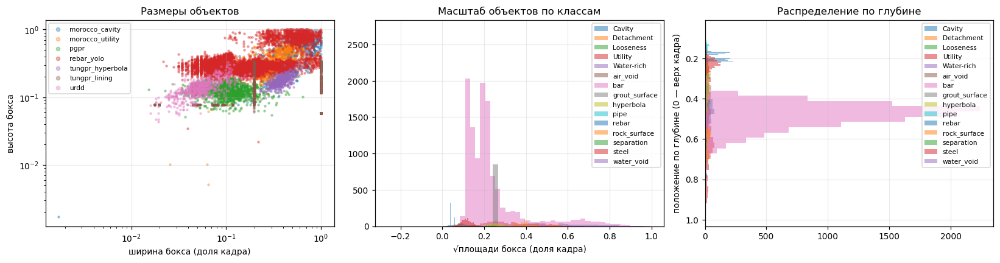

w                    h                 area              
                mean    50%    max   mean    50%    max   mean    50%    max
cls                                                                         
Cavity         0.499  0.492  1.000  0.450  0.448  1.000  0.262  0.216  0.928
Detachment     0.056  0.052  0.177  0.137  0.137  0.252  0.008  0.007  0.039
Looseness      0.074  0.064  0.193  0.173  0.170  0.332  0.014  0.011  0.038
Utility        0.344  0.319  0.942  0.355  0.322  0.856  0.132  0.099  0.455
Water-rich     0.087  0.091  0.098  0.111  0.111  0.124  0.010  0.010  0.011
air_void       0.112  0.117  0.117  0.078  0.078  0.078  0.009  0.009  0.009
bar            0.193  0.153  1.000  0.330  0.284  1.000  0.080  0.040  0.992
grout_surface  0.998  0.998  0.998  0.059  0.059  0.059  0.058  0.058  0.058
hyperbola      0.381  0.375  0.625  0.176  0.172  0.301  0.068  0.065  0.166
pipe           0.098  0.083  0.460  0.126  0.125  0.199  0.012  0.010  0.053
rebar          0.070  0.078  0.078  0.078  0.078  0.078  0.005  0.006  0.006
rock_surface   0.996  0.996  0.996  0.182  0.162  0.348  0.182  0.161  0.346
separation     0.195  0.195  0.195  0.168  0.146  0.342  0.033  0.028  0.067
steel          0.111  0.104  0.645  0.128  0.129  0.199  0.014  0.013  0.066
water_void     0.112  0.117  0.117  0.078  0.078  0.078  0.009  0.009  0.009

In [25]:
# Геометрия объектов: размеры и положение
box = ann.dropna(subset=["w", "h"]).copy()
box["area"] = box["w"] * box["h"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ds, g in box.groupby("dataset"):
    axes[0].scatter(g["w"], g["h"], s=4, alpha=0.35, label=ds)
axes[0].set_xlabel("ширина бокса (доля кадра)"); axes[0].set_ylabel("высота бокса")
axes[0].set_title("Размеры объектов"); axes[0].legend(fontsize=7, markerscale=2)
axes[0].set_xscale("log"); axes[0].set_yscale("log")

for cls, g in box.groupby("cls"):
    axes[1].hist(np.sqrt(g["area"]), bins=40, alpha=0.5, label=cls)
axes[1].set_xlabel("√площади бокса (доля кадра)"); axes[1].set_title("Масштаб объектов по классам")
axes[1].legend(fontsize=7)

for cls, g in box.groupby("cls"):
    axes[2].hist(g["yc"], bins=30, alpha=0.5, label=cls, orientation="horizontal")
axes[2].invert_yaxis()
axes[2].set_ylabel("положение по глубине (0 — верх кадра)")
axes[2].set_title("Распределение по глубине")
axes[2].legend(fontsize=7)
plt.tight_layout(); plt.show()

display(box.groupby("cls")[["w", "h", "area"]].describe().round(3)
          .loc[:, (slice(None), ["mean", "50%", "max"])])

**Размер.** Объекты занимают от долей процента до почти всего кадра: арматура —
квадратики около 8% ширины, а `grout_surface` и `rock_surface` — полосы во всю
ширину. Разница по площади — три порядка, поэтому нужен детектор, который работает
сразу на нескольких масштабах (с FPN-подобной «шеей»).

**Глубина.** На синтетике хорошо видна физика: арматура лежит в узкой полосе у
поверхности (в защитном слое бетона), границы материалов — глубже, дефекты — между
ними. Это и подсказка, и риск: в синтетике положение слишком регулярное, и модель
может запомнить «арматура — это то, что на 20% высоты кадра». На реальных данных
глубина меняется, поэтому нужны аугментации со сдвигом по вертикали (но без
вертикального отражения — см. раздел 8.2).

,mean,std,grad,row_energy,col_energy
dataset,,,,,
composite_lining,0.501,0.073,0.050,0.053,0.070
gprbase_concrete,0.498,0.119,0.026,0.086,0.116
guangzhou_tunnel,0.498,0.103,0.040,0.090,0.087
morocco_cavity,0.494,0.173,0.087,0.158,0.167
morocco_utility,0.500,0.096,0.038,0.076,0.093
pgpr,0.529,0.135,0.053,0.052,0.133
rebar_yolo,0.488,0.221,0.034,0.142,0.214
tigpr,0.502,0.117,0.023,0.073,0.114
tungpr_hyperbola,0.700,0.249,0.012,0.164,0.167


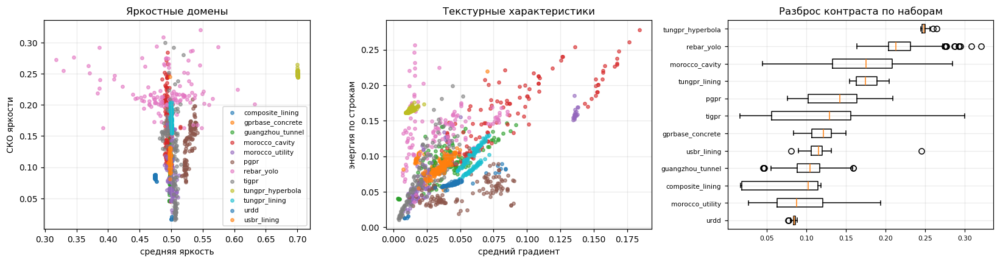

In [26]:
# Яркостная статистика доменов: насколько далеко наборы друг от друга
from PIL import Image

def frame_stats(path, max_side=256):
    try:
        im = Image.open(path).convert("L")
    except Exception:
        return None
    im.thumbnail((max_side, max_side))
    a = np.asarray(im, dtype=np.float32) / 255.0
    gy, gx = np.gradient(a)
    return dict(mean=a.mean(), std=a.std(),
                p05=np.percentile(a, 5), p95=np.percentile(a, 95),
                grad=np.sqrt(gx ** 2 + gy ** 2).mean(),
                # энергия по строкам: у георадарограмм сильная горизонтальная слоистость
                row_energy=a.std(axis=1).mean(), col_energy=a.std(axis=0).mean())

rng = np.random.default_rng(SEED)
sample = (frames.groupby("dataset", group_keys=False)
                .apply(lambda g: g.sample(min(len(g), 120), random_state=SEED)))
stats = []
for _, r in sample.iterrows():
    s = frame_stats(r["image"])
    if s:
        s.update(dataset=r["dataset"], origin=r["origin"], structure=r["structure"], image=r["image"])
        stats.append(s)
stats = pd.DataFrame(stats)
display(stats.groupby("dataset")[["mean", "std", "grad", "row_energy", "col_energy"]].mean().round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ds, g in stats.groupby("dataset"):
    axes[0].scatter(g["mean"], g["std"], s=12, alpha=0.6, label=ds)
axes[0].set_xlabel("средняя яркость"); axes[0].set_ylabel("СКО яркости")
axes[0].set_title("Яркостные домены"); axes[0].legend(fontsize=7)

for ds, g in stats.groupby("dataset"):
    axes[1].scatter(g["grad"], g["row_energy"], s=12, alpha=0.6, label=ds)
axes[1].set_xlabel("средний градиент"); axes[1].set_ylabel("энергия по строкам")
axes[1].set_title("Текстурные характеристики")

sns_order = stats.groupby("dataset")["std"].median().sort_values().index
axes[2].boxplot([stats.loc[stats.dataset == d, "std"] for d in sns_order], labels=sns_order, vert=False)
axes[2].set_title("Разброс контраста по наборам"); axes[2].tick_params(labelsize=7)
plt.tight_layout(); plt.show()

**Наборы заметно различаются.** Синтетика TunGPR занимает небольшую компактную
область: контраст у неё нормирован, аппаратного шума нет. Реальные наборы разбросаны
шире и смещены. Это и есть разрыв между доменами (domain gap), ради преодоления
которого в работе используется двухэтапное обучение.

In [27]:
# Технические утечки: формат файлов и дубликаты
print("формат файлов по наборам:")
display(pd.crosstab(frames["dataset"], frames["ext"]))

tun = ann[ann.dataset == "tungpr_lining"].copy()
if len(tun):
    tun["ext"] = tun["image"].map(lambda p: Path(p).suffix.lower())
    tun["дефект"] = tun["cls"].isin(["air_void", "water_void", "separation"])
    leak = pd.crosstab(tun.groupby("image")["дефект"].any(), tun.groupby("image")["ext"].first())
    print("\nTunGPR: формат файла против наличия дефекта на кадре")
    display(leak)

формат файлов по наборам:


ext,.jpg,.png
dataset,,
composite_lining,0,15
gprbase_concrete,84,0
guangzhou_tunnel,510,0
morocco_cavity,553,0
morocco_utility,786,0
pgpr,0,273
rebar_yolo,2528,0
tigpr,7169,0
tungpr_hyperbola,537,0



TunGPR: формат файла против наличия дефекта на кадре


ext,.jpg,.png
дефект,,
False,0,382
True,470,0


### 3.1. Как выглядят данные

Ниже — примеры кадров из каждого набора с наложенной разметкой. Смотреть на данные
глазами обязательно: многие ошибки разметки в открытых наборах видны сразу, и на
испорченных метках легко получить правдоподобные, но бессмысленные метрики.

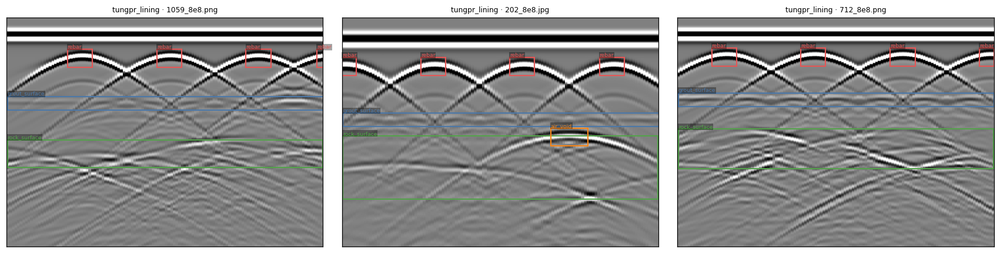

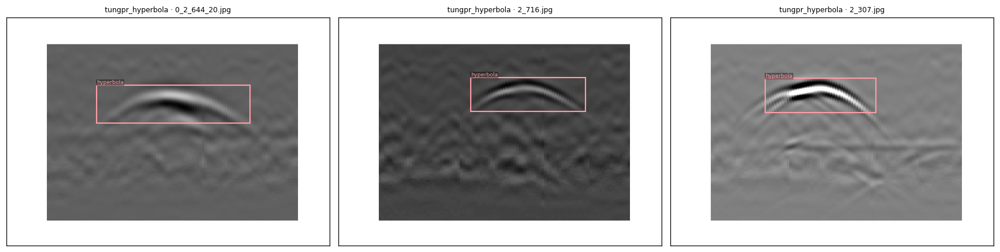

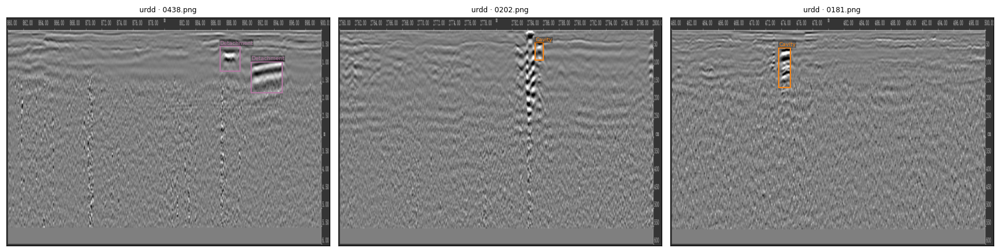

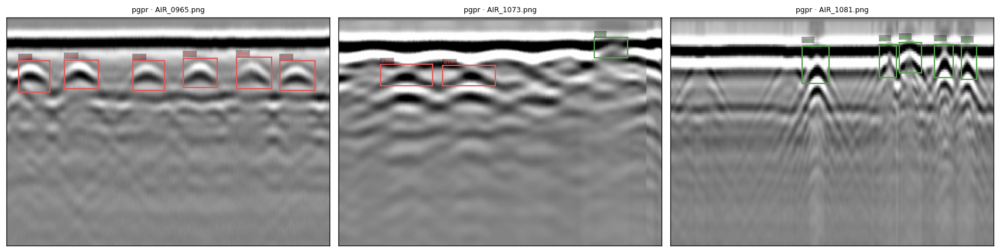

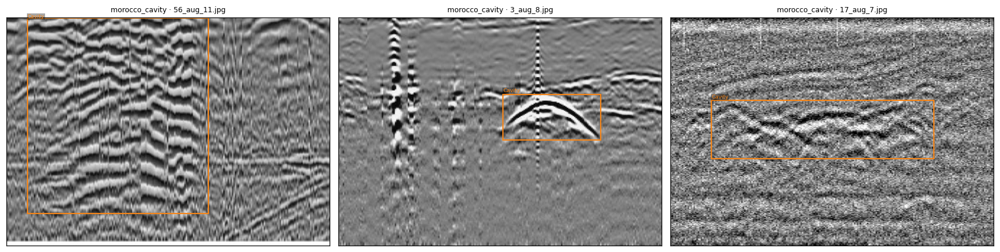

...

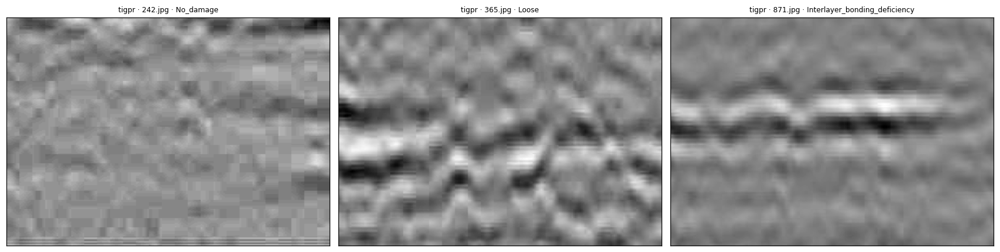

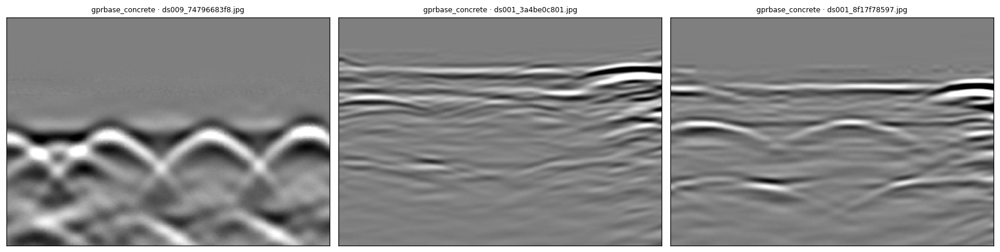

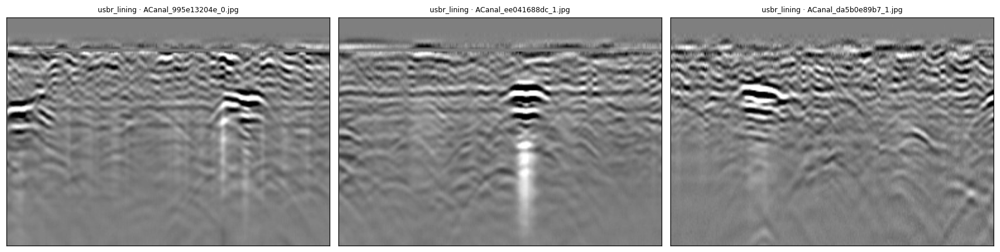

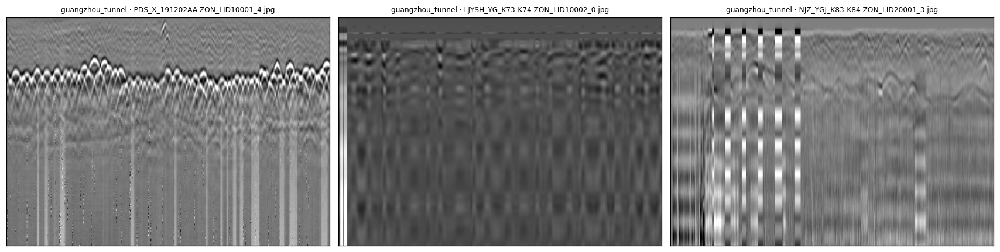

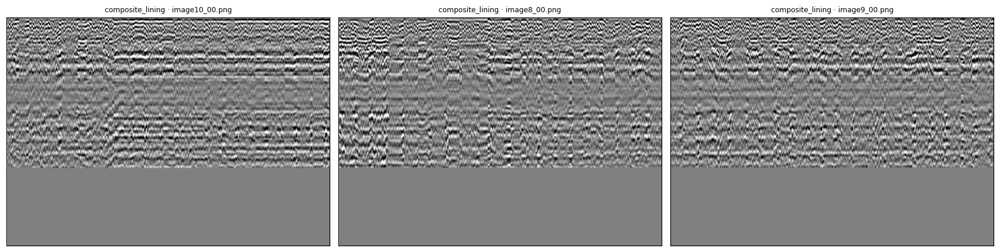

In [28]:
from PIL import Image
import matplotlib.patches as mpatches

PALETTE = {
    "rebar": "#E45756", "grout_surface": "#4C78A8", "rock_surface": "#54A24B",
    "separation": "#B279A2", "air_void": "#F58518", "water_void": "#2E5FA3",
    "hyperbola": "#FF9DA6", "Cavity": "#F58518", "Detachment": "#B279A2",
    "Looseness": "#9D755D", "Water-rich": "#2E5FA3", "steel": "#E45756",
    "pipe": "#54A24B", "Utility": "#54A24B", "crack": "#BAB0AC",
}

def draw_frame(ax, img_path, boxes, title=None, max_side=900):
    try:
        im = Image.open(img_path).convert("L")
    except Exception:
        ax.axis("off"); return
    W, H = im.size
    scale = min(1.0, max_side / max(W, H))
    if scale < 1.0:
        im = im.resize((int(W * scale), int(H * scale)))
    ax.imshow(np.asarray(im), cmap="gray", aspect="auto")
    w, h = im.size
    for _, b in boxes.iterrows():
        if np.isnan(b["xc"]):
            continue
        x = (b["xc"] - b["w"] / 2) * w
        y = (b["yc"] - b["h"] / 2) * h
        ax.add_patch(mpatches.Rectangle((x, y), b["w"] * w, b["h"] * h, fill=False,
                                        edgecolor=PALETTE.get(b["cls"], "#FFD166"), linewidth=1.4))
        ax.text(x, max(y - 2, 0), b["cls"], fontsize=6,
                color=PALETTE.get(b["cls"], "#FFD166"),
                bbox=dict(facecolor="black", alpha=0.35, pad=0.6, edgecolor="none"))
    ax.set_title(title or Path(img_path).name, fontsize=8)
    ax.set_xticks([]); ax.set_yticks([])


def show_dataset(ds_name, n=3, prefer_cls=None):
    sub = ann[ann.dataset == ds_name]
    if not len(sub):
        print(f"{ds_name}: нет данных"); return
    imgs = sub["image"].unique()
    if prefer_cls is not None:
        pref = sub[sub.cls == prefer_cls]["image"].unique()
        imgs = np.concatenate([pref, imgs])[: max(n * 3, 9)]
    rng = np.random.default_rng(SEED)
    pick = list(dict.fromkeys(imgs))[:n] if prefer_cls else list(rng.choice(imgs, min(n, len(imgs)), replace=False))
    fig, axes = plt.subplots(1, len(pick), figsize=(5.2 * len(pick), 4))
    for ax, p in zip(np.atleast_1d(axes), pick):
        g = sub[sub.image == p]
        # у наборов с покадровой разметкой рамок нет, поэтому класс выносится в подпись
        frame_lbl = sorted({c for c in g["cls"].dropna().unique()
                            if g[g.cls == c]["xc"].isna().all()})
        suffix = f" · {', '.join(frame_lbl)}" if frame_lbl else ""
        draw_frame(ax, p, g, title=f"{ds_name} · {Path(p).name}{suffix}")
    plt.tight_layout(); plt.show()


for ds in ann["dataset"].unique():
    show_dataset(ds, n=3)

**Что видно на примерах.**

* *TunGPR (синтетика).* Регулярная картинка: четыре гиперболы арматуры на одной
  глубине, под ними полосы `grout_surface` и `rock_surface`, дефекты — на границе
  слоёв. Неровность границ смоделирована, но аппаратного шума и помех нет.
* *URDD (реальные дороги).* Кадры вытянутые (1763×548), объекты маленькие, фон
  шумнее — видны горизонтальные полосы прямой волны и помехи.
* *P-GPR (реальный железобетон).* Плотный ряд гипербол от арматуры; трубы
  отличаются более широкой гиперболой и отражением изнутри.
* *Morocco.* Патчи 224×224, вырезанные из профилей и аугментированные: часть кадров
  отражена и повёрнута. Для георадарограммы это физически неверно (у оси времени
  есть направление), поэтому в работе набор используется только для EDA.

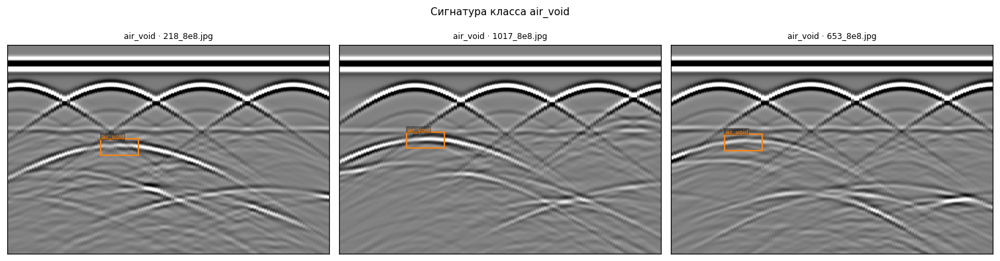

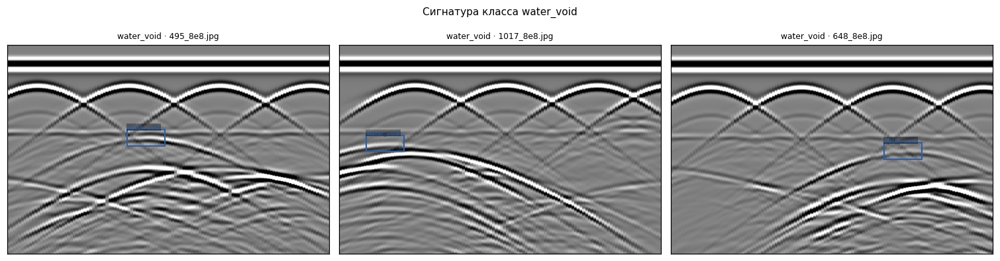

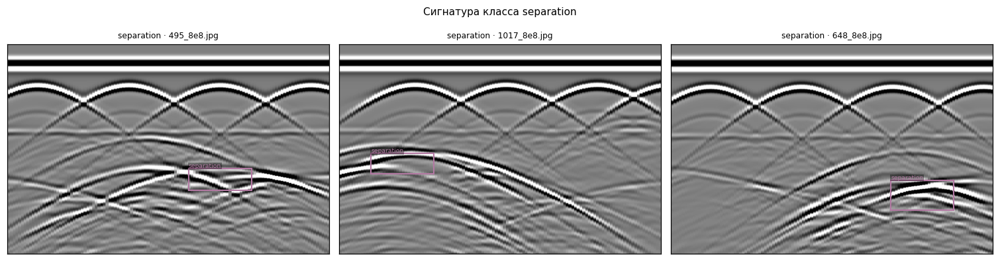

In [29]:
# Отдельно: сравнение сигнатур воздушной и водонаполненной пустоты на синтетике,
# где физика заложена в модель явно
for cls in ["air_void", "water_void", "separation"]:
    sub = ann[(ann.dataset == "tungpr_lining") & (ann.cls == cls)]
    if not len(sub):
        continue
    imgs = sub["image"].unique()[:3]
    fig, axes = plt.subplots(1, len(imgs), figsize=(4.6 * len(imgs), 3.6))
    for ax, p in zip(np.atleast_1d(axes), imgs):
        draw_frame(ax, p, ann[(ann.image == p) & (ann.cls == cls)], title=f"{cls} · {Path(p).name}")
    plt.suptitle(f"Сигнатура класса {cls}", fontsize=10)
    plt.tight_layout(); plt.show()

---
## 4. Анализ без учителя

Размеченных георадарограмм мало, неразмеченных — много. Поэтому до обучения
детектора полезно посмотреть на структуру данных без меток. Это помогает решить
четыре задачи:

1. **Оценить разрыв между доменами.** Если синтетику и реальные записи легко
   отличить друг от друга, простой перенос может не сработать.
2. **Найти дубликаты.** Повторы и аугментированные копии кадров, попавшие и в
   обучение, и в тест, завышают метрики.
3. **Найти аномальные кадры** — битые, пересвеченные, нетипичные.
4. **Понять, что есть в неразмеченных наборах**: кластеры подсказывают это ещё до
   привлечения эксперта.

Признаки — эмбеддинги сети ResNet-18, предобученной на ImageNet. Её фильтры (края,
текстуры, периодические узоры) неплохо описывают и георадарограммы, а сетей,
предобученных именно на георадарных данных, в открытом доступе нет.

In [30]:
import torch, torchvision
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader

class FrameDataset(Dataset):
    def __init__(self, paths, size=224):
        self.paths = list(paths)
        self.tf = transforms.Compose([
            transforms.Resize((size, size)),
            transforms.Grayscale(num_output_channels=3),  # георадарограмма одноканальна
            transforms.ToTensor(),
            transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
        ])

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        from PIL import Image
        try:
            im = Image.open(self.paths[i]).convert("RGB")
        except Exception:
            # Сюда не должно попадать: нечитаемые кадры отсеиваются заранее. Чёрная
            # заглушка вместо кадра — это подмена данных, она гарантированно
            # всплывёт как «аномалия» в поиске выбросов, хотя аномален файл, а не кадр.
            im = Image.new("RGB", (224, 224))
        return self.tf(im), i


# выборка кадров: не более 400 на набор, чтобы крупные корпуса не задавили мелкие
emb_frames = (frames.groupby("dataset", group_keys=False)
                    .apply(lambda g: g.sample(min(len(g), 400), random_state=SEED))
                    .reset_index(drop=True))

# Читаемость проверяется заранее, а не подменяется чёрным кадром в загрузчике:
# иначе битый файл попадёт в эмбеддинги и уверенно выделится как «аномалия».
def _readable(path):
    try:
        from PIL import Image
        with Image.open(path) as im:
            im.verify()
        return True
    except Exception:
        return False

_ok = emb_frames["image"].map(_readable)
if (~_ok).any():
    print(f"нечитаемых кадров исключено: {int((~_ok).sum())}")
    display(emb_frames.loc[~_ok, ["dataset", "image"]].head())
emb_frames = emb_frames[_ok].reset_index(drop=True)
print("кадров для эмбеддингов:", len(emb_frames))

backbone = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1)
backbone.fc = torch.nn.Identity()
backbone.eval().to("cuda" if torch.cuda.is_available() else "cpu")

loader = DataLoader(FrameDataset(emb_frames["image"]), batch_size=64, num_workers=8)
feats = []
with torch.no_grad():
    for x, _ in loader:
        x = x.to("cuda" if torch.cuda.is_available() else "cpu")
        feats.append(backbone(x).cpu().numpy())
E = np.concatenate(feats)
print("матрица эмбеддингов:", E.shape)

кадров для эмбеддингов: 3972
матрица эмбеддингов: (3972, 512)


первые 10 главных компонент объясняют 51.3% дисперсии, 50 компонент — 78.3%


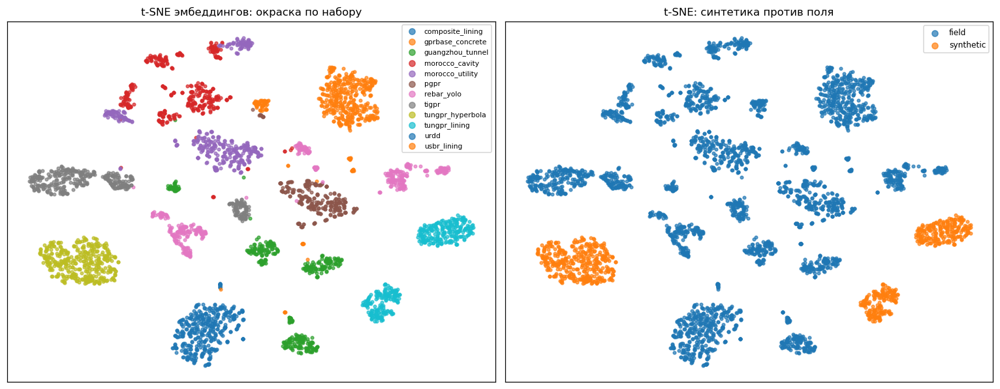

In [31]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_predict
from sklearn.ensemble import IsolationForest

Z = StandardScaler().fit_transform(E)
pca = PCA(n_components=min(50, Z.shape[1]), random_state=SEED)
P = pca.fit_transform(Z)
print(f"первые 10 главных компонент объясняют {pca.explained_variance_ratio_[:10].sum():.1%} дисперсии, "
      f"50 компонент — {pca.explained_variance_ratio_.sum():.1%}")

tsne = TSNE(n_components=2, perplexity=30, init="pca", random_state=SEED, n_iter=1000)
T = tsne.fit_transform(P)
emb_frames["tsne_x"], emb_frames["tsne_y"] = T[:, 0], T[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ds, g in emb_frames.groupby("dataset"):
    axes[0].scatter(g["tsne_x"], g["tsne_y"], s=9, alpha=0.7, label=ds)
axes[0].set_title("t-SNE эмбеддингов: окраска по набору"); axes[0].legend(fontsize=7, markerscale=2)
for og, g in emb_frames.groupby("origin"):
    axes[1].scatter(g["tsne_x"], g["tsne_y"], s=9, alpha=0.7, label=og)
axes[1].set_title("t-SNE: синтетика против поля"); axes[1].legend(fontsize=8, markerscale=2)
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

### 4.1. Насколько синтетика отличается от реальных данных

На картинке разделение легко переоценить, поэтому разрыв измеряется числом: насколько
хорошо линейный классификатор по тем же эмбеддингам отличает синтетику от реальных
данных. AUC около 1 означает, что домены разделяются тривиально.

Чтобы цифра была честной, соблюдаются два правила:

1. Нормировка и PCA обучаются **внутри** каждого фолда (через `Pipeline`). Если
   подготовить признаки на всех данных сразу, тестовая часть заранее «подсмотрена»,
   и AUC завышается.
2. Фолды делятся **по наборам-источникам**, иначе соседние окна одного профиля и
   копии одного кадра попадают и в обучение, и в тест.

Без этих правил получается AUC = 1.000 и вывод «домены не имеют ничего общего». С
ними AUC заметно ниже: домены различимы, но не полностью, и адаптации между ними
есть над чем работать.

Оговорка: высокая AUC значит лишь, что наборы различаются в этих признаках. Причиной
может быть не физика, а стиль отрисовки, подписи осей или обработка. Это не
доказательство того, что перенос невозможен.

AUC разделения «синтетика / поле», 5 фолдов по наборам, подготовка признаков внутри фолда: 0.810
интерпретация: корпуса частично перекрываются


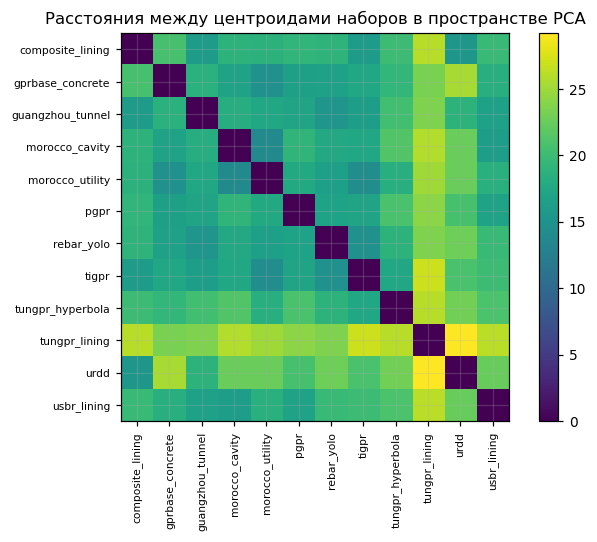

In [32]:
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedGroupKFold

y_origin = (emb_frames["origin"] == "synthetic").astype(int).values
if y_origin.min() != y_origin.max():
    pipe = make_pipeline(StandardScaler(),
                         PCA(n_components=min(50, E.shape[1]), random_state=SEED),
                         LogisticRegression(max_iter=2000))
    g = emb_frames["dataset"].values
    n_splits = min(5, len(np.unique(g)), int(np.bincount(y_origin).min()))
    if n_splits >= 2:
        cv = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
        proba = cross_val_predict(pipe, E, y_origin, cv=cv, groups=g,
                                  method="predict_proba")[:, 1]
        auc = roc_auc_score(y_origin, proba)
        print(f"AUC разделения «синтетика / поле», {n_splits} фолдов по наборам, "
              f"подготовка признаков внутри фолда: {auc:.3f}")
        print("интерпретация:", "рассмотренные корпуса разделяются тривиально — "
              "перенос потребует адаптации" if auc > 0.95 else
              "корпуса частично перекрываются")
    else:
        print("групп слишком мало для честной перекрёстной проверки разделимости")

# попарные расстояния между центроидами наборов
cent = pd.DataFrame(P, index=emb_frames["dataset"]).groupby(level=0).mean()
from scipy.spatial.distance import pdist, squareform
D = pd.DataFrame(squareform(pdist(cent.values)), index=cent.index, columns=cent.index)
fig, ax = plt.subplots(figsize=(6.5, 5))
im = ax.imshow(D.values, cmap="viridis")
ax.set_xticks(range(len(D))); ax.set_xticklabels(D.columns, rotation=90, fontsize=7)
ax.set_yticks(range(len(D))); ax.set_yticklabels(D.index, fontsize=7)
ax.set_title("Расстояния между центроидами наборов в пространстве PCA")
plt.colorbar(im); plt.tight_layout(); plt.show()

### 4.2. Кластеризация

силуэт по k: {2: 0.167, 3: 0.14, 4: 0.158, 5: 0.183, 6: 0.198, 7: 0.21, 8: 0.225, 9: 0.246, 10: 0.258, 11: 0.268, 12: 0.27, 13: 0.287, 14: 0.295, 15: 0.283, 16: 0.291}
максимум силуэта при k = 14 на диапазоне 2..16
используется найденный оптимум: 14


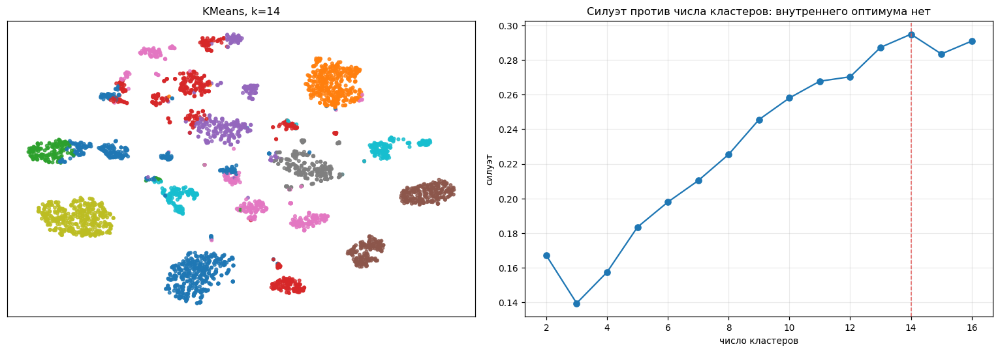

dataset,composite_lining,gprbase_concrete,guangzhou_tunnel,morocco_cavity,morocco_utility,pgpr,rebar_yolo,tigpr,tungpr_hyperbola,tungpr_lining,urdd,usbr_lining
cluster,,,,,,,,,,,,
0,3,0,0,0,0,0,0,0,0,0,400,0
1,12,3,38,11,46,7,17,209,0,0,0,2
2,0,0,0,2,0,0,0,0,0,0,0,380
3,0,0,1,1,0,0,11,146,0,0,0,0
4,0,1,136,0,0,0,0,0,0,0,0,0
5,0,15,0,262,84,0,39,0,0,0,0,0
6,0,51,2,15,269,24,1,1,0,0,0,0
7,0,0,0,0,0,0,0,0,0,400,0,0
8,0,0,219,0,1,6,0,0,0,0,0,18



доля доминирующего набора в кластере:


cluster
0      99.3
1      60.6
2      99.5
3      91.8
4      99.3
5      65.5
6      74.1
7     100.0
8      89.8
9      69.4
10     88.0
11    100.0
12     99.4
13    100.0
Name: %, dtype: float64

медиана доли доминирующего набора: 96%; кластеров, где один набор даёт больше половины кадров: 14 из 14


In [33]:
scores = {}
for k in range(2, 17):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(P)
    scores[k] = silhouette_score(P, km.labels_, sample_size=min(2000, len(P)), random_state=SEED)
ks = list(scores)
best_k = max(scores, key=scores.get)
at_edge = best_k in (ks[0], ks[-1])
print("силуэт по k:", {k: round(v, 3) for k, v in scores.items()})
print(f"максимум силуэта при k = {best_k} на диапазоне {ks[0]}..{ks[-1]}")
# Силуэт здесь почти монотонно растёт и упирается в границу перебора: внутреннего
# оптимума нет, то есть выраженной кластерной структуры в данных тоже нет. Это само
# по себе результат, поэтому k фиксируется как рабочее число, а не подаётся как
# «оптимальное»; 10 удобно ещё и тем, что различимо на палитре tab10.
K_WORK = 10 if at_edge else best_k
print("внутреннего оптимума нет — k выбирается как рабочее значение:" if at_edge
      else "используется найденный оптимум:", K_WORK)

km = KMeans(n_clusters=K_WORK, n_init=10, random_state=SEED).fit(P)
emb_frames["cluster"] = km.labels_

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sc = axes[0].scatter(emb_frames["tsne_x"], emb_frames["tsne_y"], c=emb_frames["cluster"],
                     cmap="tab10", s=9, alpha=0.8)
axes[0].set_title(f"KMeans, k={K_WORK}"); axes[0].set_xticks([]); axes[0].set_yticks([])
axes[1].plot(list(scores), list(scores.values()), "o-")
axes[1].axvline(K_WORK, color="#E45756", ls="--", lw=1)
axes[1].set_xlabel("число кластеров"); axes[1].set_ylabel("силуэт")
axes[1].set_title("Силуэт против числа кластеров: внутреннего оптимума нет")
plt.tight_layout(); plt.show()

ct = pd.crosstab(emb_frames["cluster"], emb_frames["dataset"])
display(ct)
dom = ct.div(ct.sum(axis=1), axis=0).max(axis=1) * 100
print("\nдоля доминирующего набора в кластере:")
display(dom.round(1).rename("%"))
print(f"медиана доли доминирующего набора: {dom.median():.0f}%; "
      f"кластеров, где один набор даёт больше половины кадров: {(dom > 50).sum()} из {len(dom)}")

Кластеры в основном совпадают с наборами-источниками (см. долю основного набора в
каждом кластере выше). Это ожидаемый, но важный результат:
**без специальных мер сеть прежде всего учит, «откуда кадр», а не «что на кадре»**.
Поэтому в разделе 6 все изображения приводятся к одному виду (градации серого,
одинаковое сжатие), а разбиение на выборки делается по источникам.

In [34]:
# Псевдо-разметка неразмеченного набора: что кластеры говорят о реальных
# тоннельных разрезах composite lining
unlab = emb_frames[emb_frames["dataset"] == "composite_lining"]
if len(unlab):
    print("реальные тоннельные разрезы распределились по кластерам:",
          dict(unlab["cluster"].value_counts()))
    neigh = emb_frames[emb_frames["cluster"].isin(unlab["cluster"].unique())]
    print("соседи по этим кластерам:", dict(neigh["dataset"].value_counts().head(5)))

реальные тоннельные разрезы распределились по кластерам: {1: 12, 0: 3}
соседи по этим кластерам: {'urdd': 400, 'tigpr': 209, 'morocco_utility': 46, 'guangzhou_tunnel': 38, 'rebar_yolo': 17}


### 4.3. Дубликаты и утечки

групп одинаковых по перцептивному хешу кадров: 134; кадров в них: 380
групп, пересекающих границы наборов: 0


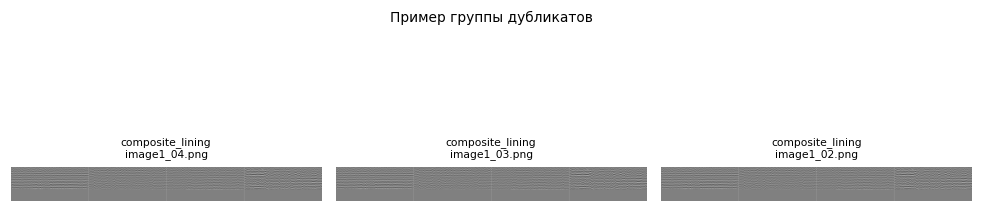

In [35]:
import imagehash
from PIL import Image

hashes = {}
for p in emb_frames["image"]:
    try:
        hashes[p] = imagehash.phash(Image.open(p).convert("L").resize((256, 256)))
    except Exception:
        pass

buckets = defaultdict(list)
for p, h in hashes.items():
    buckets[str(h)].append(p)
dups = {h: ps for h, ps in buckets.items() if len(ps) > 1}
n_dup_frames = sum(len(v) for v in dups.values())
print(f"групп одинаковых по перцептивному хешу кадров: {len(dups)}; кадров в них: {n_dup_frames}")

cross = 0
ds_of = dict(zip(emb_frames["image"], emb_frames["dataset"]))
for ps in dups.values():
    if len({ds_of[p] for p in ps}) > 1:
        cross += 1
print("групп, пересекающих границы наборов:", cross)

if dups:
    ex = list(dups.values())[0][:4]
    fig, axes = plt.subplots(1, len(ex), figsize=(3 * len(ex), 3))
    for ax, p in zip(np.atleast_1d(axes), ex):
        ax.imshow(Image.open(p).convert("L"), cmap="gray")
        ax.set_title(f"{ds_of[p]}\n{Path(p).name}", fontsize=7); ax.axis("off")
    plt.suptitle("Пример группы дубликатов", fontsize=9); plt.tight_layout(); plt.show()

### 4.4. Аномальные кадры

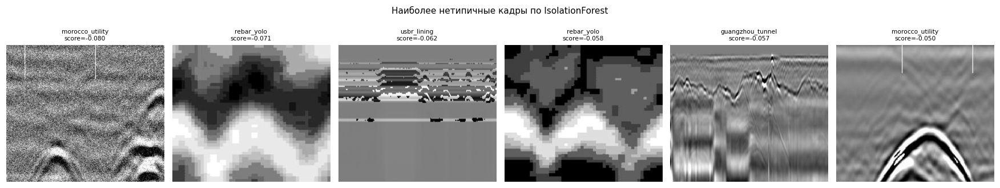

dataset
gprbase_concrete    0.0593
morocco_cavity      0.0643
rebar_yolo          0.0645
morocco_utility     0.0874
guangzhou_tunnel    0.0881
usbr_lining         0.0994
tigpr               0.1002
pgpr                0.1034
composite_lining    0.1212
tungpr_lining       0.1317
tungpr_hyperbola    0.1336
urdd                0.1445
Name: средняя оценка типичности, dtype: float64

In [36]:
iso = IsolationForest(contamination=0.02, random_state=SEED).fit(P)
emb_frames["anomaly"] = iso.decision_function(P)
worst = emb_frames.nsmallest(6, "anomaly")
fig, axes = plt.subplots(1, 6, figsize=(16, 3))
for ax, (_, r) in zip(axes, worst.iterrows()):
    try:
        ax.imshow(Image.open(r["image"]).convert("L"), cmap="gray", aspect="auto")
    except Exception:
        pass
    ax.set_title(f"{r['dataset']}\nscore={r['anomaly']:.3f}", fontsize=7); ax.axis("off")
plt.suptitle("Наиболее нетипичные кадры по IsolationForest", fontsize=10)
plt.tight_layout(); plt.show()

display(emb_frames.groupby("dataset")["anomaly"].mean().sort_values().round(4).rename("средняя оценка типичности"))

---
## 5. Физическая проверка: что георадар видит вместо трещины

В разделе 1.2 утверждается, что георадар реагирует не на саму трещину, а на то, чем
она **заполнена**. Это можно проверить на реальных измерениях.

Набор Solla et al. — лабораторные бетонные плиты с трещинами известного размера,
снятые антенной 2.3 ГГц. Одну и ту же трещину по очереди заполняли воздухом, сухим
песком, мокрым песком, водой и битумом. Данные лежат в сыром формате MALÅ (`.rd3` +
текстовый заголовок `.rad`), поэтому сначала их нужно прочитать.

Ожидание по формуле коэффициента отражения:

$$R = \frac{\sqrt{\varepsilon_{\text{бетон}}} - \sqrt{\varepsilon_{\text{заполнитель}}}}{\sqrt{\varepsilon_{\text{бетон}}} + \sqrt{\varepsilon_{\text{заполнитель}}}}$$

При ε(бетон) ≈ 7 воздух (ε = 1) даёт R ≈ +0.46, вода (ε = 81) — R ≈ −0.54: сила
отражения похожая, но **знак противоположный**. Сухой песок (ε ≈ 4) и битум
(ε ≈ 3) дают слабый отклик. Если это так, то «трещина» без указания заполнителя — это
на самом деле несколько разных физических случаев.

In [37]:
SOLLA_ROOT = DATA / "solla_cracks/extracted/RawData"

def read_mala(rad_path: Path):
    """Чтение профиля MALÅ: текстовый заголовок .rad + бинарный .rd3 (int16)."""
    hdr = {}
    for line in open(rad_path, encoding="latin-1"):
        if ":" in line:
            k, v = line.split(":", 1)
            hdr[k.strip()] = v.strip()
    n = int(hdr["SAMPLES"])
    raw = np.fromfile(str(rad_path)[:-4] + ".rd3", dtype="<i2")
    traces = len(raw) // n
    data = raw[:n * traces].reshape(traces, n).T.astype(np.float32)   # (время, трасса)
    return data, hdr


def dewow(a, win=25):
    """Удаление низкочастотного тренда по трассам — стандартный первый шаг обработки."""
    k = np.ones(win) / win
    base = np.apply_along_axis(lambda x: np.convolve(x, k, mode="same"), 0, a)
    return a - base


def remove_background(a):
    """Вычитание среднего по трассам убирает прямую волну и горизонтальные помехи."""
    return a - a.mean(axis=1, keepdims=True)


if SOLLA_ROOT.exists():
    profiles = {}
    for rad in sorted(SOLLA_ROOT.glob("Normal configuration/Slab I/*/*.rad")):
        profiles[rad.parent.name] = rad
    print("найдены заполнители трещины:", list(profiles))
else:
    profiles = {}
    print("набор Solla не найден — раздел пропускается")

найдены заполнители трещины: ['Air', 'Bitumen', 'Sand', 'Saturated Sand', 'Water']


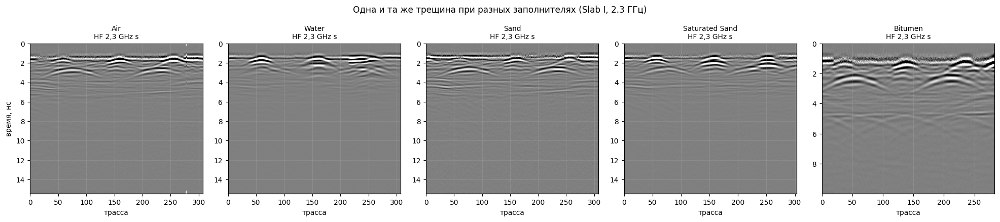

,заполнитель,пик отклика / опорный уровень,СКО отклика / опорный уровень,трасс,"окно, нс",ε заполнителя,теоретический R,|R| теоретический
0,Air,0.141,0.019,307,15.47,1.0,0.451,0.451
1,Water,0.741,0.057,307,15.47,81.0,-0.546,0.546
2,Sand,0.268,0.039,308,15.47,4.0,0.139,0.139
3,Saturated Sand,0.678,0.067,303,15.47,20.0,-0.257,0.257
4,Bitumen,0.184,0.025,283,10.00,3.0,0.209,0.209


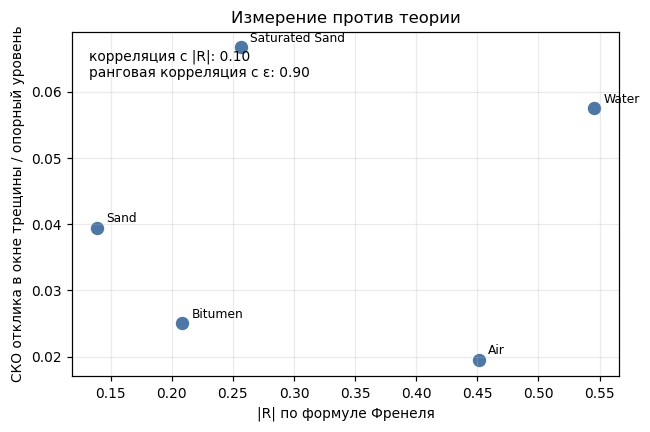

In [38]:
if profiles:
    order = [k for k in ["Air", "Water", "Sand", "Saturated Sand", "Saturated sand", "Bitumen"]
             if k in profiles]
    fig, axes = plt.subplots(1, len(order), figsize=(3.6 * len(order), 4))
    stats = []
    for ax, name in zip(np.atleast_1d(axes), order):
        data, hdr = read_mala(profiles[name])
        proc = remove_background(dewow(data))
        tw = float(hdr["TIMEWINDOW"])
        vmax = np.percentile(np.abs(proc), 99)
        ax.imshow(proc, cmap="gray", aspect="auto", vmin=-vmax, vmax=vmax,
                  extent=[0, proc.shape[1], tw, 0])
        ax.set_title(f"{name}\n{hdr.get('ANTENNAS','')[:12]}", fontsize=9)
        ax.set_xlabel("трасса")
        ax.set_ylabel("время, нс" if name == order[0] else "")
        # Сравнивать профили «в лоб» нельзя: у них разные временные окна (10 и 15.5 нс)
        # и разное усиление приёмника, поэтому нужна нормировка. Что именно стоит в
        # знаменателе — стоит назвать честно. Прямая волна из данных уже удалена
        # вычитанием среднего по трассам (`proc`), значит в окне 0–1.5 нс остаётся не
        # опорный импульс, а его **остаток** после вычитания плюс ранние отражения.
        # Это работоспособная мера уровня сигнала в записи, но называть её «прямой
        # волной» неверно; для настоящего опорного сигнала нужны исходные трассы до
        # обработки и выставленный time-zero.
        t = np.linspace(0, tw, proc.shape[0])
        ref = np.abs(proc[(t >= 0.0) & (t <= 1.5)]).max()
        band = proc[(t >= 2.0) & (t <= 6.0)]
        stats.append({"заполнитель": name,
                      "пик отклика / опорный уровень": float(np.abs(band).max() / max(ref, 1e-6)),
                      "СКО отклика / опорный уровень": float(band.std() / max(ref, 1e-6)),
                      "трасс": proc.shape[1], "окно, нс": round(tw, 2)})
    plt.suptitle("Одна и та же трещина при разных заполнителях (Slab I, 2.3 ГГц)", fontsize=11)
    plt.tight_layout(); plt.show()

    solla = pd.DataFrame(stats)
    eps = {"Air": 1.0, "Water": 81.0, "Sand": 4.0, "Saturated Sand": 20.0,
           "Saturated sand": 20.0, "Bitumen": 3.0}
    eps_concrete = 7.0
    solla["ε заполнителя"] = solla["заполнитель"].map(eps)
    solla["теоретический R"] = ((np.sqrt(eps_concrete) - np.sqrt(solla["ε заполнителя"])) /
                                (np.sqrt(eps_concrete) + np.sqrt(solla["ε заполнителя"])))
    solla["|R| теоретический"] = solla["теоретический R"].abs()
    display(solla.round(3))

    fig, ax = plt.subplots(figsize=(6, 4))
    ax.scatter(solla["|R| теоретический"], solla["СКО отклика / опорный уровень"], s=60, color="#4C78A8")
    for _, r in solla.iterrows():
        ax.annotate(r["заполнитель"], (r["|R| теоретический"], r["СКО отклика / опорный уровень"]),
                    textcoords="offset points", xytext=(6, 4), fontsize=8)
    ax.set_xlabel("|R| по формуле Френеля")
    ax.set_ylabel("СКО отклика в окне трещины / опорный уровень")
    ax.set_title("Измерение против теории")
    if len(solla) > 2:
        corr_r = solla["|R| теоретический"].corr(solla["СКО отклика / опорный уровень"])
        corr_eps = solla["ε заполнителя"].corr(solla["СКО отклика / опорный уровень"], method="spearman")
        ax.text(0.03, 0.95, f"корреляция с |R|: {corr_r:.2f}\n"
                            f"ранговая корреляция с ε: {corr_eps:.2f}",
                transform=ax.transAxes, fontsize=9, va="top")
    plt.tight_layout(); plt.show()

**Что показало измерение.** Сила отклика зависит от заполнителя: вода и мокрый
песок дают заметно более сильный сигнал, сухой песок и битум — слабее. Это
подтверждает главный тезис: георадар реагирует на заполнитель, а не на трещину как
таковую.

**Насколько точно это измерение.** Не очень: всего пять точек, и окно для каждой
выбрано вручную. Окно 2–6 нс задаёт глубину, но не положение вдоль профиля, поэтому
в него попадает вся ширина плиты. Нулевое время взято из заголовка, усиление между
записями не выровнено. Поэтому это согласие по порядку величин и порядку
заполнителей, а не точная проверка формулы.

**Чего измерение не подтвердило.** По формуле воздушная трещина должна давать почти
такой же сильный отклик, как вода (|R| ≈ 0.45). На деле у воздуха отклик самый
слабый из пяти. Причина — толщина: при 2.3 ГГц длина волны в бетоне около 5 см, а
трещина в десятки раз тоньше. Для такого тонкого слоя формула для толстой среды не
работает: отражения от двух его границ почти гасят друг друга, и сила отклика
зависит от толщины слоя относительно длины волны. У воды скорость волны в 9 раз
меньше, поэтому для волны тот же зазор с водой «толще», и отклик сильнее.

**Вывод: «трещина» — это не один класс.** Модель, обученная на метке «трещина» без
учёта заполнителя, учится на смеси разных явлений. Находить она будет те трещины,
которые хорошо заполнены водой, а не те, что опаснее.

Практическое следствие: класс «трещины» стоит переопределить как «раскрытая,
водонасыщенная или заполненная трещина / расслоение», а сухие волосяные трещины
искать оптическими методами, а не георадаром.

---
## 6. Подготовка данных

### 6.1. Решения по итогам EDA

1. **Одинаковый формат изображений.** В TunGPR кадры с дефектами сохранены как JPEG
   RGB, а кадры без дефектов — как PNG RGBA. Формат файла совпадает с классом, и сеть
   может научиться различать артефакты сжатия вместо сигнала. Поэтому все изображения
   приводятся к одному виду: градации серого, JPEG q95 с одинаковыми настройками.
2. **Разбиение по группам, а не по отдельным кадрам.** Соседние кадры одного профиля
   перекрываются, а в Morocco у одного исходного профиля до восьми копий. Группа
   определяется происхождением кадра.
3. **Удаление дубликатов.** Раздел 4.3 показал, что одинаковые кадры есть внутри
   наборов. Из каждой группы одинаковых остаётся один кадр, иначе он попадёт и в
   обучение, и в валидацию.
4. **Стратификация по редким классам.** При обычном случайном разбиении редкие
   классы (`Cavity`, `Water-rich`) целиком уходили в обучение, и в тесте их не
   оставалось. Группы распределяются жадным алгоритмом, который выравнивает доли
   классов.
5. **Синтетика и реальные данные не смешиваются.** Синтетика используется только
   для предобучения, оценка — только на реальных данных.

### 6.2. Из чего собираются обучающие наборы

| Набор | Источник | Классы | Роль |
|---|---|---|---|
| `SRC_TUNNEL` | TunGPR | 6 (арматура, 2 границы, расслоение, 2 типа пустот) | предобучение на синтетике |
| `TGT_CONCRETE` | P-GPR | steel, pipe | реальные данные: арматура и трубы |
| `TGT_ROAD` | URDD | Cavity, Detachment, Looseness, Water-rich | реальные данные: пустоты, отслоение, разуплотнение, вода |

In [39]:
import shutil
import imagehash
from PIL import Image

def normalize_image(src, dst, quality=95):
    """Единый вид: 8 бит, градации серого, JPEG одного качества."""
    Image.open(src).convert("L").save(dst, "JPEG", quality=quality, subsampling=2)


def source_group(dataset: str, path: str) -> str:
    """Происхождение кадра — то, что нельзя разрывать между подвыборками."""
    p = Path(path)
    if dataset.startswith("tungpr"):
        # каждый файл — независимый запуск FDTD со своими случайными параметрами,
        # поэтому группа = сам кадр (сценарий при этом учитывается стратификацией)
        parts = p.parts
        scen = next((f"{parts[i]}/{parts[i+1]}" for i, t in enumerate(parts)
                     if t in ("damaged", "intact") and i + 1 < len(parts)), "tungpr")
        return f"{scen}:{p.stem}"
    if dataset.startswith("morocco"):
        return p.stem.split("_aug_")[0]          # 10_aug_3.jpg -> профиль 10
    if dataset == "urdd":
        try:
            # Блок из десяти подряд идущих номеров. Это ЭВРИКА, а не установленное
            # происхождение: идентификаторов профиля, объекта или сеанса съёмки в
            # публикации нет, и совпадают ли границы блоков с границами профилей,
            # проверить нечем. Два соседних блока вполне могут принадлежать одному
            # профилю, и тогда часть зависимости между подвыборками останется.
            # Чувствительность к размеру блока проверяется ниже.
            return f"block_{int(p.stem) // URDD_BLOCK:03d}"
        except ValueError:
            return p.stem
    if dataset == "pgpr":
        return p.parent.parent.name              # официальный сплит
    return p.stem


URDD_BLOCK = 10   # размер блока группировки URDD; анализ чувствительности — в 5.2b
HAMMING_THR = 0   # порог различия хешей; обоснование — в ячейке ниже

def frame_hash(path):
    """Единый способ хеширования кадра для всех проверок."""
    return imagehash.phash(Image.open(path).convert("L").resize((256, 256)))


def drop_duplicates(sub: pd.DataFrame, dataset: str, thr=HAMMING_THR):
    """Удаляет перцептивно совпадающие кадры, оставляя одного представителя.

    Порог задаётся параметром thr и по умолчанию равен нулю — совпадение 64-битного
    перцептивного хеша. Это не произвольный выбор: см. измерение распределения
    расстояний ниже, на однородных георадарограммах хеш насыщается, и любой порог
    больше нуля начинает выбрасывать физически разные кадры.

    Важно, чем эта процедура НЕ является. Нулевое расстояние по pHash — совпадение
    признака, а не равенство изображений: хеш считается по DCT уменьшенной до 32×32
    картинки и огрубляет всё, что мельче. Прямая проверка по пикселям показывает, что
    часть групп с одинаковым хешем содержит различающиеся кадры (измерение ниже).
    Поэтому удаляемые кадры правильно называть перцептивными совпадениями, а не
    точными дубликатами, а сама процедура — это защита от утечки близких кадров между
    подвыборками, а не очистка от копий.
    """
    kept_hashes, keep, dropped = [], [], 0
    for img in sub["image"].unique():
        try:
            h = frame_hash(img)
        except Exception:
            keep.append(img)
            continue
        if any((h - k) <= thr for k in kept_hashes):
            dropped += 1
            continue
        kept_hashes.append(h)
        keep.append(img)
    return sub[sub["image"].isin(keep)].copy(), dropped


def assign_groups(sub: pd.DataFrame, dataset: str):
    return {img: source_group(dataset, img) for img in sub["image"].unique()}


def stratified_group_split(sub, groups, classes, ratios=(0.7, 0.15, 0.15), seed=SEED):
    """Жадное распределение групп по подвыборкам с выравниванием редких классов.

    Группы обрабатываются в порядке «сначала те, что содержат самый редкий класс»,
    и каждая уходит в ту подвыборку, где текущий дефицит по этому классу больше.
    """
    names = ["train", "val", "test"][:len(ratios)]
    gdf = (sub.assign(group=sub["image"].map(groups))
              .pivot_table(index="group", columns="cls", values="image",
                           aggfunc="count", fill_value=0))
    for c in classes:
        if c not in gdf.columns:
            gdf[c] = 0
    gdf = gdf[classes]
    total = gdf.sum()
    rarity = total.rank(ascending=True)          # 1 — самый редкий класс
    targets = {s: total * r for s, r in zip(names, ratios)}
    current = {s: pd.Series(0, index=classes, dtype=float) for s in names}
    assign = {}

    rng = np.random.default_rng(seed)
    order = sorted(gdf.index,
                   key=lambda g: (-(gdf.loc[g] > 0).mul(1 / rarity).max(), -gdf.loc[g].sum(),
                                  rng.random()))
    for g in order:
        row = gdf.loc[g]
        present = [c for c in classes if row[c] > 0]
        key_cls = min(present, key=lambda c: total[c]) if present else classes[0]
        deficits = {s: (targets[s][key_cls] - current[s][key_cls]) /
                       max(targets[s][key_cls], 1e-6) for s in names}
        best = max(names, key=lambda s: (deficits[s], -current[s].sum()))
        assign[g] = best
        current[best] += row
    return {img: assign[groups[img]] for img in sub["image"].unique()}, gdf


def build_yolo_dataset(name, subset, class_names, split_map, normalize=True, quality=95):
    """Материализует YOLO-структуру: images/{train,val,test} + labels/... + data.yaml."""
    out = WORK / name
    if out.exists():
        shutil.rmtree(out)
    cls_id = {c: i for i, c in enumerate(class_names)}
    counts = Counter()
    for img_path, g in subset.groupby("image"):
        split = split_map.get(img_path)
        if split is None:
            continue
        stem = hashlib.md5(img_path.encode()).hexdigest()[:12]
        img_dir, lbl_dir = out / "images" / split, out / "labels" / split
        img_dir.mkdir(parents=True, exist_ok=True); lbl_dir.mkdir(parents=True, exist_ok=True)
        dst_img = img_dir / f"{stem}.jpg"
        try:
            if normalize:
                normalize_image(img_path, dst_img, quality)
            else:
                shutil.copyfile(img_path, dst_img)
        except Exception:
            continue
        with open(lbl_dir / f"{stem}.txt", "w") as fh:
            for _, b in g.iterrows():
                if b["cls"] not in cls_id or np.isnan(b["xc"]):
                    continue
                fh.write(f"{cls_id[b['cls']]} {b['xc']:.6f} {b['yc']:.6f} {b['w']:.6f} {b['h']:.6f}\n")
                counts[(split, b["cls"])] += 1
        counts[(split, "кадров")] += 1

    with open(out / "data.yaml", "w") as fh:
        fh.write(f"path: {out.resolve()}\ntrain: images/train\nval: images/val\n")
        if (out / "images" / "test").exists():
            fh.write("test: images/test\n")
        fh.write("\nnames:\n")
        for i, c in enumerate(class_names):
            fh.write(f"  {i}: {c}\n")
    return out / "data.yaml", counts


def summarize_counts(counts, title):
    rows = defaultdict(dict)
    for (split, cls), v in counts.items():
        rows[cls][split] = v
    df = pd.DataFrame(rows).T.fillna(0).astype(int)
    df.index.name = title
    return df[[c for c in ["train", "val", "test"] if c in df.columns]]

### 6.3. Порог для поиска дубликатов

Для поиска дубликатов используется перцептивный хеш. Он придуман для фотографий, и
там расстояние Хэмминга 5–10 обычно означает «разные картинки». Георадарограммы
устроены иначе: это однородная слоистая текстура, у которой почти вся информация в
нескольких низких частотах, поэтому хеши у них похожи. Ниже измеряется реальное
распределение расстояний между хешами кадров URDD, и по нему выбирается порог.

пар кадров: 44850; медиана расстояния: 8; максимум: 12


,доля пар с расстоянием ≤ t
0,0.0013
2,0.0276
4,0.1563
6,0.4348
8,0.7673


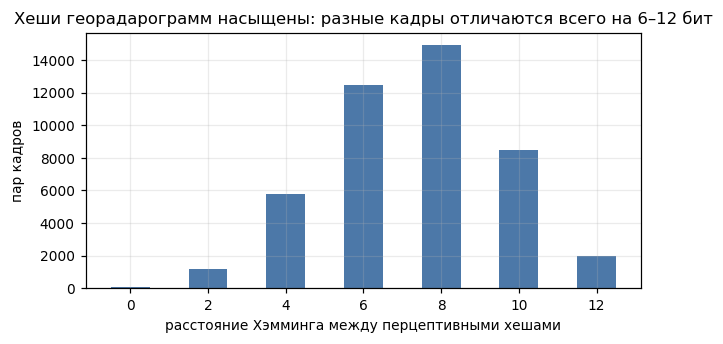

In [40]:
sample_paths = [p for p in frames[frames.dataset == "urdd"]["image"].tolist()[:300]]
if sample_paths:
    hs = []
    for p in sample_paths:
        try:
            hs.append(frame_hash(p))
        except Exception:
            pass
    dists = np.array([hs[i] - hs[j] for i in range(len(hs)) for j in range(i + 1, len(hs))])
    print(f"пар кадров: {len(dists)}; медиана расстояния: {np.median(dists):.0f}; "
          f"максимум: {dists.max()}")
    shares = {t: float((dists <= t).mean()) for t in (0, 2, 4, 6, 8)}
    display(pd.Series(shares, name="доля пар с расстоянием ≤ t").to_frame().round(4))

    fig, ax = plt.subplots(figsize=(6, 3.2))
    ax.hist(dists, bins=np.arange(0, dists.max() + 2) - 0.5, color="#4C78A8")
    ax.set_xlabel("расстояние Хэмминга между перцептивными хешами")
    ax.set_ylabel("пар кадров")
    ax.set_title("Хеши георадарограмм насыщены: разные кадры отличаются всего на 6–12 бит")
    plt.tight_layout(); plt.show()

Порог выбран. Теперь нужно проверить, что именно удаляется: группы кадров с
одинаковым хешем сравниваются по пикселям.

In [41]:
import hashlib as _hl
from collections import defaultdict as _dd

urdd_imgs = frames[frames.dataset == "urdd"]["image"].tolist()
groups_by_hash = _dd(list)
for p_ in urdd_imgs:
    try:
        groups_by_hash[str(frame_hash(p_))].append(p_)
    except Exception:
        pass
multi = [v for v in groups_by_hash.values() if len(v) > 1]
pixel_diff = 0
for v in multi:
    sig = set()
    for p_ in v:
        try:
            sig.add(_hl.sha256(Image.open(p_).convert("L").tobytes()).hexdigest())
        except Exception:
            pass
    if len(sig) > 1:
        pixel_diff += 1
print(f"групп с совпадающим хешем: {len(multi)}; "
      f"из них содержат кадры с РАЗНЫМИ пикселями: {pixel_diff}")
print("вывод: совпадение pHash — это не равенство изображений, и удалённые кадры "
      "правильно называть перцептивными совпадениями, а не точными дубликатами")

групп с совпадающим хешем: 77; из них содержат кадры с РАЗНЫМИ пикселями: 75
вывод: совпадение pHash — это не равенство изображений, и удалённые кадры правильно называть перцептивными совпадениями, а не точными дубликатами


### 6.4. Насколько надёжна группировка URDD

Группа URDD — это блок из десяти подряд идущих номеров кадров. Здесь есть
предположение: номера идут вдоль профиля, и десять соседних кадров — это один участок
съёмки. Метаданных для проверки нет, поэтому проверка делается по самим данным: если
блоки действительно режут один профиль, кадры из **соседних** блоков должны быть
похожи сильнее, чем кадры из далёких. Если это так, при блоке в 10 кадров часть
зависимости на границах блоков всё равно остаётся.

In [42]:
urdd_num = {}
for p_ in frames[frames.dataset == "urdd"]["image"]:
    try:
        urdd_num[p_] = int(Path(p_).stem)
    except ValueError:
        pass
if len(urdd_num) > 40:
    items = sorted(urdd_num.items(), key=lambda kv: kv[1])[:260]
    hs = {}
    for p_, n_ in items:
        try:
            hs[n_] = frame_hash(p_)
        except Exception:
            pass
    nums = sorted(hs)
    by_gap = defaultdict(list)
    for i, a in enumerate(nums):
        for b in nums[i + 1:]:
            gap = b - a
            if gap <= 40:
                by_gap[gap].append(hs[a] - hs[b])
    rows = []
    for lo, hi, label in [(1, 1, "соседние кадры"), (2, 9, "внутри блока (2–9)"),
                          (10, 19, "через границу блока (10–19)"),
                          (20, 40, "далёкие блоки (20–40)")]:
        vals = [v for g, lst in by_gap.items() if lo <= g <= hi for v in lst]
        if vals:
            rows.append({"расстояние по номеру": label, "пар": len(vals),
                         "медиана Хэмминга": float(np.median(vals)),
                         "доля пар ≤ 2": float(np.mean(np.array(vals) <= 2))})
    display(pd.DataFrame(rows).round(3))
    print("если медиана у «через границу блока» заметно ниже, чем у «далёких блоков», "
          "то блок из 10 кадров режет профиль и остаточная зависимость между "
          "подвыборками сохраняется; тогда честнее увеличить URDD_BLOCK")

,расстояние по номеру,пар,медиана Хэмминга,доля пар ≤ 2
0,соседние кадры,259,6.0,0.212
1,внутри блока (2–9),2036,6.0,0.068
2,через границу блока (10–19),2455,8.0,0.022
3,далёкие блоки (20–40),4830,8.0,0.034


если медиана у «через границу блока» заметно ниже, чем у «далёких блоков», то блок из 10 кадров режет профиль и остаточная зависимость между подвыборками сохраняется; тогда честнее увеличить URDD_BLOCK


### 6.5. Набор для предобучения: синтетика TunGPR

Каждый файл TunGPR — отдельный расчёт со случайными параметрами (свойства материалов,
шаг и диаметр арматуры, форма и положение дефекта, неровность границы). Поэтому два
кадра из одной папки — это разные сцены, а не соседние участки одного профиля. Но
почти одинаковые картинки среди них всё же встречаются, и они объединяются в группы.

In [43]:
TUNNEL_CLASSES = ["rebar", "grout_surface", "rock_surface", "separation", "air_void", "water_void"]

src = ann[(ann.dataset == "tungpr_lining") & (ann.cls.isin(TUNNEL_CLASSES))].copy()
src, dropped = drop_duplicates(src, "tungpr_lining")
src_groups = assign_groups(src, "tungpr_lining")
print(f"удалено дубликатов: {dropped}; кадров осталось: {src['image'].nunique()}")
src_split, _ = stratified_group_split(src, src_groups, TUNNEL_CLASSES, ratios=(0.8, 0.2))
src_yaml, src_counts = build_yolo_dataset("src_tunnel", src, TUNNEL_CLASSES, src_split)
display(summarize_counts(src_counts, "SRC_TUNNEL"))

удалено дубликатов: 113; кадров осталось: 739


,train,val
SRC_TUNNEL,,
rebar,2364,592
grout_surface,591,148
rock_surface,591,148
air_void,153,39
separation,227,57
кадров,591,148
water_void,143,36


### 6.6. Реальные данные 1: железобетон (P-GPR)

У набора есть авторское разбиение train/val/test. Оно сохраняется, чтобы результаты
можно было сравнить с опубликованными; дополнительно проверяется, что дубликаты не
оказались по разные стороны разбиения.

In [44]:
CONCRETE_CLASSES = ["steel", "pipe"]
tgt_c = ann[ann.dataset == "pgpr"].copy()
pgpr_split = {img: source_group("pgpr", img) for img in tgt_c["image"].unique()}
pgpr_split = {k: v for k, v in pgpr_split.items() if v in ("train", "val", "test")}
pgpr_yaml, pgpr_counts = build_yolo_dataset("tgt_concrete", tgt_c, CONCRETE_CLASSES, pgpr_split)
display(summarize_counts(pgpr_counts, "TGT_CONCRETE"))

,train,val,test
TGT_CONCRETE,,,
steel,749,215,147
кадров,188,54,31
pipe,242,101,36


### 6.7. Реальные данные 2: дороги (URDD)

Кадры нарезаны подряд вдоль линий съёмки, поэтому базовая группа — блок из 25
подряд идущих кадров. Дальше работают объединение дубликатов и стратификация: без
неё редкий класс `Cavity` целиком уходил в обучение, и в тесте его не оставалось.

In [45]:
ROAD_CLASSES = ["Cavity", "Detachment", "Looseness", "Water-rich"]
tgt_r = ann[ann.dataset == "urdd"].copy()
tgt_r, dropped_r = drop_duplicates(tgt_r, "urdd")
road_groups = assign_groups(tgt_r, "urdd")
print(f"удалено дубликатов: {dropped_r}; кадров осталось: {tgt_r['image'].nunique()}; "
      f"групп (блоков по 10 кадров): {len(set(road_groups.values()))}")
road_split, road_gdf = stratified_group_split(tgt_r, road_groups, ROAD_CLASSES,
                                              ratios=(0.7, 0.15, 0.15))
urdd_yaml, urdd_counts = build_yolo_dataset("tgt_road", tgt_r, ROAD_CLASSES, road_split)
display(summarize_counts(urdd_counts, "TGT_ROAD"))

удалено дубликатов: 136; кадров осталось: 391; групп (блоков по 10 кадров): 53


,train,val,test
TGT_ROAD,,,
Looseness,66,14,14
кадров,276,58,57
Detachment,199,45,43
Cavity,38,19,16
Water-rich,3,3,0


### 6.8. Дополнительные каналы: огибающая и фаза сигнала

До сих пор модель видела только амплитуду сигнала в градациях серого. Но у
георадарного сигнала есть стандартные характеристики (атрибуты), которыми
специалисты постоянно пользуются при ручной расшифровке:

* **огибающая** — показывает силу отражения независимо от фазы сигнала;
* **мгновенная фаза** — по ней отличают воздушную пустоту от водонасыщения: в
  разделе 1.2 показано, что знак отражения у них противоположный.

Эти атрибуты считаются преобразованием Гильберта **вдоль оси времени** (по столбцам
изображения). Из них собирается трёхканальная картинка: амплитуда, огибающая,
косинус мгновенной фазы. Это обычный RGB, поэтому детектор принимает её без
изменений архитектуры.

Оговорка: для URDD и Morocco в открытом доступе есть только готовые картинки, а не
исходный сигнал, поэтому атрибуты считаются по амплитуде, восстановленной из
картинки. Это приближение.

In [46]:
from scipy.signal import hilbert

def attribute_image(src_path, dst_path, quality=95):
    """Трёхканальный кадр: амплитуда, огибающая, косинус мгновенной фазы."""
    a = np.asarray(Image.open(src_path).convert("L"), dtype=np.float32) / 255.0
    x = a - a.mean(axis=0, keepdims=True)          # убираем постоянную составляющую трасс
    an = hilbert(x, axis=0)                        # аналитический сигнал по времени
    env = np.abs(an)
    phase = np.angle(an)
    def norm(v):
        lo, hi = np.percentile(v, 1), np.percentile(v, 99)
        return np.clip((v - lo) / max(hi - lo, 1e-6), 0, 1)
    rgb = np.stack([norm(a), norm(env), (np.cos(phase) + 1) / 2], axis=-1)
    Image.fromarray((rgb * 255).astype(np.uint8)).save(dst_path, "JPEG", quality=quality)


def build_attribute_corpus(src_name, dst_name):
    """Копия готового YOLO-корпуса, где изображения заменены на атрибутные."""
    src, dst = WORK / src_name, WORK / dst_name
    if not src.exists():
        return None
    if dst.exists():
        shutil.rmtree(dst)
    for split in ("train", "val", "test"):
        si = src / "images" / split
        if not si.exists():
            continue
        (dst / "images" / split).mkdir(parents=True, exist_ok=True)
        (dst / "labels" / split).mkdir(parents=True, exist_ok=True)
        for img in sorted(si.glob("*.jpg")):
            attribute_image(img, dst / "images" / split / img.name)
            lab = src / "labels" / split / f"{img.stem}.txt"
            if lab.exists():
                shutil.copyfile(lab, dst / "labels" / split / f"{img.stem}.txt")
    cfg = (src / "data.yaml").read_text().replace(str(src.resolve()), str(dst.resolve()))
    (dst / "data.yaml").write_text(cfg)
    return dst / "data.yaml"

road_attr_yaml = build_attribute_corpus("tgt_road", "tgt_road_attr")
concrete_attr_yaml = build_attribute_corpus("tgt_concrete", "tgt_concrete_attr")
src_attr_yaml = build_attribute_corpus("src_tunnel", "src_tunnel_attr")
print("атрибутные корпуса:", road_attr_yaml, concrete_attr_yaml, src_attr_yaml, sep="\n  ")

атрибутные корпуса:
  /home/ubuntu/projects/ml/rzhd/work/tgt_road_attr/data.yaml
  /home/ubuntu/projects/ml/rzhd/work/tgt_concrete_attr/data.yaml
  /home/ubuntu/projects/ml/rzhd/work/src_tunnel_attr/data.yaml


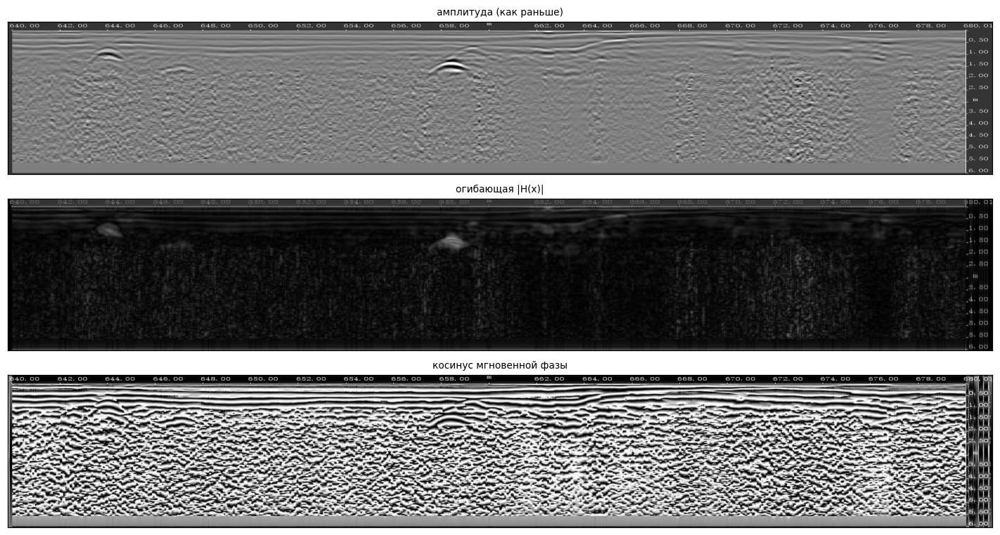

In [47]:
# Как это выглядит: обычный кадр и его атрибутные каналы
sample = sorted((WORK / "tgt_road" / "images" / "train").glob("*.jpg"))[:1]
if sample:
    a = np.asarray(Image.open(sample[0]).convert("L"), dtype=np.float32) / 255.0
    x = a - a.mean(axis=0, keepdims=True)
    an = hilbert(x, axis=0)
    fig, axes = plt.subplots(3, 1, figsize=(13, 7))
    for ax, img, t in zip(axes, [a, np.abs(an), np.cos(np.angle(an))],
                          ["амплитуда (как раньше)", "огибающая |H(x)|",
                           "косинус мгновенной фазы"]):
        ax.imshow(img, cmap="gray", aspect="auto"); ax.set_title(t, fontsize=9)
        ax.set_xticks([]); ax.set_yticks([])
    plt.tight_layout(); plt.show()

### 6.9. Фолды для перекрёстной проверки

В тесте URDD 57 кадров и 73 объекта, доверительный интервал по бутстрэпу ±13 п.п.
На одном разбиении любая разница меньше этого неотличима от случайности. Поэтому
дополнительно делается перекрёстная проверка: блоки кадров делятся на четыре фолда,
и каждый по очереди становится тестовым.

In [48]:
def build_road_fractions(fracs=(0.25, 0.5)):
    """Вложенные подвыборки обучающей части URDD с фиксированным составом.

    Штатный параметр `fraction` в ultralytics берёт первые N путей после сортировки.
    Имена материализованных файлов — это MD5 абсолютного пути исходного изображения,
    поэтому такая выборка, во-первых, не стратифицирована по классам, во-вторых,
    меняется при переносе проекта в другой каталог. Здесь подвыборки строятся явно:
    отбираются целые группы съёмки (чтобы не рвать профиль), группы перебираются в
    порядке, выравнивающем состав классов, и выборки вложены друг в друга — 25%
    является подмножеством 50%.
    """
    train_imgs = [i for i, sp in road_split.items() if sp == "train"]
    gids = sorted({road_groups[i] for i in train_imgs})
    # доминирующий класс группы — для выравнивания состава
    dom = {}
    for g in gids:
        imgs = [i for i in train_imgs if road_groups[i] == g]
        cls = tgt_r[tgt_r["image"].isin(imgs)]["cls"].value_counts()
        dom[g] = cls.index[0] if len(cls) else "пусто"
    rng = np.random.default_rng(SEED)
    by_cls = defaultdict(list)
    for g in gids:
        by_cls[dom[g]].append(g)
    for v in by_cls.values():
        rng.shuffle(v)
    order, pools = [], {k: list(v) for k, v in by_cls.items()}
    while any(pools.values()):                       # по кругу, по одной группе из класса
        for k in sorted(pools):
            if pools[k]:
                order.append(pools[k].pop())
    yamls = {}
    for frac in fracs:
        target = int(round(len(train_imgs) * frac))
        chosen, taken = set(), 0
        for g in order:
            if taken >= target:
                break
            imgs = [i for i in train_imgs if road_groups[i] == g]
            chosen.update(imgs); taken += len(imgs)
        split_map = {i: sp for i, sp in road_split.items()}
        for i in train_imgs:
            if i not in chosen:
                split_map[i] = None
        split_map = {k: v for k, v in split_map.items() if v is not None}
        name = f"tgt_road_{int(frac*100)}"
        y, counts = build_yolo_dataset(name, tgt_r, ROAD_CLASSES, split_map)
        n_tr = sum(v for (sp, c), v in counts.items() if sp == "train" and c == "кадров")
        per_cls = {c: v for (sp, c), v in counts.items() if sp == "train" and c in ROAD_CLASSES}
        print(f"  подвыборка {int(frac*100)}%: train {n_tr} кадров, классы {per_cls}")
        yamls[frac] = y
    return yamls


def build_road_folds(k=4, inner_frac=0.25):
    """K корпусов URDD с вложенной валидацией.

    Наивная схема «внешний фолд = val» смещает оценку: ultralytics использует `val`
    для выбора `best.pt` и ранней остановки, и если на нём же публиковать результат,
    мы отчитываемся по данным, на которых выбирали модель. Поэтому в каждом фолде три
    части: внешний фолд уходит в `test` и не участвует в обучении никак, из остальных
    групп выделяется внутренняя `val` для выбора весов, остальное — `train`.
    """
    groups = sorted(set(road_groups.values()))
    rng = np.random.default_rng(SEED)
    perm = rng.permutation(groups)
    folds = np.array_split(perm, k)
    yamls = []
    for i, fold in enumerate(folds):
        test_groups = set(fold.tolist())
        rest = [g for g in perm if g not in test_groups]
        n_inner = max(1, int(round(len(rest) * inner_frac)))
        inner_val = set(np.random.default_rng(SEED + i).permutation(rest)[:n_inner].tolist())
        split_map = {}
        for img in tgt_r["image"].unique():
            g = road_groups[img]
            split_map[img] = "test" if g in test_groups else ("val" if g in inner_val else "train")
        y, counts = build_yolo_dataset(f"tgt_road_fold{i}", tgt_r, ROAD_CLASSES, split_map)
        yamls.append(y)
        n = {sp: sum(v for (s_, cls), v in counts.items() if s_ == sp and cls == "кадров")
             for sp in ("train", "val", "test")}
        print(f"  фолд {i}: train {n['train']}, внутр. val {n['val']}, внешний test {n['test']} кадров")
    return yamls

road_frac_yamls = build_road_fractions((0.25, 0.5))
road_fold_yamls = build_road_folds(4)

  подвыборка 25%: train 72 кадров, классы {'Detachment': 35, 'Cavity': 16, 'Looseness': 22}
  подвыборка 50%: train 144 кадров, классы {'Looseness': 45, 'Detachment': 82, 'Cavity': 26}
  фолд 0: train 211, внутр. val 77, внешний test 103 кадров
  фолд 1: train 224, внутр. val 68, внешний test 99 кадров
  фолд 2: train 224, внутр. val 78, внешний test 89 кадров
  фолд 3: train 220, внутр. val 71, внешний test 100 кадров


### 6.10. Проверка разбиения на утечки

Финальная проверка готовых наборов: есть ли одинаковые хеши у кадров из разных
выборок. Ожидаемый ответ — ноль.

In [49]:
def leak_check(sub: pd.DataFrame, split_map: dict, thr=HAMMING_THR):
    """Проверяет исходные кадры, а не материализованные копии.

    Проверять копии бессмысленно: нормализация (перевод в градации серого и JPEG)
    сама меняет один-два бита хеша, и проверка начинает считать своими же
    артефактами то, чего в данных нет.
    """
    by_split = defaultdict(list)
    for img in sub["image"].unique():
        sp = split_map.get(img)
        if sp is None:
            continue
        try:
            by_split[sp].append(frame_hash(img))
        except Exception:
            pass
    out, keys = [], list(by_split)
    for i in range(len(keys)):
        for j in range(i + 1, len(keys)):
            n = sum(1 for a in by_split[keys[i]] if any((a - b) <= thr for b in by_split[keys[j]]))
            out.append({"пара": f"{keys[i]}–{keys[j]}", "совпадающих кадров": n})
    return pd.DataFrame(out)

for name, sub_df, split_map in [("SRC_TUNNEL", src, src_split),
                                ("TGT_CONCRETE", tgt_c, pgpr_split),
                                ("TGT_ROAD", tgt_r, road_split)]:
    df = leak_check(sub_df, split_map)
    if len(df):
        print(name); display(df)

SRC_TUNNEL


,пара,совпадающих кадров
0,train–val,0


TGT_CONCRETE


,пара,совпадающих кадров
0,test–val,0
1,test–train,0
2,val–train,0


TGT_ROAD


,пара,совпадающих кадров
0,train–val,0
1,train–test,0
2,val–test,0


---
## 7. Метрики качества

### 7.1. Какие метрики и почему

**Основные.**

* **mAP@0.5** — средняя точность при пороге IoU 0.5, усреднённая по классам. Главная
  метрика работы. Более строгие пороги IoU здесь плохо подходят: граница дефекта на
  B-scan размыта, и, по данным литературы, два эксперта обведут одну и ту же пустоту
  рамками с IoU около 0.7–0.8 (собственного измерения согласия экспертов нет).
  Требовать от модели IoU 0.9 — значит мерить шум разметки.
* **mAP@0.5:0.95** — для сравнения с литературой, с учётом оговорки выше.
* **Precision и recall по каждому классу.** При дисбалансе 500:1 среднее по всем
  объектам бесполезно: модель, которая идеально находит арматуру и не находит воду,
  получит неплохой средний балл.

**Практическая метрика.**

Ошибки стоят по-разному: пропущенная пустота — это риск обрушения и остановки
движения, ложная тревога — лишний выезд бригады на ручную проверку. Поэтому
используются **F2-мера** (recall в ней весит вчетверо больше precision) и
**recall при точности 0.5** — сколько дефектов найдёт модель, если на каждое верное
срабатывание допускается одна ложная тревога.

$$F_\beta = (1+\beta^2)\frac{PR}{\beta^2 P + R}, \quad \beta = 2$$

**Проверка значимости.** На сотне тестовых кадров разница в mAP между двумя моделями
может быть случайной. Поэтому считается **парный бутстрэп** по кадрам: обе модели
оцениваются на одной и той же случайной выборке кадров, и доверительный интервал
строится для самой разницы. Сравнивать два отдельных интервала нельзя: модели
ошибаются на одних и тех же трудных кадрах, и то, что интервалы пересекаются, ещё не
значит, что разницы нет.

**Какие классы усредняются.** macro mAP усредняет только классы, которые есть в
выборке. В URDD класс Water-rich есть в train и val (по три рамки), но его нет в
test. Значит, на валидации mAP усредняется по четырём классам, а на тесте — по трём.
Поэтому рядом с каждой метрикой выводятся состав классов и число объектов.

In [50]:
def f_beta(precision, recall, beta=2.0):
    if precision + recall == 0:
        return 0.0
    b2 = beta ** 2
    return (1 + b2) * precision * recall / (b2 * precision + recall)


def metrics_table(result, class_names):
    """Поклассовая сводка из результата ultralytics .val().

    Индексы в result.box идут не по всем классам, а только по тем, что встретились
    в наборе: соответствие задаёт ap_class_index. Если класса в валидации нет,
    честный ответ — NaN, а не чужие числа.
    """
    box = result.box
    present = {int(c): i for i, c in enumerate(getattr(box, "ap_class_index", []))}
    rows = []
    for ci, name in enumerate(class_names):
        if ci in present:
            try:
                p, r, ap50, ap = box.class_result(present[ci])
            except Exception:
                p = r = ap50 = ap = np.nan
        else:
            p = r = ap50 = ap = np.nan
        # Сочетание «precision = 1, recall = 0, AP заметно больше нуля» не является
        # ошибкой библиотеки, и читать его нужно так. Ultralytics выбирает ОДИН порог
        # уверенности — тот, что максимизирует сглаженный F1, усреднённый по всем
        # классам, — и печатает P и R именно в этой точке. AP при этом считается по
        # всей PR-кривой. Поэтому редкий класс, все предсказания которого имеют низкую
        # уверенность, показывает R = 0 при общем пороге и одновременно ненулевую AP.
        # Столбец ниже помечает такие строки: AP по ним есть, но эксплуатационного
        # смысла при едином пороге у класса нет.
        single_thr_zero = (not np.isnan(r)) and r < 0.05
        rows.append({"класс": name, "precision": p, "recall": r,
                     "mAP@0.5": ap50, "mAP@0.5:0.95": ap,
                     "F2": f_beta(p, r) if not np.isnan(p) else np.nan,
                     "оговорка": "" if not single_thr_zero else "R≈0 при общем пороге"})
    df = pd.DataFrame(rows)
    df.loc[len(df)] = {"класс": "macro", "precision": df["precision"].mean(),
                       "recall": df["recall"].mean(), "mAP@0.5": df["mAP@0.5"].mean(),
                       "mAP@0.5:0.95": df["mAP@0.5:0.95"].mean(), "F2": df["F2"].mean(),
                       "оговорка": ""}
    return df.round(3)


print("метрики определены")

метрики определены


Замечание об инструменте: `ultralytics` считает mAP сразу по всему набору, а не по
отдельным кадрам. Для бутстрэпа по кадрам нужно пересчитывать сопоставление рамок
самостоятельно. Ниже это и сделано: предсказания и разметка собираются по кадрам, а
затем метрика много раз пересчитывается на случайных выборках кадров с возвращением.

In [51]:
def collect_predictions(model, data_yaml, split="test", conf=0.001, iou=0.6, imgsz=None):
    """Собирает предсказания и истину покадрово для последующего пересчёта метрик.

    Два отличия от `model.val()`, оба намеренные и оба принципиальные.

    1. Разрешение берётся у самой модели: дорожные детекторы обучены при 960, и
       предсказание при 640 занижает качество в разы.
    2. Используется `predict()`, то есть NMS с `multi_label=False`: каждая рамка
       получает один класс — тот, у которого максимальный балл. `val()` внутри
       вызывает NMS с `multi_label=True`, и тогда одна и та же рамка выдаётся под
       всеми классами, чей балл выше `conf`. Для AP это даёт длинный хвост дубликатов
       и завышает метрику редкого класса; для эксплуатации такой режим бессмыслен.
       Разбор конкретного случая — в разделе 11.13.
    """
    if imgsz is None:
        imgsz = int(getattr(model, "overrides", {}).get("imgsz", 640) or 640)
    import yaml
    cfg = yaml.safe_load(open(data_yaml))
    root = Path(cfg["path"])
    img_dir = root / cfg.get(split, f"images/{split}")
    lbl_dir = root / "labels" / split
    paths = sorted(img_dir.glob("*.jpg"))
    frames_out = []
    for i in range(0, len(paths), 32):
        batch = paths[i:i + 32]
        res = model.predict([str(p) for p in batch], conf=conf, iou=iou, imgsz=imgsz,
                            verbose=False, device=DEVICE)
        for p, r in zip(batch, res):
            gt = []
            lp = lbl_dir / f"{p.stem}.txt"
            if lp.exists():
                for line in open(lp):
                    v = line.split()
                    if len(v) >= 5:
                        gt.append([int(float(v[0]))] + [float(x) for x in v[1:5]])
            pred = []
            if r.boxes is not None and len(r.boxes):
                xywhn = r.boxes.xywhn.cpu().numpy()
                cls = r.boxes.cls.cpu().numpy().astype(int)
                conf_ = r.boxes.conf.cpu().numpy()
                pred = [[int(c), *b, float(s)] for c, b, s in zip(cls, xywhn, conf_)]
            frames_out.append({"image": str(p), "gt": gt, "pred": pred})
    return frames_out


def iou_xywh(a, b):
    ax1, ay1, ax2, ay2 = a[0] - a[2] / 2, a[1] - a[3] / 2, a[0] + a[2] / 2, a[1] + a[3] / 2
    bx1, by1, bx2, by2 = b[0] - b[2] / 2, b[1] - b[3] / 2, b[0] + b[2] / 2, b[1] + b[3] / 2
    ix1, iy1 = max(ax1, bx1), max(ay1, by1)
    ix2, iy2 = min(ax2, bx2), min(ay2, by2)
    iw, ih = max(0.0, ix2 - ix1), max(0.0, iy2 - iy1)
    inter = iw * ih
    ua = (ax2 - ax1) * (ay2 - ay1) + (bx2 - bx1) * (by2 - by1) - inter
    return inter / ua if ua > 0 else 0.0


def ap_from_frames(frames_list, n_classes, iou_thr=0.5, conf_thr=0.001):
    """AP по классам на произвольном подмножестве кадров.

    Интерполяция как в COCO: precision берётся максимальной справа и усредняется по
    101 равномерному уровню recall. Это не «все точки» VOC2010 и не 11 точек VOC2007.
    """
    aps, prs = {}, {}
    for c in range(n_classes):
        scored, n_gt = [], 0
        for fr in frames_list:
            gts = [g[1:] for g in fr["gt"] if g[0] == c]
            n_gt += len(gts)
            used = [False] * len(gts)
            preds = sorted([p for p in fr["pred"] if p[0] == c and p[5] >= conf_thr],
                           key=lambda x: -x[5])
            for p in preds:
                best, bi = 0.0, -1
                for gi, g in enumerate(gts):
                    if used[gi]:
                        continue
                    v = iou_xywh(p[1:5], g)
                    if v > best:
                        best, bi = v, gi
                if best >= iou_thr and bi >= 0:
                    used[bi] = True
                    scored.append((p[5], 1))
                else:
                    scored.append((p[5], 0))
        if n_gt == 0:
            aps[c], prs[c] = np.nan, (np.nan, np.nan)
            continue
        scored.sort(key=lambda x: -x[0])
        tp = np.cumsum([s[1] for s in scored]) if scored else np.array([0])
        fp = np.cumsum([1 - s[1] for s in scored]) if scored else np.array([0])
        rec = tp / n_gt
        prec = tp / np.maximum(tp + fp, 1e-9)
        ap = 0.0
        for t in np.linspace(0, 1, 101):
            p_at = prec[rec >= t].max() if np.any(rec >= t) else 0.0
            ap += p_at / 101
        aps[c] = ap
        prs[c] = (prec[-1] if len(prec) else 0.0, rec[-1] if len(rec) else 0.0)
    return aps, prs


def recall_at_precision(frames_list, n_classes, target_precision=0.5, iou_thr=0.5):
    """Эксплуатационная метрика: какой recall достижим, если согласиться на точность
    не ниже target_precision. Порог уверенности подбирается по PR-кривой класса."""
    out = {}
    for c in range(n_classes):
        scored, n_gt = [], 0
        for fr in frames_list:
            gts = [g[1:] for g in fr["gt"] if g[0] == c]
            n_gt += len(gts)
            used = [False] * len(gts)
            for p_ in sorted([p for p in fr["pred"] if p[0] == c], key=lambda x: -x[5]):
                best, bi = 0.0, -1
                for gi, g in enumerate(gts):
                    if used[gi]:
                        continue
                    v = iou_xywh(p_[1:5], g)
                    if v > best:
                        best, bi = v, gi
                if best >= iou_thr and bi >= 0:
                    used[bi] = True
                    scored.append((p_[5], 1))
                else:
                    scored.append((p_[5], 0))
        if n_gt == 0:
            out[c] = (np.nan, np.nan)      # класса нет в выборке — метрика неопределена
            continue
        if not scored:
            out[c] = (0.0, np.nan)         # класс есть, но модель не выдала ни одной рамки
            continue
        scored.sort(key=lambda x: -x[0])
        conf = np.array([s[0] for s in scored])
        tp = np.cumsum([s[1] for s in scored])
        fp = np.cumsum([1 - s[1] for s in scored])
        prec = tp / np.maximum(tp + fp, 1e-9)
        rec = tp / n_gt
        # Порогом можно отсечь только целую группу одинаковых confidence: промежуточная
        # точка внутри такой группы на PR-кривой существует, но ни одним порогом
        # не достигается. Поэтому рассматриваются только границы групп.
        edges = np.flatnonzero(np.r_[conf[1:] != conf[:-1], True])
        ok = edges[prec[edges] >= target_precision]
        out[c] = (float(rec[ok].max()), float(conf[ok[np.argmax(rec[ok])]])) if len(ok) else (0.0, np.nan)
    return out


def pr_at_threshold(frames_list, n_classes, thresholds, iou_thr=0.5):
    """Precision и recall при ЗАДАННОМ пороге уверенности для каждого класса.

    Нужна, чтобы проверить порог, выбранный на другой выборке: `recall_at_precision`
    подбирает порог по той же кривой, на которой меряет, и потому систематически
    завышает достижимое качество.
    """
    out = {}
    for c in range(n_classes):
        thr = thresholds.get(c, np.nan)
        tp = fp = n_gt = 0
        for fr in frames_list:
            gts = [g[1:] for g in fr["gt"] if g[0] == c]
            n_gt += len(gts)
            used = [False] * len(gts)
            if np.isnan(thr):
                continue
            for p_ in sorted([q for q in fr["pred"] if q[0] == c and q[5] >= thr],
                             key=lambda x: -x[5]):
                best, bi = 0.0, -1
                for gi, g in enumerate(gts):
                    if used[gi]:
                        continue
                    v = iou_xywh(p_[1:5], g)
                    if v > best:
                        best, bi = v, gi
                if best >= iou_thr and bi >= 0:
                    used[bi] = True
                    tp += 1
                else:
                    fp += 1
        if n_gt == 0:
            out[c] = (np.nan, np.nan, 0)
        else:
            out[c] = (tp / (tp + fp) if tp + fp else np.nan, tp / n_gt, n_gt)
    return out


def bootstrap_ci(frames_list, n_classes, n_boot=300, iou_thr=0.5, seed=SEED):
    rng = np.random.default_rng(seed)
    vals = []
    idx = np.arange(len(frames_list))
    for _ in range(n_boot):
        pick = rng.choice(idx, len(idx), replace=True)
        aps, _ = ap_from_frames([frames_list[i] for i in pick], n_classes, iou_thr)
        v = np.nanmean(list(aps.values()))
        if not np.isnan(v):
            vals.append(v)
    if not vals:
        return (np.nan, np.nan, np.nan)
    return (float(np.mean(vals)), float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5)))

def paired_bootstrap(frames_a, frames_b, n_classes, n_boot=1000, iou_thr=0.5, seed=SEED):
    """Парный бутстрэп разницы macro AP между двумя моделями.

    Модели оцениваются на одних и тех же кадрах, поэтому их ошибки зависимы: кадр,
    трудный для одной, обычно труден и для другой. Сравнивать два независимо
    построенных доверительных интервала неверно — непересечение достаточно для вывода
    о различии, но пересечение ничего не доказывает. Правильная величина — интервал
    самой разницы, посчитанный по одной и той же перевыборке кадров.

    Возвращает (наблюдаемая разница, нижняя граница, верхняя граница, доля перевыборок
    с положительной разницей).
    """
    assert len(frames_a) == len(frames_b), "нужны одни и те же кадры в одном порядке"
    rng = np.random.default_rng(seed)
    base_a = np.nanmean(list(ap_from_frames(frames_a, n_classes, iou_thr)[0].values()))
    base_b = np.nanmean(list(ap_from_frames(frames_b, n_classes, iou_thr)[0].values()))
    idx = np.arange(len(frames_a))
    diffs = []
    for _ in range(n_boot):
        pick = rng.choice(idx, len(idx), replace=True)
        a = np.nanmean(list(ap_from_frames([frames_a[i] for i in pick], n_classes, iou_thr)[0].values()))
        b = np.nanmean(list(ap_from_frames([frames_b[i] for i in pick], n_classes, iou_thr)[0].values()))
        if not (np.isnan(a) or np.isnan(b)):
            diffs.append(b - a)
    if not diffs:
        return (np.nan,) * 4
    d = np.array(diffs)
    return (float(base_b - base_a), float(np.percentile(d, 2.5)),
            float(np.percentile(d, 97.5)), float((d > 0).mean()))


print("покадровый пересчёт метрик, recall@precision и бутстрэп (в том числе парный) готовы")

покадровый пересчёт метрик, recall@precision и бутстрэп (в том числе парный) готовы


---
## 8. Модель и аугментации

### 8.1. Выбор архитектуры

Требования к модели, которые следуют из EDA:

* размеры объектов различаются на три порядка (арматура против границы на весь
  кадр) — нужна голова, работающая на нескольких масштабах (FPN/PAN);
* данных мало (сотни кадров на набор) — нужна модель, которая хорошо дообучается
  с предобученных весов без долгого разогрева, в отличие от трансформерных
  детекторов;
* модель должна успевать за съёмкой на бортовом компьютере — нужен одностадийный
  детектор.

| Кандидат | Плюсы | Минусы | Решение |
|---|---|---|---|
| Faster R-CNN | точный на мелких объектах, проверенный | двухстадийный, медленный, хуже дообучается на сотнях кадров | нет |
| DETR / RT-DETR | не нужен NMS, хорошо учитывает весь кадр | нужны тысячи примеров и долгое обучение | нет |
| **YOLO11** | без якорей, PAN-FPN на трёх масштабах, хорошие веса COCO, быстрый | чувствителен к настройке аугментаций | **да** |
| U-Net (сегментация) | точность до пикселя | нет разметки по пикселям, дорого размечать | нет |

Выбран **YOLO11s** (9.4 млн параметров) — компромисс между ёмкостью модели и
риском переобучения на нескольких сотнях кадров.

### 8.2. Аугментации: что допустимо физически

Георадарограмма — не фотография. Ось Y — это время, и у него есть направление:
сигнал всегда идёт сверху вниз, прямая волна всегда вверху кадра. Поэтому часть
обычных аугментаций портит данные.

| Аугментация | Можно | Почему |
|---|---|---|
| Горизонтальное отражение | **да** | то же самое, что пройти участок в обратную сторону |
| Вертикальное отражение | **нет** | перевернуло бы время: отражение пришло бы раньше импульса |
| Поворот | **нет** | строка изображения перестаёт соответствовать моменту времени |
| Сдвиг по X | да | другое начало профиля |
| Небольшой сдвиг по Y | да | другая задержка запуска, другое положение антенны |
| Масштаб | умеренно | другая скорость движения и окно по времени |
| Яркость/контраст | да | разное усиление приёмника |
| Оттенок/насыщенность | нет смысла | изображение одноканальное |
| Mosaic | ограниченно | склейка кадров нефизична, но помогает при малых данных; выключается на последних эпохах |
| MixUp | **нет** | смесь двух радарограмм не соответствует никакой реальной среде |

Ниже эта политика задаётся явными гиперпараметрами. В `ultralytics` 8.4 по
умолчанию уже `flipud = 0.0` и `mixup = 0.0`, то есть опасные преобразования
выключены. Реальные изменения относительно умолчаний: `mosaic` 1.0 → 0.6,
`close_mosaic` 10 → 15 эпох, `scale` 0.5 → 0.35, `hsv_h` и `hsv_s` → 0 (бессмысленны
для серых картинок), `erasing` 0.4 → 0.1, умеренная `hsv_v` оставлена. Значения
`flipud` и `mixup` прописаны явно, чтобы политика не зависела от версии библиотеки.

In [52]:
AUG = dict(
    hsv_h=0.0,        # оттенок не имеет смысла для одноканальных данных
    hsv_s=0.0,        # насыщенность — тоже
    hsv_v=0.35,       # яркость: моделирует разное усиление приёмника
    degrees=0.0,      # повороты запрещены
    translate=0.08,   # небольшой сдвиг по обеим осям
    scale=0.35,       # масштаб: разная скорость движения антенны
    shear=0.0,
    perspective=0.0,
    flipud=0.0,       # вертикальное отражение запрещено физикой
    fliplr=0.5,       # горизонтальное — допустимо
    mosaic=0.6,
    close_mosaic=15,  # последние 15 эпох — без мозаики, на «чистых» кадрах
    mixup=0.0,
    copy_paste=0.0,
    erasing=0.1,
)

TRAIN_COMMON = dict(
    model="weights/yolo11s.pt",
    imgsz=640,
    batch=16,
    optimizer="AdamW",
    lr0=0.002,
    lrf=0.01,
    warmup_epochs=3,
    patience=30,
    cos_lr=True,
    seed=SEED,
    deterministic=True,
    device=DEVICE,
    workers=8,
    val=True,
    plots=True,
    verbose=False,
    project=str(RUNS),
    exist_ok=True,
    **AUG,
)

print("политика аугментаций и общие гиперпараметры заданы")
pd.Series(AUG).to_frame("значение")

политика аугментаций и общие гиперпараметры заданы


,значение
hsv_h,0.00
hsv_s,0.00
hsv_v,0.35
degrees,0.00
translate,0.08
scale,0.35
shear,0.00
perspective,0.00
flipud,0.00
fliplr,0.50


---
## 9. Обучение

### 9.1. План экспериментов

Проверяется гипотеза: предобучение на синтетике помогает на реальных данных, и тем
сильнее, чем меньше реальной разметки.

| № | Эксперимент | Данные | Старт | Что показывает |
|---|---|---|---|---|
| E0 | предобучение | TunGPR (синтетика, 6 классов) | COCO | качество на «чистой» физике |
| E1a | железобетон, базовая модель | P-GPR (steel, pipe) | COCO | результат обычного переноса с COCO |
| E1b | железобетон, перенос | P-GPR | **E0** | вклад синтетики для арматуры и труб |
| E2a | дороги, базовая модель | URDD (4 класса дефектов) | COCO | базовый уровень на реальных дефектах |
| E2b | дороги, перенос | URDD | **E0** | вклад синтетики для дефектов |
| E3 | зависимость от объёма данных | URDD, 25 / 50 / 100% обучающих кадров, 60 эпох | COCO / E0 | растёт ли выигрыш, когда разметки мало |

Дополнительные эксперименты E4, E6–E9 описаны в разделах 9.6–9.10, классификация
(E5) — в разделе 10.

Во всех запусках одинаковые гиперпараметры и фиксированный seed; меняются только
стартовые веса и объём обучающей выборки.

In [53]:
from ultralytics import YOLO
import time, yaml, io, contextlib, json, hashlib

RESULTS = []

# Обучение печатает прогресс-бар на каждую эпоху: в ноутбуке это десятки тысяч строк
# служебного вывода, которые ничего не добавляют к работе. Поэтому вывод обучения
# перехватывается, а в ячейке остаётся сводка; кривые обучения ultralytics сохраняет
# в runs/<эксперимент>/results.png и они показываются в разделе анализа.
@contextlib.contextmanager
def quiet():
    buf = io.StringIO()
    with contextlib.redirect_stdout(buf), contextlib.redirect_stderr(buf):
        yield buf

def dataset_fingerprint(data_yaml):
    """Отпечаток корпуса: состав подвыборок и содержимое разметки.

    Считается по именам файлов и по строкам разметки, а не по пикселям: пересжатие
    изображения с тем же содержимым не должно считаться новым набором данных.
    """
    cfg = yaml.safe_load(open(data_yaml))
    root = Path(cfg["path"])
    h = hashlib.sha256()
    h.update(json.dumps(cfg.get("names", {}), sort_keys=True, ensure_ascii=False).encode())
    for split in ("train", "val", "test"):
        if split not in cfg:
            continue
        lbl = root / "labels" / split
        if not lbl.exists():
            continue
        for f in sorted(lbl.glob("*.txt")):
            h.update(f.name.encode())
            h.update(f.read_bytes())
    return h.hexdigest()[:16]


def actual_epochs(tag):
    """Сколько эпох обучение реально прошло: при ранней остановке это не бюджет."""
    csv = RUNS / tag / "results.csv"
    if not csv.exists():
        return np.nan
    try:
        return int(pd.read_csv(csv).shape[0])
    except Exception:
        return np.nan


def train_run(tag, data_yaml, epochs, weights=None, fraction=1.0, imgsz=640, batch=16, **over):
    cfg = dict(TRAIN_COMMON)
    cfg.update(data=str(data_yaml), epochs=epochs, name=tag, imgsz=imgsz, batch=batch,
               fraction=fraction)
    cfg.pop("model")
    cfg.update(over)
    init = weights or TRAIN_COMMON["model"]
    t0 = time.time()
    # Уже обученные веса переиспользуются: полный прогон ноутбука со всеми запусками
    # занимает около двух часов, и повторять обучение ради правки текста или нового
    # раздела анализа бессмысленно. Чтобы переобучить с нуля, достаточно удалить
    # каталог runs/<эксперимент>.
    #
    # Но переиспользовать веса «по имени каталога» нельзя: корпуса пересобираются при
    # каждом прогоне, и после изменения подготовки данных старые веса оценивались бы
    # на новом разбиении — вплоть до того, что кадры из их обучения попадут в новый
    # тест. Поэтому рядом с весами хранится манифест: отпечаток данных, стартовые веса
    # и конфигурация. При несовпадении обучение повторяется.
    manifest_path = RUNS / tag / "manifest.json"
    manifest = {"data_fingerprint": dataset_fingerprint(data_yaml),
                "init": Path(init).name,
                "cfg": {k: str(v) for k, v in sorted(cfg.items()) if k != "name"}}
    done = RUNS / tag / "weights" / "best.pt"
    reusable = False
    if done.exists() and manifest_path.exists():
        try:
            reusable = json.loads(manifest_path.read_text()) == manifest
        except Exception:
            reusable = False
        if not reusable:
            print(f"[{tag}] манифест не совпал — данные или настройки изменились, переобучаем")
    if reusable:
        model = YOLO(str(done))
        trained = False
    else:
        model = YOLO(init)
        with quiet():
            model.train(**cfg)
        trained = True
        manifest_path.parent.mkdir(parents=True, exist_ok=True)
        manifest_path.write_text(json.dumps(manifest, ensure_ascii=False, indent=1))
    dt = time.time() - t0

    names = list(yaml.safe_load(open(data_yaml))["names"].values())
    out = {"эксперимент": tag, "старт": Path(init).stem,
           "эпох (бюджет)": epochs, "эпох фактически": actual_epochs(tag),
           "доля обуч. данных": fraction,
           "время, мин": round(dt / 60, 1) if trained else np.nan}

    with quiet():
        val_res = model.val(data=str(data_yaml), split="val", verbose=False, plots=False, device=DEVICE)
    out["val mAP@0.5"] = float(val_res.box.map50)
    out["val mAP@0.5:0.95"] = float(val_res.box.map)

    cfg_data = yaml.safe_load(open(data_yaml))
    if "test" in cfg_data:
        with quiet():
            test_res = model.val(data=str(data_yaml), split="test", verbose=False, plots=False, device=DEVICE)
        out["test mAP@0.5"] = float(test_res.box.map50)
        out["test mAP@0.5:0.95"] = float(test_res.box.map)
        out["_test_result"] = test_res
    out["_model"] = model
    out["_data"] = str(data_yaml)
    out["_names"] = names
    out["_weights"] = str(RUNS / tag / "weights" / "best.pt")
    RESULTS.append(out)
    out["обучено сейчас"] = trained
    print(f"[{tag}]{'' if trained else ' (веса переиспользованы)'} val mAP@0.5={out['val mAP@0.5']:.3f}"
          + (f", test mAP@0.5={out.get('test mAP@0.5', float('nan')):.3f}" if "test mAP@0.5" in out else "")
          + (f", обучение {out['время, мин']} мин" if trained else ""))
    return out

### 9.2. E0 — предобучение на синтетике TunGPR

Синтетика играет роль «учебника по физике»: модель видит упрощённые, но правильные
примеры всех шести классов. Разрешение 512 совпадает с размером кадров TunGPR.

In [54]:
e0 = train_run("e0_src_tunnel", src_yaml, epochs=60, imgsz=512, batch=32)
display(metrics_table(e0["_test_result"] if "_test_result" in e0 else
                      e0["_model"].val(data=str(src_yaml), split="val", verbose=False, plots=False, device=DEVICE),
                      TUNNEL_CLASSES))

Ultralytics 8.4.154 🚀 Python-3.11.5 torch-2.7.0.dev20250114+cu126 CUDA:0 (NVIDIA GeForce RTX 3090, 24253MiB)
YOLO11s summary (fused): 100 layers, 9,415,122 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4477.7±712.0 MB/s, size: 71.6 KB)
val: New cache created: /home/ubuntu/projects/ml/rzhd/work/src_tunnel/labels/val.cache
                   all        148       1020      0.873      0.927      0.896      0.749
Speed: 0.2ms preprocess, 1.9ms inference, 0.0ms loss, 0.3ms postprocess per image
[e0_src_tunnel] (веса переиспользованы) val mAP@0.5=0.896
Ultralytics 8.4.154 🚀 Python-3.11.5 torch-2.7.0.dev20250114+cu126 CUDA:0 (NVIDIA GeForce RTX 3090, 24253MiB)
YOLO11s summary (fused): 100 layers, 9,415,122 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4961.0±1015.5 MB/s, size: 71.1 KB)
val: Scanning /home/ubuntu/projects/ml/rzhd/work/src_tunnel/labels/val.cache... 148 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━

,класс,precision,recall,mAP@0.5,mAP@0.5:0.95,F2,оговорка
0,rebar,0.999,1.000,0.995,0.920,1.000,
1,grout_surface,0.995,1.000,0.995,0.970,0.999,
2,rock_surface,0.976,0.993,0.993,0.900,0.990,
3,separation,0.365,0.596,0.430,0.182,0.529,
4,air_void,0.970,0.974,0.975,0.700,0.973,
5,water_void,0.932,1.000,0.991,0.819,0.986,
6,macro,0.873,0.927,0.896,0.749,0.913,


### 9.3. E1 — реальный железобетон: арматура и трубы

In [55]:
e1a = train_run("e1a_concrete_coco", pgpr_yaml, epochs=80)
e1b = train_run("e1b_concrete_tungpr", pgpr_yaml, epochs=80, weights=e0["_weights"])

Ultralytics 8.4.154 🚀 Python-3.11.5 torch-2.7.0.dev20250114+cu126 CUDA:0 (NVIDIA GeForce RTX 3090, 24253MiB)
YOLO11s summary (fused): 100 layers, 9,413,574 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3171.7±1516.5 MB/s, size: 32.0 KB)
val: New cache created: /home/ubuntu/projects/ml/rzhd/work/tgt_concrete/labels/val.cache
                   all         54        316      0.766      0.825      0.834       0.39
Speed: 0.1ms preprocess, 3.4ms inference, 0.0ms loss, 0.3ms postprocess per image
Ultralytics 8.4.154 🚀 Python-3.11.5 torch-2.7.0.dev20250114+cu126 CUDA:0 (NVIDIA GeForce RTX 3090, 24253MiB)
YOLO11s summary (fused): 100 layers, 9,413,574 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2393.3±581.2 MB/s, size: 21.2 KB)
val: New cache created: /home/ubuntu/projects/ml/rzhd/work/tgt_concrete/labels/test.cache
                   all         31        183       0.63      0.613      0.564      0.255
Speed:

### 9.4. E2 — реальные дороги: пустоты, отслоение, разуплотнение, вода

In [56]:
# Кадры URDD вытянутые (1763×548), а объекты мелкие: при imgsz=640 полезное
# содержимое после letterbox сжимается до полосы 640×199, и пустота размером 5%
# ширины превращается в три десятка пикселей. Поэтому для дорожного домена
# разрешение выше.
e2a = train_run("e2a_road_coco", urdd_yaml, epochs=80, imgsz=960, batch=12)
e2b = train_run("e2b_road_tungpr", urdd_yaml, epochs=80, weights=e0["_weights"],
                imgsz=960, batch=12)

Ultralytics 8.4.154 🚀 Python-3.11.5 torch-2.7.0.dev20250114+cu126 CUDA:0 (NVIDIA GeForce RTX 3090, 24253MiB)
YOLO11s summary (fused): 100 layers, 9,414,348 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5731.0±466.5 MB/s, size: 244.0 KB)
val: New cache created: /home/ubuntu/projects/ml/rzhd/work/tgt_road/labels/val.cache
                   all         58         81       0.46      0.609      0.521      0.302
Speed: 0.2ms preprocess, 2.6ms inference, 0.0ms loss, 0.3ms postprocess per image
Ultralytics 8.4.154 🚀 Python-3.11.5 torch-2.7.0.dev20250114+cu126 CUDA:0 (NVIDIA GeForce RTX 3090, 24253MiB)
YOLO11s summary (fused): 100 layers, 9,414,348 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5499.7±351.0 MB/s, size: 220.2 KB)
val: New cache created: /home/ubuntu/projects/ml/rzhd/work/tgt_road/labels/test.cache
                   all         57         73      0.544       0.48      0.428      0.175
Speed: 0.2ms 

### 9.5. E3 — зависимость от объёма реальной разметки

Если гипотеза верна, разница между базовой моделью и моделью с предобучением на
синтетике должна расти, когда реальных данных становится меньше: именно при
нехватке данных знания из синтетики полезнее всего.

In [57]:
# Точка 100% считается здесь же, с тем же бюджетом в 60 эпох. Брать для неё
# результаты E2 (80 эпох) нельзя: тогда крайняя точка кривой отличалась бы от
# остальных не только объёмом данных, но и длительностью обучения.
#
# Подвыборки берутся из заранее построенных корпусов (раздел 6.9), а не параметром
# `fraction`: он отбирает файлы по порядку имён и потому не стратифицирован.
# Оговорка, которая остаётся: одинаковое число эпох при вчетверо меньшей выборке
# означает вчетверо меньше шагов оптимизации, так что кривая смешивает два фактора —
# объём данных и длину обучения.
for frac in (0.25, 0.5, 1.0):
    y = urdd_yaml if frac == 1.0 else road_frac_yamls[frac]
    train_run(f"e3a_road_coco_{int(frac*100)}", y, epochs=60, imgsz=960, batch=12)
    train_run(f"e3b_road_tungpr_{int(frac*100)}", y, epochs=60,
              weights=e0["_weights"], imgsz=960, batch=12)

Ultralytics 8.4.154 🚀 Python-3.11.5 torch-2.7.0.dev20250114+cu126 CUDA:0 (NVIDIA GeForce RTX 3090, 24253MiB)
YOLO11s summary (fused): 100 layers, 9,414,348 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5928.8±460.0 MB/s, size: 234.6 KB)
val: New cache created: /home/ubuntu/projects/ml/rzhd/work/tgt_road_25/labels/val.cache
                   all         58         81      0.178      0.345      0.214     0.0764
Speed: 0.2ms preprocess, 1.6ms inference, 0.0ms loss, 0.3ms postprocess per image
Ultralytics 8.4.154 🚀 Python-3.11.5 torch-2.7.0.dev20250114+cu126 CUDA:0 (NVIDIA GeForce RTX 3090, 24253MiB)
YOLO11s summary (fused): 100 layers, 9,414,348 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5513.2±468.7 MB/s, size: 215.2 KB)
val: New cache created: /home/ubuntu/projects/ml/rzhd/work/tgt_road_25/labels/test.cache
                   all         57         73      0.263      0.526      0.273       0.13
Speed: 

### 9.6. E4 — проверка политики аугментаций

В разделе 8.2 сказано, что вертикальное отражение, повороты и mixup не подходят для
георадарограмм. Это проверяется напрямую: эксперимент E2b повторяется с «наивными»
настройками — `flipud=0.5`, `mixup=0.15`, `degrees=10`. Это не умолчания `ultralytics`
(там все три равны нулю), а типичные значения для обычных фотографий, перенесённые
на радарограммы без учёта физики.

In [58]:
e4 = train_run("e4_road_naive_aug", urdd_yaml, epochs=80, weights=e0["_weights"],
               imgsz=960, batch=12, flipud=0.5, mixup=0.15, degrees=10.0)

Ultralytics 8.4.154 🚀 Python-3.11.5 torch-2.7.0.dev20250114+cu126 CUDA:0 (NVIDIA GeForce RTX 3090, 24253MiB)
YOLO11s summary (fused): 100 layers, 9,414,348 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 6356.1±646.6 MB/s, size: 242.4 KB)
                   all         58         81      0.526      0.571      0.487       0.25
Speed: 0.2ms preprocess, 1.6ms inference, 0.0ms loss, 0.4ms postprocess per image
Ultralytics 8.4.154 🚀 Python-3.11.5 torch-2.7.0.dev20250114+cu126 CUDA:0 (NVIDIA GeForce RTX 3090, 24253MiB)
YOLO11s summary (fused): 100 layers, 9,414,348 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 6073.5±816.8 MB/s, size: 239.4 KB)
                   all         57         73      0.445      0.587      0.556      0.274
Speed: 0.2ms preprocess, 1.6ms inference, 0.0ms loss, 0.4ms postprocess per image
[e4_road_naive_aug] (веса переиспользованы) val mAP@0.5=0.487, test mAP@0.5=0.556


### 9.7. E6 — дополнительные каналы вместо одной амплитуды

Те же данные URDD, те же 60 эпох и то же разрешение, что в E3 на полном объёме.
Меняется только вход: вместо градаций серого — три канала «амплитуда, огибающая,
косинус фазы» (раздел 6.8).

In [59]:
if road_attr_yaml:
    e6 = train_run("e6_road_attr", road_attr_yaml, epochs=60, imgsz=960, batch=12)

Ultralytics 8.4.154 🚀 Python-3.11.5 torch-2.7.0.dev20250114+cu126 CUDA:0 (NVIDIA GeForce RTX 3090, 24253MiB)
YOLO11s summary (fused): 100 layers, 9,414,348 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 7235.5±1438.1 MB/s, size: 519.9 KB)
val: New cache created: /home/ubuntu/projects/ml/rzhd/work/tgt_road_attr/labels/val.cache
                   all         58         81      0.448      0.525      0.574      0.329
Speed: 0.2ms preprocess, 1.6ms inference, 0.0ms loss, 0.3ms postprocess per image
Ultralytics 8.4.154 🚀 Python-3.11.5 torch-2.7.0.dev20250114+cu126 CUDA:0 (NVIDIA GeForce RTX 3090, 24253MiB)
YOLO11s summary (fused): 100 layers, 9,414,348 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 7501.2±1094.6 MB/s, size: 519.5 KB)
val: New cache created: /home/ubuntu/projects/ml/rzhd/work/tgt_road_attr/labels/test.cache
                   all         57         73      0.523      0.279      0.352      0.178
S

### 9.8. E7 — детектор пустот на данных USBR

Отдельная задача с одним классом `void` на испытательных плитах USBR. Набор
маленький, а разметка слабая (раздел 2.5), поэтому эксперимент проверяет, может ли
модель воспроизвести такую разметку, а не качество поиска пустот.

In [60]:
if usbr_void_yaml:
    e7 = train_run("e7_usbr_void", usbr_void_yaml, epochs=60, imgsz=512, batch=16)

Ultralytics 8.4.154 🚀 Python-3.11.5 torch-2.7.0.dev20250114+cu126 CUDA:0 (NVIDIA GeForce RTX 3090, 24253MiB)
YOLO11s summary (fused): 100 layers, 9,413,187 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2802.8±474.8 MB/s, size: 56.9 KB)
                   all         48         76      0.356      0.355      0.235     0.0777
Speed: 0.2ms preprocess, 1.5ms inference, 0.0ms loss, 0.4ms postprocess per image
[e7_usbr_void] (веса переиспользованы) val mAP@0.5=0.235


### 9.9. E8 — предобучение на синтетике под частоту дорожных данных

Предобучение на TunGPR (800 МГц, бетон) ухудшает поиск пустот в дорожном наборе.
Проверяется, поможет ли синтетика, сгенерированная под параметры съёмки URDD:
200 МГц, дорожная конструкция, длинные пустоты (раздел 2.8).

Условия те же — 60 эпох и полный объём реальных данных, поэтому результат
сравнивается напрямую с `e3a_road_coco_100` (старт с COCO) и `e3b_road_tungpr_100`
(старт с TunGPR).

In [61]:
if road200_yaml:
    e8p = train_run("e8p_src_road200", road200_yaml, epochs=60, imgsz=512, batch=16)
    e8 = train_run("e8_road_from200", urdd_yaml, epochs=60, weights=e8p["_weights"],
                   imgsz=960, batch=12)

Ultralytics 8.4.154 🚀 Python-3.11.5 torch-2.7.0.dev20250114+cu126 CUDA:0 (NVIDIA GeForce RTX 3090, 24253MiB)
YOLO11s summary (fused): 100 layers, 9,413,187 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1915.1±630.2 MB/s, size: 22.0 KB)
val: New cache created: /home/ubuntu/projects/ml/rzhd/work/src_road200_yolo/labels/val.cache
                   all         31         17      0.963      0.941      0.992       0.49
Speed: 0.3ms preprocess, 2.4ms inference, 0.0ms loss, 0.3ms postprocess per image
[e8p_src_road200] (веса переиспользованы) val mAP@0.5=0.992
Ultralytics 8.4.154 🚀 Python-3.11.5 torch-2.7.0.dev20250114+cu126 CUDA:0 (NVIDIA GeForce RTX 3090, 24253MiB)
YOLO11s summary (fused): 100 layers, 9,414,348 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 6211.4±457.5 MB/s, size: 228.9 KB)
                   all         58         81      0.576      0.156      0.279      0.134
Speed: 0.2ms preprocess, 1.6ms i

### 9.10. E9 — перекрёстная проверка

Четыре фолда по группам кадров; в каждом обучаются обе модели — со стартом с COCO и
со стартом с TunGPR. Так вместо одного числа получается несколько, и по ним можно
судить, есть ли между моделями разница вообще.

Схема вложенная: лучшие веса выбираются по внутренней валидации, а итоговое число
считается на внешнем фолде, который не участвовал ни в обучении, ни в выборе весов.
Если выбирать веса и считать результат на одном и том же фолде, оценка получается
завышенной.

In [62]:
cv_results = []
for i, fold_yaml in enumerate(road_fold_yamls):
    for tag, w in [("coco", None), ("tungpr", e0["_weights"])]:
        r = train_run(f"e9_fold{i}_{tag}", fold_yaml, epochs=60, weights=w,
                      imgsz=960, batch=12)
        cv_results.append({"фолд": i, "старт": tag,
                           "внутр. val mAP@0.5": r["val mAP@0.5"],
                           "внешний test mAP@0.5": r.get("test mAP@0.5", np.nan),
                           "внешний test mAP@0.5:0.95": r.get("test mAP@0.5:0.95", np.nan)})
cv_df = pd.DataFrame(cv_results)
display(cv_df.round(3))

Ultralytics 8.4.154 🚀 Python-3.11.5 torch-2.7.0.dev20250114+cu126 CUDA:0 (NVIDIA GeForce RTX 3090, 24253MiB)
YOLO11s summary (fused): 100 layers, 9,414,348 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5342.5±458.2 MB/s, size: 235.5 KB)
val: New cache created: /home/ubuntu/projects/ml/rzhd/work/tgt_road_fold0/labels/val.cache
                   all         77         89      0.409      0.693      0.583      0.293
Speed: 0.2ms preprocess, 1.9ms inference, 0.0ms loss, 0.3ms postprocess per image
Ultralytics 8.4.154 🚀 Python-3.11.5 torch-2.7.0.dev20250114+cu126 CUDA:0 (NVIDIA GeForce RTX 3090, 24253MiB)
YOLO11s summary (fused): 100 layers, 9,414,348 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5134.7±1121.2 MB/s, size: 232.8 KB)
val: New cache created: /home/ubuntu/projects/ml/rzhd/work/tgt_road_fold0/labels/test.cache
                   all        103        121      0.382      0.496      0.428      0.185


,фолд,старт,внутр. val mAP@0.5,внешний test mAP@0.5,внешний test mAP@0.5:0.95
0,0,coco,0.583,0.428,0.185
1,0,tungpr,0.585,0.459,0.212
2,1,coco,0.344,0.468,0.220
3,1,tungpr,0.395,0.431,0.181
4,2,coco,0.497,0.461,0.243
5,2,tungpr,0.499,0.518,0.231
6,3,coco,0.608,0.313,0.117
7,3,tungpr,0.627,0.270,0.137


### 9.11. Сводка по всем запускам

In [63]:
runs_df = pd.DataFrame([{k: v for k, v in r.items() if not k.startswith("_")} for r in RESULTS])
display(runs_df.round(3))
runs_df.to_csv(RUNS / "summary.csv", index=False)

,эксперимент,старт,эпох (бюджет),эпох фактически,доля обуч. данных,"время, мин",val mAP@0.5,val mAP@0.5:0.95,обучено сейчас,test mAP@0.5,test mAP@0.5:0.95
0,e0_src_tunnel,yolo11s,60,60,1.0,NaN,0.896,0.749,False,NaN,NaN
1,e1a_concrete_coco,yolo11s,80,80,1.0,NaN,0.834,0.390,False,0.564,0.255
2,e1b_concrete_tungpr,best,80,80,1.0,NaN,0.860,0.373,False,0.581,0.291
3,e2a_road_coco,yolo11s,80,80,1.0,NaN,0.521,0.302,False,0.428,0.175
4,e2b_road_tungpr,best,80,74,1.0,NaN,0.588,0.337,False,0.360,0.157
5,e3a_road_coco_25,yolo11s,60,60,1.0,NaN,0.214,0.076,False,0.273,0.130
6,e3b_road_tungpr_25,best,60,60,1.0,NaN,0.270,0.131,False,0.351,0.180
7,e3a_road_coco_50,yolo11s,60,52,1.0,NaN,0.217,0.112,False,0.167,0.064
8,e3b_road_tungpr_50,best,60,56,1.0,NaN,0.291,0.150,False,0.321,0.131
9,e3a_road_coco_100,yolo11s,60,60,1.0,NaN,0.601,0.341,False,0.485,0.208


---
## 10. Классификация дефектов на реальных данных (TIGPR)

Рамочная разметка покрывает классы неравномерно. **Трещин** в рамках нет вообще.
**Разуплотнение** размечено рамками только в URDD и очень мало (115 рамок, после
подготовки 94) — этого не хватает ни для обучения, ни для оценки. Набор TIGPR
закрывает оба пробела метками на уровне кадра:

| Класс | Кадров | Приоритетный класс |
|---|---|---|
| `Crack` | 1224 | трещины |
| `Void` | 305 | пустоты |
| `Loose` | 2100 | нарушение плотности (разуплотнение) |
| `Interlayer_bonding_deficiency` | 2020 | нарушение сцепления на границе материалов |
| `No_damage` | 1520 | без дефектов |

Метки стоят на весь кадр, поэтому здесь решается задача **классификации**, а не
детекции. Это дополнение к детектору: такая модель не скажет, *где* дефект, но
скажет, *какой* дефект на участке, и, главное, покажет, различимы ли трещины и
разуплотнение на реальном сигнале.

In [64]:
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from sklearn.metrics import classification_report, confusion_matrix, f1_score

TIGPR_ROOT = DATA / "tigpr/TIGPR/Damage Classification"
TIGPR_CLASSES = ["No_damage", "Crack", "Void", "Loose", "Interlayer_bonding_deficiency"]

if TIGPR_ROOT.exists():
    items = []
    for ci, cname in enumerate(TIGPR_CLASSES):
        d = TIGPR_ROOT / cname
        if not d.exists():
            continue
        for p in sorted(d.glob("*")):
            if p.suffix.lower() not in IMG_EXT:
                continue
            try:
                idx = int(p.stem)
            except ValueError:
                # встроенный hash() солится случайно при каждом запуске интерпретатора,
                # поэтому для устойчивости берётся детерминированный отпечаток
                idx = int(hashlib.md5(p.stem.encode()).hexdigest()[:6], 16) % 10_000
            # Кадры пронумерованы подряд и вырезаны вдоль профилей, поэтому
            # группируем блоками по 25 и разбиваем по группам, а не по кадрам.
            # Это эвристика: идентификаторов профиля в наборе нет, а добавление класса
            # к ключу дополнительно разрежет один физический профиль, если из него
            # получены кадры разных классов. Оговорка повторена в выводах раздела.
            items.append({"path": str(p), "cls": cname, "y": ci,
                          "group": f"{cname}:{idx // 25}"})
    tig = pd.DataFrame(items)
    print(f"кадров: {len(tig)}, классов: {tig['cls'].nunique()}, групп: {tig['group'].nunique()}")
    display(tig["cls"].value_counts().to_frame("кадров"))
else:
    tig = pd.DataFrame()
    print("TIGPR не найден — раздел пропускается")

кадров: 7169, классов: 5, групп: 289


,кадров
cls,
Loose,2100
Interlayer_bonding_deficiency,2020
No_damage,1520
Crack,1224
Void,305


In [65]:
if len(tig):
    rng = np.random.default_rng(SEED)
    groups = tig["group"].unique()
    perm = rng.permutation(groups)
    n_val = int(0.15 * len(perm)); n_test = int(0.15 * len(perm))
    val_g, test_g = set(perm[:n_val]), set(perm[n_val:n_val + n_test])
    tig["split"] = np.where(tig["group"].isin(test_g), "test",
                     np.where(tig["group"].isin(val_g), "val", "train"))
    display(pd.crosstab(tig["cls"], tig["split"]))

    class TigprDataset(Dataset):
        def __init__(self, df, train=False):
            self.df = df.reset_index(drop=True)
            aug = [transforms.Resize((224, 224)), transforms.Grayscale(3)]
            if train:
                # та же физика, что и для детектора: горизонтальное отражение можно,
                # вертикальное — нет, повороты — нет
                aug += [transforms.RandomHorizontalFlip(0.5),
                        transforms.ColorJitter(brightness=0.3, contrast=0.3),
                        transforms.RandomAffine(degrees=0, translate=(0.06, 0.06), scale=(0.9, 1.1))]
            aug += [transforms.ToTensor(),
                    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])]
            self.tf = transforms.Compose(aug)

        def __len__(self):
            return len(self.df)

        def __getitem__(self, i):
            r = self.df.iloc[i]
            from PIL import Image
            return self.tf(Image.open(r["path"]).convert("RGB")), int(r["y"])

    dl_train = DataLoader(TigprDataset(tig[tig.split == "train"], train=True),
                          batch_size=128, shuffle=True, num_workers=8, drop_last=True)
    dl_val = DataLoader(TigprDataset(tig[tig.split == "val"]), batch_size=256, num_workers=8)
    dl_test = DataLoader(TigprDataset(tig[tig.split == "test"]), batch_size=256, num_workers=8)

    dev = "cuda" if torch.cuda.is_available() else "cpu"
    # локальный сид: иначе инициализация головы и порядок батчей зависят от того,
    # сколько случайных чисел израсходовали предыдущие разделы ноутбука
    torch.manual_seed(SEED)
    if dev == "cuda":
        torch.cuda.manual_seed_all(SEED)
    clf = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    clf.fc = nn.Linear(clf.fc.in_features, len(TIGPR_CLASSES))
    clf = clf.to(dev)

    # веса классов обратно пропорциональны частоте: Void втрое реже Crack и вшестеро
    # реже Loose, без взвешивания он просто не выучивается
    freq = tig[tig.split == "train"]["y"].value_counts().reindex(range(len(TIGPR_CLASSES))).fillna(1)
    w = torch.tensor((freq.sum() / (len(freq) * freq)).values, dtype=torch.float32, device=dev)
    crit = nn.CrossEntropyLoss(weight=w, label_smoothing=0.05)
    opt = torch.optim.AdamW(clf.parameters(), lr=3e-4, weight_decay=1e-4)
    EPOCHS = 12
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=3e-4, epochs=EPOCHS,
                                               steps_per_epoch=max(1, len(dl_train)))

    def evaluate(dl):
        clf.eval(); ys, ps = [], []
        with torch.no_grad():
            for x, y in dl:
                out = clf(x.to(dev))
                ps.append(out.argmax(1).cpu().numpy()); ys.append(y.numpy())
        return np.concatenate(ys), np.concatenate(ps)

    # Веса переиспользуются, как и у детекторов. Дело не только в экономии времени:
    # одного torch.manual_seed мало для повторяемости — порядок выдачи батчей
    # воркерами DataLoader и недетерминированные ядра cuDNN дают разброс около
    # процентного пункта от прогона к прогону. Пока модель не сохранена, числа в
    # тексте и числа в выводе ячейки расходятся при каждом пересчёте.
    TIGPR_CKPT = RUNS / "e5_tigpr_resnet18.pt"
    tigpr_trained_now = not TIGPR_CKPT.exists()
    history = []
    if not tigpr_trained_now:
        ck = torch.load(TIGPR_CKPT, map_location=dev, weights_only=False)
        if ck.get("classes") == TIGPR_CLASSES:
            clf.load_state_dict(ck["state_dict"])
            print(f"веса классификатора переиспользованы: {TIGPR_CKPT}")
        else:
            tigpr_trained_now = True
    for ep in (range(EPOCHS) if tigpr_trained_now else []):
        clf.train(); tot = 0.0
        for x, y in dl_train:
            opt.zero_grad()
            loss = crit(clf(x.to(dev)), y.to(dev))
            loss.backward(); opt.step(); sched.step()
            tot += float(loss) * len(y)
        yv, pv = evaluate(dl_val)
        f1 = f1_score(yv, pv, average="macro")
        history.append({"эпоха": ep + 1, "loss": tot / max(1, len(dl_train.dataset)),
                        "val macro-F1": f1, "val accuracy": (yv == pv).mean()})
        print(f"эпоха {ep+1:2d}: loss={history[-1]['loss']:.3f} "
              f"val macro-F1={f1:.3f} acc={history[-1]['val accuracy']:.3f}")
    hist = pd.DataFrame(history)
    if tigpr_trained_now:
        torch.save({"state_dict": clf.state_dict(), "classes": TIGPR_CLASSES,
                    "epochs": EPOCHS, "seed": SEED, "history": history}, TIGPR_CKPT)
        print(f"веса классификатора сохранены: {TIGPR_CKPT}")
    elif "history" in locals() and not history:
        ck = torch.load(TIGPR_CKPT, map_location="cpu", weights_only=False)
        hist = pd.DataFrame(ck.get("history", []))

split,test,train,val
cls,,,
Crack,125,925,174
Interlayer_bonding_deficiency,425,1199,396
Loose,300,1600,200
No_damage,200,1050,270
Void,25,255,25


веса классификатора переиспользованы: /home/ubuntu/projects/ml/rzhd/runs/e5_tigpr_resnet18.pt


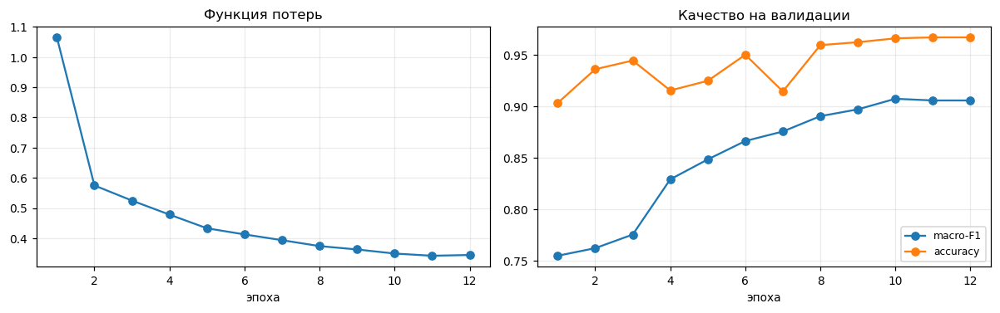

Тестовая выборка:
                               precision    recall  f1-score   support

                    No_damage      1.000     1.000     1.000       200
                        Crack      0.941     0.888     0.914       125
                         Void      0.545     0.720     0.621        25
                        Loose      0.973     0.957     0.965       300
Interlayer_bonding_deficiency      0.972     0.981     0.977       425

                     accuracy                          0.961      1075
                    macro avg      0.886     0.909     0.895      1075
                 weighted avg      0.964     0.961     0.962      1075



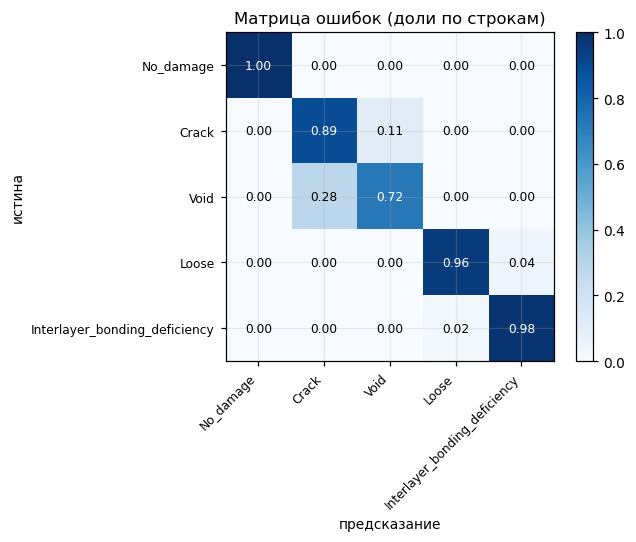

{'эксперимент': 'e5_tigpr_classification', 'test accuracy': 0.9609302325581396, 'test macro-F1': 0.8951113161383726}


In [66]:
if len(tig) and len(hist):
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    ax[0].plot(hist["эпоха"], hist["loss"], "o-"); ax[0].set_title("Функция потерь")
    ax[1].plot(hist["эпоха"], hist["val macro-F1"], "o-", label="macro-F1")
    ax[1].plot(hist["эпоха"], hist["val accuracy"], "o-", label="accuracy")
    ax[1].legend(fontsize=8); ax[1].set_title("Качество на валидации")
    for a in ax:
        a.set_xlabel("эпоха")
    plt.tight_layout(); plt.show()

    yt, pt = evaluate(dl_test)
    print("Тестовая выборка:")
    print(classification_report(yt, pt, target_names=TIGPR_CLASSES, digits=3, zero_division=0))

    cm = confusion_matrix(yt, pt, normalize="true")
    fig, ax = plt.subplots(figsize=(6.2, 5))
    im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(TIGPR_CLASSES))); ax.set_xticklabels(TIGPR_CLASSES, rotation=45, ha="right", fontsize=8)
    ax.set_yticks(range(len(TIGPR_CLASSES))); ax.set_yticklabels(TIGPR_CLASSES, fontsize=8)
    for i in range(len(TIGPR_CLASSES)):
        for j in range(len(TIGPR_CLASSES)):
            ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if cm[i, j] > 0.5 else "black")
    ax.set_xlabel("предсказание"); ax.set_ylabel("истина")
    ax.set_title("Матрица ошибок (доли по строкам)")
    plt.colorbar(im); plt.tight_layout(); plt.show()

    tigpr_result = {"эксперимент": "e5_tigpr_classification", "test accuracy": float((yt == pt).mean()),
                    "test macro-F1": float(f1_score(yt, pt, average="macro"))}
    print(tigpr_result)

**Как читать эти числа.** Accuracy около 0.96 для пяти классов на георадарограммах —
подозрительно хорошо, и к ней нужно относиться осторожно.

* Класс `No_damage` распознаётся без ошибок (F1 = 1.00). Такая идеальная
  разделимость скорее говорит об особенности данных: вероятно, кадры без дефектов
  вырезаны из отдельных однородных участков.
* Разбиение сделано блоками по 25 кадров внутри класса, но линии съёмки в наборе не
  указаны. Если один участок дал больше 25 кадров, его части могли попасть в разные
  выборки, и оценка, скорее всего, завышена.
* Надёжнее не абсолютное значение, а соотношение классов: трещины и разуплотнение
  различаются уверенно, пустоты — хуже всех (F1 ≈ 0.6 при 305 кадрах в классе).

---
## 11. Анализ результатов

### 11.1. Помогает ли предобучение на синтетике

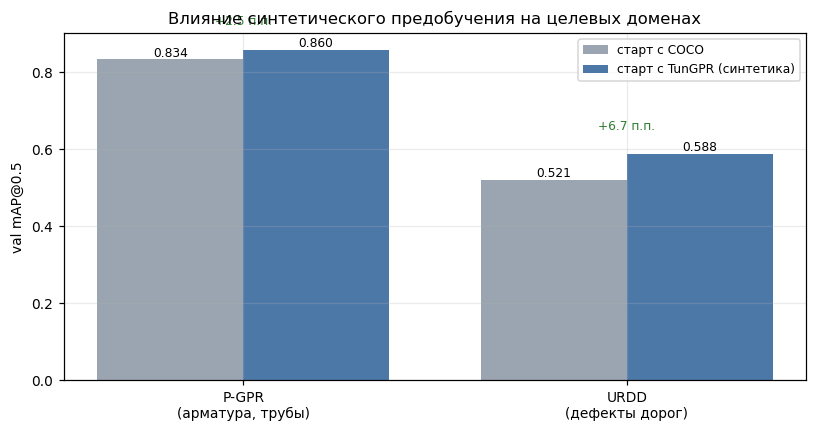

,домен,mAP@0.5 базовая,mAP@0.5 с синтетикой,"Δ, п.п.",test базовая,test с синтетикой,"Δ test, п.п."
0,"P-GPR (арматура, трубы)",0.834,0.860,2.517,0.564,0.581,1.688
1,URDD (дефекты дорог),0.521,0.588,6.730,0.428,0.360,-6.781


In [67]:
def pair_plot(pairs, title, metric="val mAP@0.5"):
    labels, base_v, tr_v = [], [], []
    for label, a, b in pairs:
        ra = next(r for r in RESULTS if r["эксперимент"] == a)
        rb = next(r for r in RESULTS if r["эксперимент"] == b)
        labels.append(label); base_v.append(ra[metric]); tr_v.append(rb[metric])
    x = np.arange(len(labels)); w = 0.38
    fig, ax = plt.subplots(figsize=(7.5, 4))
    ax.bar(x - w / 2, base_v, w, label="старт с COCO", color="#9AA5B1")
    ax.bar(x + w / 2, tr_v, w, label="старт с TunGPR (синтетика)", color="#4C78A8")
    for i, (a, b) in enumerate(zip(base_v, tr_v)):
        ax.text(i - w / 2, a, f"{a:.3f}", ha="center", va="bottom", fontsize=8)
        ax.text(i + w / 2, b, f"{b:.3f}", ha="center", va="bottom", fontsize=8)
        ax.annotate(f"{(b - a) * 100:+.1f} п.п.", (i, max(a, b)), textcoords="offset points",
                    xytext=(0, 16), ha="center", fontsize=8,
                    color="#2E7D32" if b > a else "#C62828")
    ax.set_xticks(x); ax.set_xticklabels(labels); ax.set_ylabel(metric)
    ax.set_title(title); ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()

pairs = [("P-GPR\n(арматура, трубы)", "e1a_concrete_coco", "e1b_concrete_tungpr"),
         ("URDD\n(дефекты дорог)", "e2a_road_coco", "e2b_road_tungpr")]
pair_plot(pairs, "Влияние синтетического предобучения на целевых доменах")

comparison = []
for label, a, b in pairs:
    ra = next(r for r in RESULTS if r["эксперимент"] == a)
    rb = next(r for r in RESULTS if r["эксперимент"] == b)
    row = {"домен": label.replace("\n", " "),
           "mAP@0.5 базовая": ra["val mAP@0.5"], "mAP@0.5 с синтетикой": rb["val mAP@0.5"],
           "Δ, п.п.": (rb["val mAP@0.5"] - ra["val mAP@0.5"]) * 100}
    if "test mAP@0.5" in ra:
        row.update({"test базовая": ra["test mAP@0.5"], "test с синтетикой": rb["test mAP@0.5"],
                    "Δ test, п.п.": (rb["test mAP@0.5"] - ra["test mAP@0.5"]) * 100})
    comparison.append(row)
display(pd.DataFrame(comparison).round(3))

На валидации предобучение на синтетике даёт выигрыш в обоих наборах. На тесте
картина другая: на железобетоне выигрыш сохраняется (+1.7 п.п.), на дорогах
меняется на проигрыш (−6.8 п.п.). Это первый признак того, что разница сравнима со
случайным шумом. Поэтому дальше считается бутстрэп-интервал (раздел 11.5), а не
сравниваются два числа.

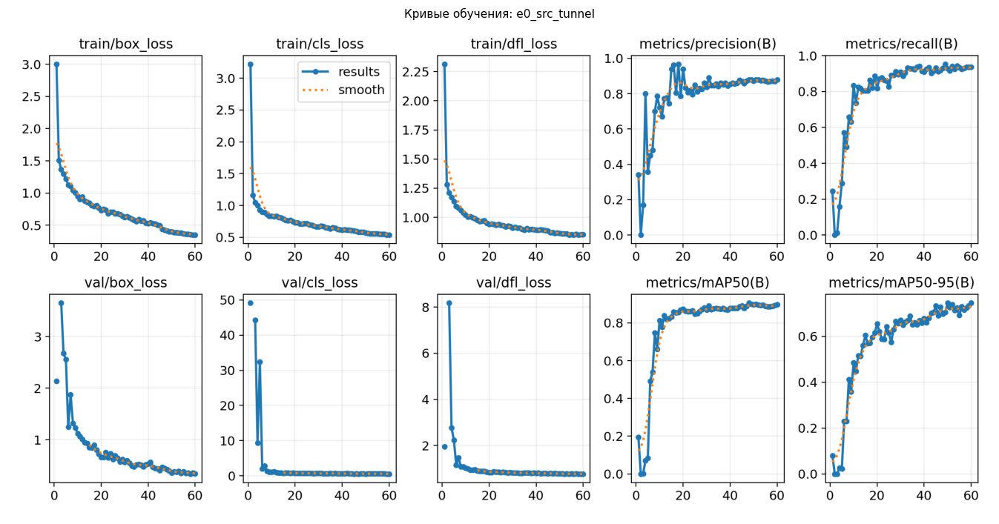

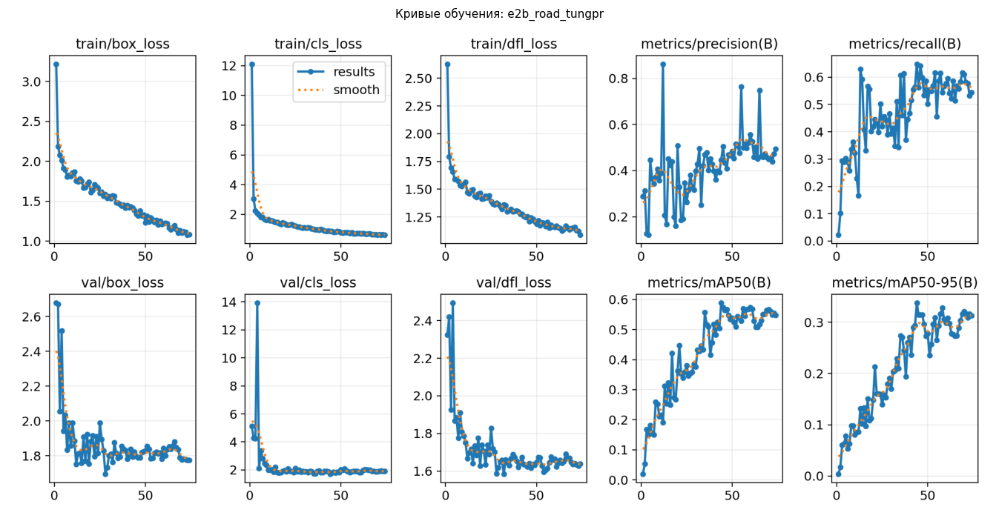

In [68]:
# Кривые обучения: ultralytics сохраняет их для каждого запуска
from PIL import Image as PILImage
for tag in ["e0_src_tunnel", "e2b_road_tungpr"]:
    png = RUNS / tag / "results.png"
    if png.exists():
        fig, ax = plt.subplots(figsize=(13, 6.5))
        ax.imshow(PILImage.open(png)); ax.axis("off")
        ax.set_title(f"Кривые обучения: {tag}", fontsize=10)
        plt.tight_layout(); plt.show()

### 11.2. Зависимость от объёма реальной разметки

,доля данных,COCO,TunGPR,"Δ, п.п."
0,0.25,0.214,0.270,5.588
1,0.50,0.217,0.291,7.422
2,1.00,0.601,0.621,2.079


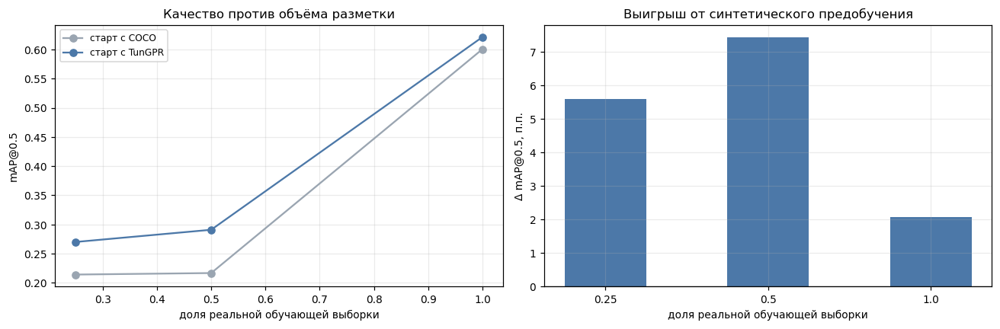

In [69]:
# все три точки посчитаны при одинаковом бюджете в 60 эпох, отличается только
# доля обучающей выборки
curve = []
for frac, tag_a, tag_b in [(0.25, "e3a_road_coco_25", "e3b_road_tungpr_25"),
                           (0.5, "e3a_road_coco_50", "e3b_road_tungpr_50"),
                           (1.0, "e3a_road_coco_100", "e3b_road_tungpr_100")]:
    ra = next((r for r in RESULTS if r["эксперимент"] == tag_a), None)
    rb = next((r for r in RESULTS if r["эксперимент"] == tag_b), None)
    if ra and rb:
        curve.append({"доля данных": frac, "COCO": ra["val mAP@0.5"], "TunGPR": rb["val mAP@0.5"],
                      "Δ, п.п.": (rb["val mAP@0.5"] - ra["val mAP@0.5"]) * 100})
curve = pd.DataFrame(curve)
display(curve.round(3))

if len(curve):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(curve["доля данных"], curve["COCO"], "o-", label="старт с COCO", color="#9AA5B1")
    axes[0].plot(curve["доля данных"], curve["TunGPR"], "o-", label="старт с TunGPR", color="#4C78A8")
    axes[0].set_xlabel("доля реальной обучающей выборки"); axes[0].set_ylabel("mAP@0.5")
    axes[0].set_title("Качество против объёма разметки"); axes[0].legend(fontsize=8)
    axes[1].bar(curve["доля данных"].astype(str), curve["Δ, п.п."], color="#4C78A8", width=0.5)
    axes[1].axhline(0, color="black", lw=0.8)
    axes[1].set_xlabel("доля реальной обучающей выборки"); axes[1].set_ylabel("Δ mAP@0.5, п.п.")
    axes[1].set_title("Выигрыш от синтетического предобучения")
    plt.tight_layout(); plt.show()

На валидации синтетика впереди при любом объёме данных, и больше всего — при 25–50%
разметки (+5.6 и +7.4 п.п.), как и предсказывает гипотеза. Но при такой малой
разметке качество обеих моделей низкое (0.21–0.29), а при переходе к 100% оно
резко растёт до 0.60: насыщения не видно, и модели явно не хватает данных. Кроме
того, это одно разбиение, поэтому выигрыш ещё нужно проверить (раздел 11.14).

### 11.3. Качество по классам

Среднее значение скрывает главное: какие дефекты модель находит, а какие нет.

In [70]:
for tag, classes in [("e1b_concrete_tungpr", CONCRETE_CLASSES), ("e2b_road_tungpr", ROAD_CLASSES)]:
    r = next((x for x in RESULTS if x["эксперимент"] == tag), None)
    if r is None:
        continue
    res = r.get("_test_result") or r["_model"].val(data=r["_data"], split="val",
                                                   verbose=False, plots=False, device=DEVICE)
    print(f"\n{tag}:")
    display(metrics_table(res, classes))


e1b_concrete_tungpr:


,класс,precision,recall,mAP@0.5,mAP@0.5:0.95,F2,оговорка
0,steel,0.854,0.795,0.849,0.459,0.806,
1,pipe,0.429,0.472,0.313,0.122,0.463,
2,macro,0.641,0.633,0.581,0.291,0.634,



e2b_road_tungpr:


,класс,precision,recall,mAP@0.5,mAP@0.5:0.95,F2,оговорка
0,Cavity,0.161,0.250,0.164,0.100,0.225,
1,Detachment,0.420,0.622,0.498,0.239,0.567,
2,Looseness,0.372,0.571,0.418,0.133,0.516,
3,Water-rich,NaN,NaN,NaN,NaN,NaN,
4,macro,0.317,0.481,0.360,0.157,0.436,


На железобетоне арматура находится хорошо (mAP@0.5 = 0.85), трубы — гораздо хуже
(0.31). На дорогах лучше всего находится отслоение (`Detachment`), хуже всего —
пустоты (`Cavity`).

### 11.4. По классам: базовая модель против модели с синтетикой

Те же пары запусков, но по отдельным классам: видно, где синтетика помогает, а где
мешает.

Две оговорки к таблице. Первая: `precision` и `recall` в ней `ultralytics` берёт в
одной точке — при пороге, где максимален F1, усреднённый по всем классам. Поэтому у
редкого класса может быть `recall = 0` при ненулевой AP; такие строки помечены в
столбце «оговорка». Вторая: AP здесь посчитаны через `val()`, а он работает не так,
как развёрнутая система (подробно — в разделе 11.13).

In [71]:
def class_table(tag, data_yaml, classes, split="test"):
    r = next((x for x in RESULTS if x["эксперимент"] == tag), None)
    if r is None:
        return None
    with quiet():
        res = r["_model"].val(data=str(data_yaml), split=split, verbose=False,
                              plots=False, device=DEVICE)
    t = metrics_table(res, classes)
    t.insert(0, "запуск", tag)
    return t

pairs_cls = [("e2a_road_coco", "e2b_road_tungpr", urdd_yaml, ROAD_CLASSES, "URDD, 80 эпох"),
             ("e3a_road_coco_100", "e3b_road_tungpr_100", urdd_yaml, ROAD_CLASSES, "URDD, 60 эпох"),
             ("e1a_concrete_coco", "e1b_concrete_tungpr", pgpr_yaml, CONCRETE_CLASSES, "P-GPR")]
for a, b, y, cls, label in pairs_cls:
    ta, tb = class_table(a, y, cls), class_table(b, y, cls)
    if ta is None or tb is None:
        continue
    merged = ta.merge(tb, on="класс", suffixes=(" базовая", " синтетика"))
    merged["Δ mAP@0.5, п.п."] = (merged["mAP@0.5 синтетика"] - merged["mAP@0.5 базовая"]) * 100
    print(f"\n{label}:")
    display(merged[["класс", "mAP@0.5 базовая", "mAP@0.5 синтетика", "Δ mAP@0.5, п.п.",
                    "recall базовая", "recall синтетика"]].round(3))

Ultralytics 8.4.154 🚀 Python-3.11.5 torch-2.7.0.dev20250114+cu126 CUDA:0 (NVIDIA GeForce RTX 3090, 24253MiB)
YOLO11s summary (fused): 100 layers, 9,414,348 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 6103.7±336.8 MB/s, size: 232.4 KB)
                   all         57         73      0.544       0.48      0.428      0.175
Speed: 0.3ms preprocess, 1.5ms inference, 0.0ms loss, 0.4ms postprocess per image
Ultralytics 8.4.154 🚀 Python-3.11.5 torch-2.7.0.dev20250114+cu126 CUDA:0 (NVIDIA GeForce RTX 3090, 24253MiB)
YOLO11s summary (fused): 100 layers, 9,414,348 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5868.7±572.7 MB/s, size: 234.3 KB)
                   all         57         73      0.317      0.481       0.36      0.157
Speed: 0.2ms preprocess, 1.6ms inference, 0.0ms loss, 0.3ms postprocess per image

URDD, 80 эпох:


,класс,mAP@0.5 базовая,mAP@0.5 синтетика,"Δ mAP@0.5, п.п.",recall базовая,recall синтетика
0,Cavity,0.279,0.164,-11.5,0.312,0.250
1,Detachment,0.577,0.498,-7.9,0.698,0.622
2,Looseness,0.428,0.418,-1.0,0.429,0.571
3,Water-rich,NaN,NaN,NaN,NaN,NaN
4,macro,0.428,0.360,-6.8,0.480,0.481


Ultralytics 8.4.154 🚀 Python-3.11.5 torch-2.7.0.dev20250114+cu126 CUDA:0 (NVIDIA GeForce RTX 3090, 24253MiB)
YOLO11s summary (fused): 100 layers, 9,414,348 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5883.0±750.7 MB/s, size: 218.9 KB)
                   all         57         73      0.394      0.506      0.485      0.208
Speed: 0.2ms preprocess, 1.6ms inference, 0.0ms loss, 0.3ms postprocess per image
Ultralytics 8.4.154 🚀 Python-3.11.5 torch-2.7.0.dev20250114+cu126 CUDA:0 (NVIDIA GeForce RTX 3090, 24253MiB)
YOLO11s summary (fused): 100 layers, 9,414,348 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5615.2±668.6 MB/s, size: 237.2 KB)
                   all         57         73      0.397      0.405      0.417      0.185
Speed: 0.2ms preprocess, 1.6ms inference, 0.0ms loss, 0.3ms postprocess per image

URDD, 60 эпох:


,класс,mAP@0.5 базовая,mAP@0.5 синтетика,"Δ mAP@0.5, п.п.",recall базовая,recall синтетика
0,Cavity,0.320,0.201,-11.9,0.250,0.062
1,Detachment,0.543,0.568,2.5,0.698,0.581
2,Looseness,0.591,0.481,-11.0,0.571,0.571
3,Water-rich,NaN,NaN,NaN,NaN,NaN
4,macro,0.485,0.417,-6.8,0.506,0.405


Ultralytics 8.4.154 🚀 Python-3.11.5 torch-2.7.0.dev20250114+cu126 CUDA:0 (NVIDIA GeForce RTX 3090, 24253MiB)
YOLO11s summary (fused): 100 layers, 9,413,574 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2811.7±1404.3 MB/s, size: 49.3 KB)
                   all         31        183       0.63      0.613      0.564      0.255
Speed: 0.3ms preprocess, 1.6ms inference, 0.0ms loss, 0.4ms postprocess per image
Ultralytics 8.4.154 🚀 Python-3.11.5 torch-2.7.0.dev20250114+cu126 CUDA:0 (NVIDIA GeForce RTX 3090, 24253MiB)
YOLO11s summary (fused): 100 layers, 9,413,574 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2769.0±785.4 MB/s, size: 33.1 KB)
                   all         31        183      0.641      0.633      0.581      0.291
Speed: 0.2ms preprocess, 1.6ms inference, 0.0ms loss, 0.4ms postprocess per image

P-GPR:


,класс,mAP@0.5 базовая,mAP@0.5 синтетика,"Δ mAP@0.5, п.п.",recall базовая,recall синтетика
0,steel,0.822,0.849,2.7,0.782,0.795
1,pipe,0.307,0.313,0.6,0.444,0.472
2,macro,0.564,0.581,1.7,0.613,0.633


**Что видно.** Устойчиво повторяется одно: по пустотам (`Cavity`) синтетика отнимает
около 12 п.п. в обеих дорожных парах (−11.5 и −11.9). По `Detachment` и `Looseness`
знак разницы меняется от пары к паре (−7.9 и +2.5 для отслоения, −1.0 и −11.0 для
разуплотнения), то есть по ним устойчивого эффекта нет.

При этом две пары обучены на **одном и том же** разбиении и отличаются только числом
эпох, поэтому независимыми подтверждениями они не являются. Проверить эффект можно
только на других разбиениях — это сделано в разделе 11.14.

Возможное объяснение для пустот: в TunGPR пустота — небольшой контрастный объект в
бетоне при 800 МГц, а в URDD — длинная слабоконтрастная зона под дорожным покрытием
при 200 МГц. Модель переносит неверное представление о форме и размере пустоты. Это
объяснение проверяется в эксперименте E8 с синтетикой под 200 МГц (раздел 11.12).

### 11.5. Значима ли разница

Здесь легко ошибиться: построить два отдельных доверительных интервала и посмотреть,
пересекаются ли они. Так делать нельзя. Обе модели оцениваются на **одних и тех же
кадрах**, и их ошибки связаны. Правильно строить доверительный интервал для самой
разницы, пересчитывая обе модели на одной и той же случайной выборке кадров (парный
бутстрэп).

Ниже приведено и то, и другое: отдельные интервалы — для описания, интервал
разницы — для вывода.

In [72]:
ci_rows, rap_rows, preds_cache = [], [], {}
for tag, data_yaml, classes in [("e2a_road_coco", urdd_yaml, ROAD_CLASSES),
                                ("e2b_road_tungpr", urdd_yaml, ROAD_CLASSES),
                                ("e1b_concrete_tungpr", pgpr_yaml, CONCRETE_CLASSES)]:
    r = next((x for x in RESULTS if x["эксперимент"] == tag), None)
    if r is None:
        continue
    fr = collect_predictions(r["_model"], data_yaml, split="test")
    preds_cache[tag] = (fr, classes)
    if data_yaml == urdd_yaml:
        mean, lo, hi = bootstrap_ci(fr, n_classes=len(classes), n_boot=200)
        ci_rows.append({"конфигурация": tag, "mAP@0.5 (bootstrap)": mean,
                        "95% ДИ снизу": lo, "95% ДИ сверху": hi, "тестовых кадров": len(fr)})
ci = pd.DataFrame(ci_rows)
display(ci.round(3))

# парный бутстрэп разницы: обе модели на одной и той же перевыборке кадров
if "e2a_road_coco" in preds_cache and "e2b_road_tungpr" in preds_cache:
    fa = preds_cache["e2a_road_coco"][0]
    fb = preds_cache["e2b_road_tungpr"][0]
    assert [f["image"] for f in fa] == [f["image"] for f in fb], "кадры должны совпадать"
    obs, lo, hi, frac = paired_bootstrap(fa, fb, n_classes=len(ROAD_CLASSES), n_boot=500)
    print(f"\nпарный бутстрэп, синтетика минус базовая (macro AP@0.5):")
    print(f"  наблюдаемая разница {obs*100:+.1f} п.п.")
    print(f"  95% ДИ разницы [{lo*100:+.1f}; {hi*100:+.1f}] п.п.")
    print(f"  доля перевыборок, где синтетика лучше: {frac:.2f}")
    print("  вывод:", "разница значима" if lo > 0 or hi < 0 else
          "разница статистически неразличима — интервал накрывает ноль")

,конфигурация,mAP@0.5 (bootstrap),95% ДИ снизу,95% ДИ сверху,тестовых кадров
0,e2a_road_coco,0.407,0.281,0.556,57
1,e2b_road_tungpr,0.323,0.222,0.434,57



парный бутстрэп, синтетика минус базовая (macro AP@0.5):
  наблюдаемая разница -8.0 п.п.
  95% ДИ разницы [-21.5; +1.1] п.п.
  доля перевыборок, где синтетика лучше: 0.04
  вывод: разница статистически неразличима — интервал накрывает ноль


**Результат.** Наблюдаемая разница −8.0 п.п. в пользу базовой модели, но 95%
интервал разницы [−21.5; +1.1] п.п. включает ноль, то есть различие статистически
не подтверждено.

Замечание: mAP@0.5 из бутстрэпа не совпадает с числом из `ultralytics`. Библиотека
считает метрику по всему набору со своими порогами, а здесь используется собственное
сопоставление рамок (conf ≥ 0.001, IoU NMS = 0.6). Поэтому сравнивать можно только
значения, посчитанные одним и тем же способом.

### 11.6. Практическая метрика: recall при точности не ниже 0.5

Для службы диагностики важен конкретный вопрос: какую долю дефектов модель найдёт,
если на каждое верное срабатывание допускается одна ложная тревога. Это recall в той
точке PR-кривой, где precision = 0.5.

Две оговорки:

1. Каждое число относится к **конкретной модели на конкретном наборе**: дорожные
   классы (`Cavity`, `Detachment`, `Looseness`) — к URDD, `steel` и `pipe` — к
   P-GPR. Объединять их в один список нельзя.
2. Здесь порог подбирается **по той же тестовой кривой**, на которой считается
   recall. Это оценка сверху. Честный способ — выбрать порог на валидации и один раз
   применить его к тесту; это сделано ниже.

In [73]:
for tag, (fr, classes) in preds_cache.items():
    rap = recall_at_precision(fr, n_classes=len(classes), target_precision=0.5)
    support = Counter(g[0] for f in fr for g in f["gt"])
    rows = [{"класс": classes[c], "объектов в test": support.get(c, 0),
             "recall при precision ≥ 0.5": v[0],
             "порог (подобран на test)": v[1]} for c, v in rap.items()]
    print(f"\n{tag}: {len(fr)} кадров")
    display(pd.DataFrame(rows).round(3))


e2a_road_coco: 57 кадров


,класс,объектов в test,recall при precision ≥ 0.5,порог (подобран на test)
0,Cavity,16,0.125,0.755
1,Detachment,43,0.651,0.350
2,Looseness,14,0.500,0.249
3,Water-rich,0,NaN,NaN



e2b_road_tungpr: 57 кадров


,класс,объектов в test,recall при precision ≥ 0.5,порог (подобран на test)
0,Cavity,16,0.000,NaN
1,Detachment,43,0.674,0.148
2,Looseness,14,0.286,0.576
3,Water-rich,0,NaN,NaN



e1b_concrete_tungpr: 31 кадров


,класс,объектов в test,recall при precision ≥ 0.5,порог (подобран на test)
0,steel,147,0.878,0.041
1,pipe,36,0.500,0.473


Теперь порог выбирается на валидации и один раз применяется к тесту. Разница между
двумя таблицами показывает, насколько подгонка порога под тест завышает результат.

In [74]:
honest_rows = []
for tag, data_yaml, classes in [("e2a_road_coco", urdd_yaml, ROAD_CLASSES),
                                ("e2b_road_tungpr", urdd_yaml, ROAD_CLASSES),
                                ("e1b_concrete_tungpr", pgpr_yaml, CONCRETE_CLASSES)]:
    if tag not in preds_cache:
        continue
    r = next(x for x in RESULTS if x["эксперимент"] == tag)
    fr_val = collect_predictions(r["_model"], data_yaml, split="val")
    thr = {c: v[1] for c, v in
           recall_at_precision(fr_val, n_classes=len(classes), target_precision=0.5).items()}
    got = pr_at_threshold(preds_cache[tag][0], n_classes=len(classes), thresholds=thr)
    for c, (pr, rc, n) in got.items():
        if n:
            honest_rows.append({"модель": tag, "класс": classes[c], "объектов в test": n,
                                "порог с валидации": thr.get(c, np.nan),
                                "precision на test": pr, "recall на test": rc})
honest = pd.DataFrame(honest_rows)
display(honest.round(3))
print("если precision на test заметно ниже 0.5 — порог, выбранный на валидации, "
      "на тесте не держится, и заявленный recall недостижим")

,модель,класс,объектов в test,порог с валидации,precision на test,recall на test
0,e2a_road_coco,Cavity,16,0.499,0.400,0.125
1,e2a_road_coco,Detachment,43,0.381,0.529,0.628
2,e2a_road_coco,Looseness,14,0.240,0.500,0.500
3,e2b_road_tungpr,Cavity,16,NaN,NaN,0.000
4,e2b_road_tungpr,Detachment,43,0.175,0.509,0.628
5,e2b_road_tungpr,Looseness,14,0.120,0.241,0.500
6,e1b_concrete_tungpr,steel,147,0.030,0.603,0.878
7,e1b_concrete_tungpr,pipe,36,0.149,0.247,0.556


если precision на test заметно ниже 0.5 — порог, выбранный на валидации, на тесте не держится, и заявленный recall недостижим


Для большинства классов порог с валидации держится и на тесте. Исключения — трубы
(`pipe`) и разуплотнение у модели с синтетикой: precision на тесте падает до 0.25,
то есть заявленная точность 0.5 для них не достигается. Пустоты базовая модель
находит в 2 случаях из 16, модель с синтетикой — ни в одном.

### 11.7. Чего стоят физически некорректные аугментации

Тот же запуск с `flipud`, `mixup` и поворотами против политики из раздела 8.2.
Смотреть нужно сразу на валидацию и тест.

In [75]:
aug_rows = []
for tag, label in [("e2b_road_tungpr", "физически обоснованная политика"),
                   ("e4_road_naive_aug", "наивная (flipud, mixup, повороты)")]:
    r = next((x for x in RESULTS if x["эксперимент"] == tag), None)
    if r:
        aug_rows.append({"политика аугментаций": label, "val mAP@0.5": r["val mAP@0.5"],
                         "val mAP@0.5:0.95": r["val mAP@0.5:0.95"],
                         "test mAP@0.5": r.get("test mAP@0.5", np.nan)})
aug_df = pd.DataFrame(aug_rows)
display(aug_df.round(3))
if len(aug_df) == 2:
    d_val = (aug_df.iloc[0]["val mAP@0.5"] - aug_df.iloc[1]["val mAP@0.5"]) * 100
    d_test = (aug_df.iloc[0]["test mAP@0.5"] - aug_df.iloc[1]["test mAP@0.5"]) * 100
    print(f"на валидации разница в пользу физически обоснованной политики: {d_val:+.1f} п.п.")
    print(f"на тесте та же разница: {d_test:+.1f} п.п.")
    if d_val * d_test < 0:
        print("знак разницы на валидации и на тесте противоположен — на одном разбиении "
              "вопрос не решается, и физическое обоснование политики остаётся доводом "
              "от постановки задачи, а не измеренным фактом")

,политика аугментаций,val mAP@0.5,val mAP@0.5:0.95,test mAP@0.5
0,физически обоснованная политика,0.588,0.337,0.360
1,"наивная (flipud, mixup, повороты)",0.487,0.250,0.556


на валидации разница в пользу физически обоснованной политики: +10.1 п.п.
на тесте та же разница: -19.6 п.п.
знак разницы на валидации и на тесте противоположен — на одном разбиении вопрос не решается, и физическое обоснование политики остаётся доводом от постановки задачи, а не измеренным фактом


**Результат E4.** На валидации физически обоснованная политика лучше на 10.1 п.п.,
а на тесте — хуже на 19.6 п.п. Знак разницы противоположный, поэтому на одном
разбиении вопрос не решается. Выбор аугментаций в работе обоснован физикой сигнала,
а экспериментально он не подтверждён и не опровергнут.

### 11.8. Разбор ошибок: что модель путает

URDD: реальные дорожные дефекты


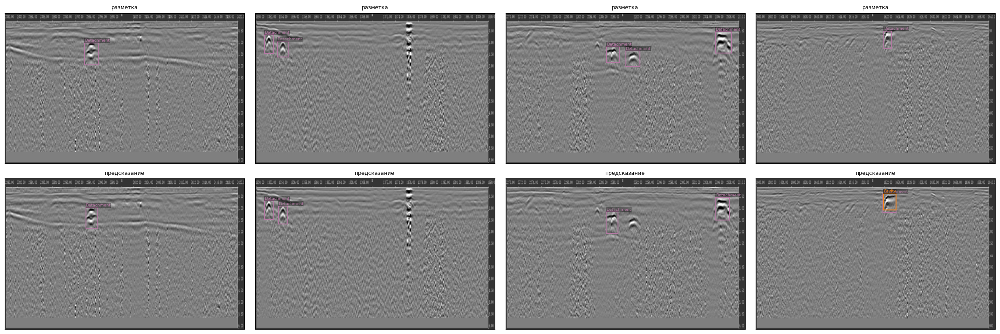

P-GPR: арматура и трубы


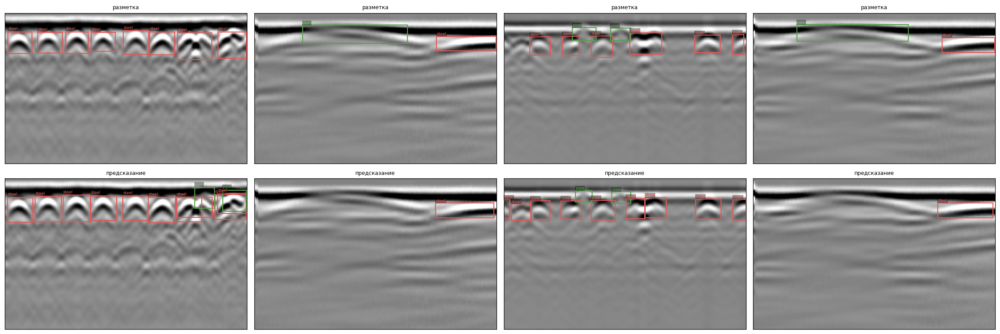

In [76]:
def show_predictions(model, data_yaml, class_names, split="test", n=4, conf=0.25):
    cfg = yaml.safe_load(open(data_yaml))
    root = Path(cfg["path"])
    img_dir = root / cfg.get(split, f"images/{split}")
    lbl_dir = root / "labels" / split
    paths = sorted(img_dir.glob("*.jpg"))
    if not paths:
        return
    rng = np.random.default_rng(SEED)
    pick = rng.choice(paths, min(n, len(paths)), replace=False)
    im_sz = int(getattr(model, "overrides", {}).get("imgsz", 640) or 640)
    res = model.predict([str(p) for p in pick], conf=conf, imgsz=im_sz, verbose=False, device=DEVICE)
    fig, axes = plt.subplots(2, len(pick), figsize=(5.2 * len(pick), 7))
    for j, (p, r) in enumerate(zip(pick, res)):
        gt = []
        lp = lbl_dir / f"{p.stem}.txt"
        if lp.exists():
            for line in open(lp):
                v = line.split()
                gt.append(dict(cls=class_names[int(float(v[0]))], xc=float(v[1]), yc=float(v[2]),
                               w=float(v[3]), h=float(v[4])))
        draw_frame(axes[0, j], str(p), pd.DataFrame(gt) if gt else pd.DataFrame(columns=["cls","xc","yc","w","h"]),
                   title="разметка")
        pr = []
        if r.boxes is not None and len(r.boxes):
            for b, c, s in zip(r.boxes.xywhn.cpu().numpy(), r.boxes.cls.cpu().numpy().astype(int),
                               r.boxes.conf.cpu().numpy()):
                pr.append(dict(cls=f"{class_names[c]} {s:.2f}".split()[0], xc=b[0], yc=b[1], w=b[2], h=b[3]))
        draw_frame(axes[1, j], str(p), pd.DataFrame(pr) if pr else pd.DataFrame(columns=["cls","xc","yc","w","h"]),
                   title="предсказание")
    plt.tight_layout(); plt.show()

r = next((x for x in RESULTS if x["эксперимент"] == "e2b_road_tungpr"), None)
if r:
    print("URDD: реальные дорожные дефекты")
    show_predictions(r["_model"], urdd_yaml, ROAD_CLASSES)

r = next((x for x in RESULTS if x["эксперимент"] == "e1b_concrete_tungpr"), None)
if r:
    print("P-GPR: арматура и трубы")
    show_predictions(r["_model"], pgpr_yaml, CONCRETE_CLASSES)

### 11.9. Перенос на реальные тоннельные записи

Качественная проверка: модель, обученная только на синтетике TunGPR, применяется к
реальным записям тоннельной обделки — окнам из профилей Guangzhou (три тоннеля:
свод, стены, низ), окнам облицовки канала USBR и разрезам сборной обделки composite
lining.

Разметки для этих кадров нет, поэтому пропуски посчитать нельзя: неизвестно, есть ли
на выбранных шести кадрах дефекты вообще. Порог уверенности один (0.2) и выбран
произвольно. Значит, это **иллюстрация**, а не измерение: по ней видно лишь, выдаёт
ли модель осмысленные объекты на чужих данных.

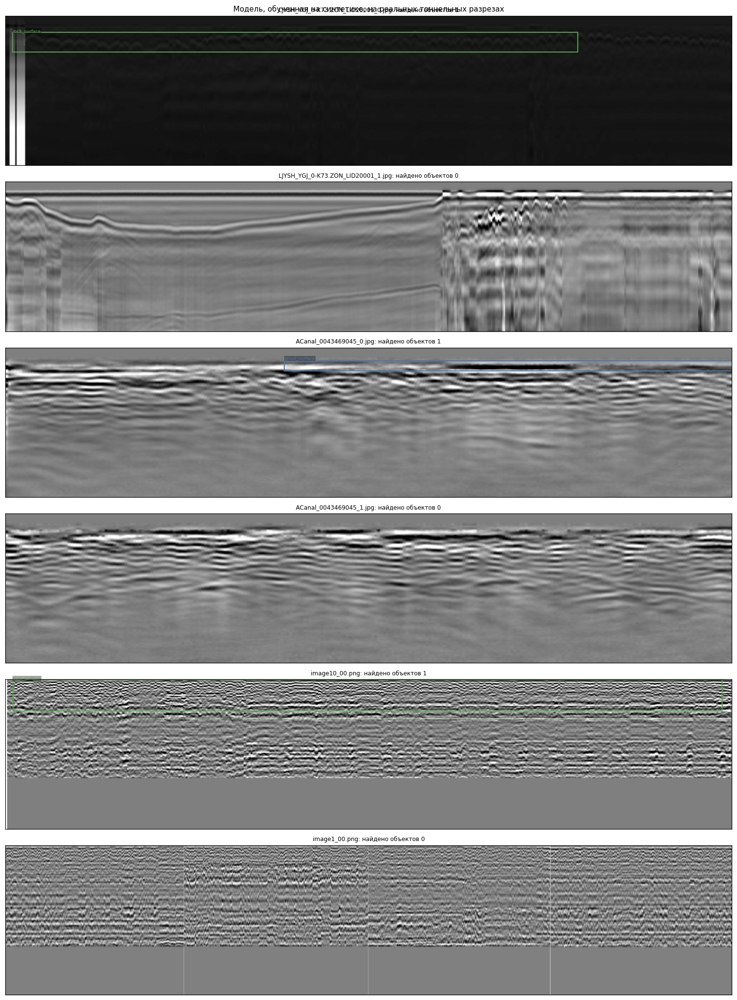

что модель нашла на реальных тоннельных кадрах: {'rock_surface': 2, 'grout_surface': 1}


In [77]:
real_tunnel = (frames[frames.dataset == "guangzhou_tunnel"]["image"].tolist()[:2]
               + frames[frames.dataset == "usbr_lining"]["image"].tolist()[:2]
               + frames[frames.dataset == "composite_lining"]["image"].tolist()[:2])
if real_tunnel:
    model0 = YOLO(e0["_weights"])
    pick = real_tunnel[:6]
    res = model0.predict(pick, conf=0.2, imgsz=640, verbose=False, device=DEVICE)
    fig, axes = plt.subplots(len(pick), 1, figsize=(14, 3.2 * len(pick)))
    for ax, p, r in zip(np.atleast_1d(axes), pick, res):
        pr = []
        if r.boxes is not None and len(r.boxes):
            for b, c, s in zip(r.boxes.xywhn.cpu().numpy(), r.boxes.cls.cpu().numpy().astype(int),
                               r.boxes.conf.cpu().numpy()):
                pr.append(dict(cls=TUNNEL_CLASSES[c], xc=b[0], yc=b[1], w=b[2], h=b[3]))
        draw_frame(ax, p, pd.DataFrame(pr) if pr else pd.DataFrame(columns=["cls","xc","yc","w","h"]),
                   title=f"{Path(p).name}: найдено объектов {len(pr)}", max_side=1400)
    plt.suptitle("Модель, обученная на синтетике, на реальных тоннельных разрезах", fontsize=10)
    plt.tight_layout(); plt.show()
    det = Counter()
    for r in res:
        if r.boxes is not None:
            for c in r.boxes.cls.cpu().numpy().astype(int):
                det[TUNNEL_CLASSES[c]] += 1
    print("что модель нашла на реальных тоннельных кадрах:", dict(det))

На шести реальных кадрах модель нашла всего три объекта, и все это границы
материалов (`rock_surface` — 2, `grout_surface` — 1). Ни одного дефекта. Признаков
того, что модель, обученная только на синтетике, переносится на реальные тоннели,
не видно.

### 11.10. Дополнительные каналы сигнала

Условия полностью одинаковые: те же данные и разбиение, 60 эпох, разрешение 960.
Меняется только вход — градации серого против трёх каналов «амплитуда, огибающая,
косинус фазы».

In [78]:
attr_rows = []
for tag, label in [("e3a_road_coco_100", "амплитуда (градации серого)"),
                   ("e6_road_attr", "амплитуда + огибающая + фаза")]:
    r = next((x for x in RESULTS if x["эксперимент"] == tag), None)
    if r:
        attr_rows.append({"вход": label, "val mAP@0.5": r["val mAP@0.5"],
                          "val mAP@0.5:0.95": r["val mAP@0.5:0.95"],
                          "test mAP@0.5": r.get("test mAP@0.5", np.nan)})
if len(attr_rows) == 2:
    attr_df = pd.DataFrame(attr_rows)
    display(attr_df.round(3))
    d = (attr_df.iloc[1]["val mAP@0.5"] - attr_df.iloc[0]["val mAP@0.5"]) * 100
    print(f"вклад атрибутных каналов: {d:+.1f} п.п. val mAP@0.5")
    t6 = class_table("e6_road_attr", road_attr_yaml, ROAD_CLASSES)
    t0_ = class_table("e3a_road_coco_100", urdd_yaml, ROAD_CLASSES)
    if t6 is not None and t0_ is not None:
        m = t0_.merge(t6, on="класс", suffixes=(" амплитуда", " атрибуты"))
        m["Δ, п.п."] = (m["mAP@0.5 атрибуты"] - m["mAP@0.5 амплитуда"]) * 100
        display(m[["класс", "mAP@0.5 амплитуда", "mAP@0.5 атрибуты", "Δ, п.п."]].round(3))

,вход,val mAP@0.5,val mAP@0.5:0.95,test mAP@0.5
0,амплитуда (градации серого),0.601,0.341,0.485
1,амплитуда + огибающая + фаза,0.574,0.329,0.352


вклад атрибутных каналов: -2.6 п.п. val mAP@0.5
Ultralytics 8.4.154 🚀 Python-3.11.5 torch-2.7.0.dev20250114+cu126 CUDA:0 (NVIDIA GeForce RTX 3090, 24253MiB)
YOLO11s summary (fused): 100 layers, 9,414,348 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 7672.7±1018.5 MB/s, size: 519.9 KB)
                   all         57         73      0.523      0.279      0.352      0.178
Speed: 0.2ms preprocess, 1.6ms inference, 0.0ms loss, 0.3ms postprocess per image
Ultralytics 8.4.154 🚀 Python-3.11.5 torch-2.7.0.dev20250114+cu126 CUDA:0 (NVIDIA GeForce RTX 3090, 24253MiB)
YOLO11s summary (fused): 100 layers, 9,414,348 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5345.4±1343.1 MB/s, size: 239.5 KB)
                   all         57         73      0.394      0.506      0.485      0.208
Speed: 0.2ms preprocess, 1.6ms inference, 0.0ms loss, 0.4ms postprocess per image


,класс,mAP@0.5 амплитуда,mAP@0.5 атрибуты,"Δ, п.п."
0,Cavity,0.320,0.156,-16.4
1,Detachment,0.543,0.448,-9.5
2,Looseness,0.591,0.453,-13.8
3,Water-rich,NaN,NaN,NaN
4,macro,0.485,0.352,-13.3


Дополнительные каналы **ухудшили** результат: −2.6 п.п. на валидации и −13.3 п.п. на
тесте (0.352 против 0.485), хуже по всем трём классам. Вероятная причина: у URDD
есть только готовые картинки, и атрибуты считаются по восстановленной из картинки
амплитуде, а не по исходному сигналу.

### 11.11. TTA и ансамбль двух моделей

Две модели ошибаются по-разному: со стартом с COCO лучше находит пустоты, со стартом
с синтетики — в среднем по классам. Их предсказания объединяются методом WBF
(weighted boxes fusion): близкие рамки одного класса сливаются в одну с усреднёнными
координатами.

Что именно делает TTA: флаг `augment=True` в `ultralytics` — это прогон на трёх
масштабах `[1, 0.83, 0.67]` с горизонтальным отражением на одном из них.
Вертикального отражения нет, что согласуется с физикой. Вклад масштаба и отражения
отдельно не измерялся, поэтому ниже пишется просто «TTA».

In [79]:
def wbf(frames_a, frames_b, iou_thr=0.55):
    """Weighted Box Fusion двух наборов покадровых предсказаний."""
    out = []
    for fa, fb in zip(frames_a, frames_b):
        preds = sorted(fa["pred"] + fb["pred"], key=lambda p: -p[5])
        clusters = []
        for p in preds:
            hit = None
            for cl in clusters:
                if cl["cls"] == p[0] and iou_xywh(cl["box"], p[1:5]) >= iou_thr:
                    hit = cl; break
            if hit is None:
                clusters.append({"cls": p[0], "box": list(p[1:5]), "scores": [p[5]],
                                 "boxes": [list(p[1:5])]})
            else:
                hit["scores"].append(p[5]); hit["boxes"].append(list(p[1:5]))
                w = np.array(hit["scores"])
                hit["box"] = list(np.average(np.array(hit["boxes"]), axis=0, weights=w))
        fused = []
        for cl in clusters:
            score = float(np.mean(cl["scores"]) * min(len(cl["scores"]), 2) / 2)
            fused.append([cl["cls"], *cl["box"], score])
        out.append({"image": fa["image"], "gt": fa["gt"], "pred": fused})
    return out


ens_rows = []
fr_a = preds_cache.get("e2a_road_coco", (None, None))[0]
fr_b = preds_cache.get("e2b_road_tungpr", (None, None))[0]
if fr_a and fr_b:
    for name, fr in [("старт с COCO", fr_a), ("старт с TunGPR", fr_b),
                     ("ансамбль WBF", wbf(fr_a, fr_b))]:
        aps, _ = ap_from_frames(fr, n_classes=len(ROAD_CLASSES))
        row = {"конфигурация": name, "macro mAP@0.5": float(np.nanmean(list(aps.values())))}
        for ci, cname in enumerate(ROAD_CLASSES):
            row[cname] = aps.get(ci, np.nan)
        ens_rows.append(row)
    display(pd.DataFrame(ens_rows).round(3))

# TTA средствами ultralytics: те же модели, предсказание с горизонтальным отражением
tta_rows = []
for tag in ["e2a_road_coco", "e2b_road_tungpr"]:
    r = next((x for x in RESULTS if x["эксперимент"] == tag), None)
    if r is None:
        continue
    with quiet():
        plain = r["_model"].val(data=urdd_yaml, split="test", verbose=False, plots=False,
                                device=DEVICE)
        aug = r["_model"].val(data=urdd_yaml, split="test", augment=True, verbose=False,
                              plots=False, device=DEVICE)
    tta_rows.append({"запуск": tag, "без TTA": float(plain.box.map50),
                     "с TTA": float(aug.box.map50),
                     "Δ, п.п.": (float(aug.box.map50) - float(plain.box.map50)) * 100})
if tta_rows:
    display(pd.DataFrame(tta_rows).round(3))

,конфигурация,macro mAP@0.5,Cavity,Detachment,Looseness,Water-rich
0,старт с COCO,0.386,0.254,0.523,0.382,NaN
1,старт с TunGPR,0.306,0.073,0.485,0.359,NaN
2,ансамбль WBF,0.353,0.176,0.513,0.371,NaN


Ultralytics 8.4.154 🚀 Python-3.11.5 torch-2.7.0.dev20250114+cu126 CUDA:0 (NVIDIA GeForce RTX 3090, 24253MiB)
YOLO11s summary (fused): 100 layers, 9,414,348 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5070.2±558.8 MB/s, size: 223.9 KB)
                   all         57         73      0.544       0.48      0.428      0.175
Speed: 0.2ms preprocess, 1.6ms inference, 0.0ms loss, 0.3ms postprocess per image
Ultralytics 8.4.154 🚀 Python-3.11.5 torch-2.7.0.dev20250114+cu126 CUDA:0 (NVIDIA GeForce RTX 3090, 24253MiB)
YOLO11s summary (fused): 100 layers, 9,414,348 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5034.9±1439.3 MB/s, size: 225.2 KB)
                   all         57         73      0.435      0.574      0.487      0.199
Speed: 0.2ms preprocess, 5.4ms inference, 0.0ms loss, 0.3ms postprocess per image
Ultralytics 8.4.154 🚀 Python-3.11.5 torch-2.7.0.dev20250114+cu126 CUDA:0 (NVIDIA GeForce RTX 3090, 24

,запуск,без TTA,с TTA,"Δ, п.п."
0,e2a_road_coco,0.428,0.487,5.964
1,e2b_road_tungpr,0.360,0.392,3.245


**TTA помогает:** +6.0 п.п. для базовой модели и +3.2 п.п. для модели с синтетикой,
без какого-либо дообучения. **Ансамбль WBF не помог:** 0.353 против 0.386 у лучшей
одиночной модели.

### 11.12. Синтетика под частоту дорожных данных против тоннельной

Три варианта старта, одинаковые 60 эпох и одни и те же данные URDD: COCO, синтетика
TunGPR (800 МГц, бетон) и своя синтетика 200 МГц под дорожную конструкцию.

**Важно.** AP по классам здесь считаются собственной реализацией по предсказаниям
`predict()`, а не берутся из `ultralytics`. Причина — расхождение, найденное именно
в этом сравнении: для модели со своей синтетикой библиотека даёт по `Cavity`
AP@0.5 = 0.598 при precision = 1.000 и recall = 0.000, а пересчёт — 0.004. Причина
расхождения разобрана в разделе 11.13: дело в режиме NMS, и правильное число —
второе.

In [80]:
freq_tags = [("e3a_road_coco_100", "COCO"),
             ("e3b_road_tungpr_100", "синтетика TunGPR, 800 МГц"),
             ("e8_road_from200", "своя синтетика, 200 МГц")]
freq_rows = []
for tag, label in freq_tags:
    r = next((x for x in RESULTS if x["эксперимент"] == tag), None)
    if r is None:
        continue
    fr = preds_cache.get(tag, (None, None))[0]
    if fr is None:
        fr = collect_predictions(r["_model"], urdd_yaml, split="test")
        preds_cache[tag] = (fr, ROAD_CLASSES)
    aps, _ = ap_from_frames(fr, n_classes=len(ROAD_CLASSES))
    n_pred = {ci: sum(1 for f in fr for p in f["pred"] if p[0] == ci) for ci in range(len(ROAD_CLASSES))}
    row = {"старт": label, "val mAP@0.5 (ultralytics)": r["val mAP@0.5"],
           "test mAP@0.5 (ultralytics)": r.get("test mAP@0.5", np.nan),
           "macro AP@0.5 (пересчёт)": float(np.nanmean(list(aps.values())))}
    for ci, cname in enumerate(ROAD_CLASSES):
        row[f"{cname} AP"] = aps.get(ci, np.nan)
        row[f"{cname} предсказаний"] = n_pred[ci]
    freq_rows.append(row)

if freq_rows:
    freq_df = pd.DataFrame(freq_rows)
    display(freq_df[["старт", "val mAP@0.5 (ultralytics)", "test mAP@0.5 (ultralytics)",
                     "macro AP@0.5 (пересчёт)"]].round(3))
    display(freq_df[["старт"] + [c for c in freq_df.columns if c.startswith(("Cavity", "Detachment", "Looseness"))]].round(3))
    print("\nдля сравнения — поклассовые значения из ultralytics (с оговоркой о едином пороге):")
    for tag, label in freq_tags:
        t = class_table(tag, urdd_yaml, ROAD_CLASSES)
        if t is not None:
            print(f"\n{label}:")
            display(t)

,старт,val mAP@0.5 (ultralytics),test mAP@0.5 (ultralytics),macro AP@0.5 (пересчёт)
0,COCO,0.601,0.485,0.433
1,"синтетика TunGPR, 800 МГц",0.621,0.417,0.408
2,"своя синтетика, 200 МГц",0.279,0.363,0.142


,старт,Cavity AP,Cavity предсказаний,Detachment AP,Detachment предсказаний,Looseness AP,Looseness предсказаний
0,COCO,0.204,195,0.562,441,0.531,352
1,"синтетика TunGPR, 800 МГц",0.150,62,0.542,135,0.534,135
2,"своя синтетика, 200 МГц",0.005,176,0.335,791,0.086,1782



для сравнения — поклассовые значения из ultralytics (с оговоркой о едином пороге):
Ultralytics 8.4.154 🚀 Python-3.11.5 torch-2.7.0.dev20250114+cu126 CUDA:0 (NVIDIA GeForce RTX 3090, 24253MiB)
YOLO11s summary (fused): 100 layers, 9,414,348 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5556.8±1211.4 MB/s, size: 246.3 KB)
                   all         57         73      0.394      0.506      0.485      0.208
Speed: 0.2ms preprocess, 1.5ms inference, 0.0ms loss, 0.3ms postprocess per image

COCO:


,запуск,класс,precision,recall,mAP@0.5,mAP@0.5:0.95,F2,оговорка
0,e3a_road_coco_100,Cavity,0.280,0.250,0.320,0.182,0.255,
1,e3a_road_coco_100,Detachment,0.474,0.698,0.543,0.252,0.637,
2,e3a_road_coco_100,Looseness,0.429,0.571,0.591,0.192,0.536,
3,e3a_road_coco_100,Water-rich,NaN,NaN,NaN,NaN,NaN,
4,e3a_road_coco_100,macro,0.394,0.506,0.485,0.208,0.476,


Ultralytics 8.4.154 🚀 Python-3.11.5 torch-2.7.0.dev20250114+cu126 CUDA:0 (NVIDIA GeForce RTX 3090, 24253MiB)
YOLO11s summary (fused): 100 layers, 9,414,348 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5954.6±709.5 MB/s, size: 227.3 KB)
                   all         57         73      0.397      0.405      0.417      0.185
Speed: 0.2ms preprocess, 1.5ms inference, 0.0ms loss, 0.3ms postprocess per image

синтетика TunGPR, 800 МГц:


,запуск,класс,precision,recall,mAP@0.5,mAP@0.5:0.95,F2,оговорка
0,e3b_road_tungpr_100,Cavity,0.134,0.062,0.201,0.118,0.070,
1,e3b_road_tungpr_100,Detachment,0.543,0.581,0.568,0.252,0.573,
2,e3b_road_tungpr_100,Looseness,0.514,0.571,0.481,0.185,0.559,
3,e3b_road_tungpr_100,Water-rich,NaN,NaN,NaN,NaN,NaN,
4,e3b_road_tungpr_100,macro,0.397,0.405,0.417,0.185,0.401,


Ultralytics 8.4.154 🚀 Python-3.11.5 torch-2.7.0.dev20250114+cu126 CUDA:0 (NVIDIA GeForce RTX 3090, 24253MiB)
YOLO11s summary (fused): 100 layers, 9,414,348 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5999.5±568.2 MB/s, size: 218.9 KB)
                   all         57         73       0.41      0.477      0.363      0.164
Speed: 0.2ms preprocess, 1.5ms inference, 0.0ms loss, 0.4ms postprocess per image

своя синтетика, 200 МГц:


,запуск,класс,precision,recall,mAP@0.5,mAP@0.5:0.95,F2,оговорка
0,e8_road_from200,Cavity,1.000,0.000,0.598,0.327,0.000,R≈0 при общем пороге
1,e8_road_from200,Detachment,0.143,0.860,0.310,0.112,0.430,
2,e8_road_from200,Looseness,0.087,0.571,0.183,0.053,0.270,
3,e8_road_from200,Water-rich,NaN,NaN,NaN,NaN,NaN,
4,e8_road_from200,macro,0.410,0.477,0.363,0.164,0.233,


**Итог сравнения.** Своя синтетика 200 МГц оказалась хуже обоих вариантов: macro
AP@0.5 = 0.142 против 0.433 у COCO и 0.408 у TunGPR, по пустотам — 0.005 против
0.204 у COCO. При этом модель выдаёт очень много лишних рамок `Looseness` — 1782 на
14 объектов в тесте. Гипотеза «синтетика под нужную частоту исправит пустоты» не
подтвердилась.

### 11.13. Откуда берётся AP = 0.598 при нулевом recall

Расхождение в сотню раз нельзя оставлять без объяснения. Проверка устроена так: одни
и те же веса, разрешение и порог уверенности, и один и тот же набор предсказаний
прогоняется через обе реализации метрики.

Результат однозначный: **дело не в метрике**. На одних и тех же предсказаниях обе
реализации дают одно и то же число. Различаются способы получить предсказания:

* `model.val()` вызывает NMS с `multi_label=True` (файл
  `ultralytics/models/yolo/detect/val.py`). В этом режиме одна рамка выдаётся под
  **всеми** классами, у которых балл выше `conf = 0.001`. Поэтому почти каждая рамка
  `Looseness` появляется в выдаче ещё и как `Cavity` — с очень низкой уверенностью,
  но в правильном месте.
* `model.predict()` работает с `multi_label=False`: у рамки один класс — с
  максимальным баллом. Так же работает и развёрнутая система.

Такие дубликаты почти не портят precision, но дотягивают recall до единицы, а AP
считается по всей кривой. Отсюда 0.598 при полном отсутствии полезных детекций.

Сочетание `precision = 1.000, recall = 0.000` тоже объяснимо: `ultralytics` выводит
P и R в **одной** точке — при пороге, где максимален F1, усреднённый по всем классам.
У редкого класса со слабыми баллами в этой точке детекций просто нет.

In [81]:
import inspect as _inspect
from ultralytics.models.yolo.detect.val import DetectionValidator as _DV

# проверяем утверждение прямо по исходникам установленной версии, а не по памяти
_src = _inspect.getsource(_DV.postprocess)
import ultralytics as _ul
print(f"ultralytics {_ul.__version__}: val() вызывает NMS с multi_label=True:",
      "multi_label=True" in _src)

probe = next((x for x in RESULTS if x["эксперимент"] == "e8_road_from200"), None)
if probe is not None:
    fr_probe = preds_cache["e8_road_from200"][0]
    aps_probe, _ = ap_from_frames(fr_probe, n_classes=len(ROAD_CLASSES))
    with quiet():
        v = probe["_model"].val(data=urdd_yaml, split="test", verbose=False, plots=False,
                                device=DEVICE)
    idx = {int(c): i for i, c in enumerate(v.box.ap_class_index)}
    rows = []
    for ci, cname in enumerate(ROAD_CLASSES):
        n_pred = sum(1 for f in fr_probe for q in f["pred"] if q[0] == ci)
        conf_max = max([q[5] for f in fr_probe for q in f["pred"] if q[0] == ci], default=np.nan)
        rows.append({"класс": cname,
                     "AP@0.5, val() c multi_label": float(v.box.ap50[idx[ci]]) if ci in idx else np.nan,
                     "AP@0.5, predict() без multi_label": aps_probe.get(ci, np.nan),
                     "предсказаний": n_pred,
                     "макс. уверенность": conf_max})
    display(pd.DataFrame(rows).round(4))
    print("максимальная уверенность по Cavity показывает главное: выше этого значения "
          "класс не предсказывается ни разу, поэтому при любом рабочем пороге детекций нет")

ultralytics 8.4.154: val() вызывает NMS с multi_label=True: True
Ultralytics 8.4.154 🚀 Python-3.11.5 torch-2.7.0.dev20250114+cu126 CUDA:0 (NVIDIA GeForce RTX 3090, 24253MiB)
YOLO11s summary (fused): 100 layers, 9,414,348 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5867.3±947.4 MB/s, size: 229.2 KB)
                   all         57         73       0.41      0.477      0.363      0.164
Speed: 0.2ms preprocess, 1.5ms inference, 0.0ms loss, 0.4ms postprocess per image


,класс,"AP@0.5, val() c multi_label","AP@0.5, predict() без multi_label",предсказаний,макс. уверенность
0,Cavity,0.5977,0.0052,176,0.0248
1,Detachment,0.3095,0.3353,791,0.7040
2,Looseness,0.1828,0.0862,1782,0.1384
3,Water-rich,NaN,NaN,0,NaN


максимальная уверенность по Cavity показывает главное: выше этого значения класс не предсказывается ни разу, поэтому при любом рабочем пороге детекций нет


### 11.14. Перекрёстная проверка: есть ли разница между моделями

Четыре фолда; в каждом обе модели обучаются заново, а оценка идёт на внешнем фолде,
который не использовался ни для обучения, ни для выбора весов.

Здесь важно не перепутать две величины. Разброс **между фолдами** показывает только,
что фолды разной трудности: он одинаково велик у обеих моделей и к эффекту отношения
не имеет. Интересен разброс **парных разностей** — насколько по-разному эффект
проявляется на разных фолдах.

,mean,std,min,max
старт,,,,
coco,0.418,0.072,0.313,0.468
tungpr,0.419,0.106,0.270,0.518


старт,coco,tungpr,"разница, п.п."
фолд,,,
0,0.428,0.459,3.129
1,0.468,0.431,-3.792
2,0.461,0.518,5.739
3,0.313,0.270,-4.376


синтетика выигрывает в 2 фолдах из 4
средняя парная разница +0.2 п.п., стандартное отклонение парных разностей 5.0 п.п.
разброс качества между фолдами (все восемь запусков): ±8.4 п.п. — это трудность фолдов, а не эффект
парный t по четырём фолдам: t = +0.07 при 3 степенях свободы (порог значимости на уровне 0.05 — |t| > 3.18)
вывод: устойчивого эффекта не обнаружено; четыре фолда при одном сиде — слишком малая выборка, чтобы доказать и его отсутствие


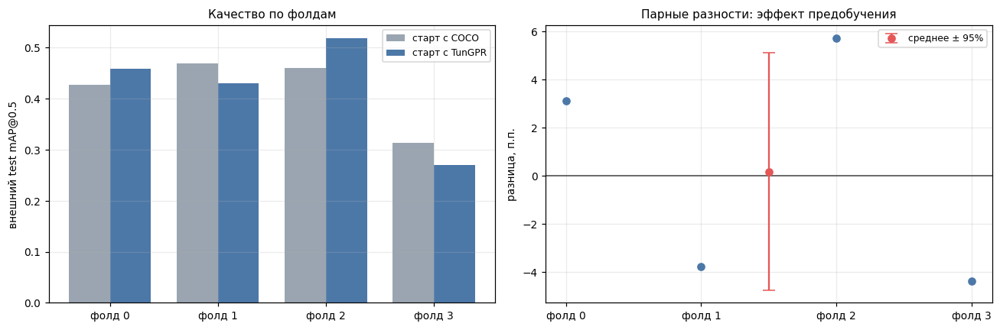

In [82]:
if len(cv_df):
    metric = "внешний test mAP@0.5"
    agg = cv_df.groupby("старт")[metric].agg(["mean", "std", "min", "max"]).round(3)
    display(agg)
    piv = cv_df.pivot(index="фолд", columns="старт", values=metric)
    piv["разница, п.п."] = (piv["tungpr"] - piv["coco"]) * 100
    display(piv.round(3))

    d = piv["разница, п.п."].to_numpy()
    wins = int((d > 0).sum())
    sd = float(np.std(d, ddof=1))
    se = sd / np.sqrt(len(d))
    tstat = float(d.mean() / se) if se > 0 else np.nan
    print(f"синтетика выигрывает в {wins} фолдах из {len(d)}")
    print(f"средняя парная разница {d.mean():+.1f} п.п., "
          f"стандартное отклонение парных разностей {sd:.1f} п.п.")
    print(f"разброс качества между фолдами (все восемь запусков): "
          f"±{cv_df[metric].std()*100:.1f} п.п. — это трудность фолдов, а не эффект")
    print(f"парный t по четырём фолдам: t = {tstat:+.2f} при 3 степенях свободы "
          f"(порог значимости на уровне 0.05 — |t| > 3.18)")
    print("вывод:", "разница значима" if abs(tstat) > 3.182 else
          "устойчивого эффекта не обнаружено; четыре фолда при одном сиде — "
          "слишком малая выборка, чтобы доказать и его отсутствие")

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    x = np.arange(len(piv)); w = 0.38
    axes[0].bar(x - w/2, piv["coco"], w, label="старт с COCO", color="#9AA5B1")
    axes[0].bar(x + w/2, piv["tungpr"], w, label="старт с TunGPR", color="#4C78A8")
    axes[0].set_xticks(x); axes[0].set_xticklabels([f"фолд {i}" for i in piv.index])
    axes[0].set_ylabel(metric); axes[0].legend(fontsize=8)
    axes[0].set_title("Качество по фолдам", fontsize=10)
    axes[1].axhline(0, color="#444", lw=1)
    axes[1].scatter(x, d, color="#4C78A8", zorder=3)
    axes[1].errorbar(len(d) / 2 - 0.5, d.mean(), yerr=1.96 * se, fmt="o", color="#E45756",
                     capsize=5, label="среднее ± 95%")
    axes[1].set_xticks(x); axes[1].set_xticklabels([f"фолд {i}" for i in piv.index])
    axes[1].set_ylabel("разница, п.п."); axes[1].legend(fontsize=8)
    axes[1].set_title("Парные разности: эффект предобучения", fontsize=10)
    plt.tight_layout(); plt.show()

**Результат.** Средние по фолдам совпадают: 0.418 у старта с COCO и 0.419 у старта с
синтетики. Средняя парная разница +0.2 п.п. при стандартном отклонении 5.0 п.п.,
t = 0.07, синтетика выигрывает в двух фолдах из четырёх. **Устойчивого эффекта от
предобучения на синтетике нет.** Доказать, что его нет совсем, четыре фолда тоже не
позволяют — для этого выборка слишком мала.

### 11.15. Детектор пустот на данных USBR

Ultralytics 8.4.154 🚀 Python-3.11.5 torch-2.7.0.dev20250114+cu126 CUDA:0 (NVIDIA GeForce RTX 3090, 24253MiB)
YOLO11s summary (fused): 100 layers, 9,413,187 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5659.1±1085.7 MB/s, size: 63.1 KB)
                   all         48         76      0.356      0.355      0.235     0.0777
Speed: 0.2ms preprocess, 1.4ms inference, 0.0ms loss, 0.4ms postprocess per image


,запуск,класс,precision,recall,mAP@0.5,mAP@0.5:0.95,F2,оговорка
0,e7_usbr_void,void,0.356,0.355,0.235,0.078,0.355,
1,e7_usbr_void,macro,0.356,0.355,0.235,0.078,0.355,


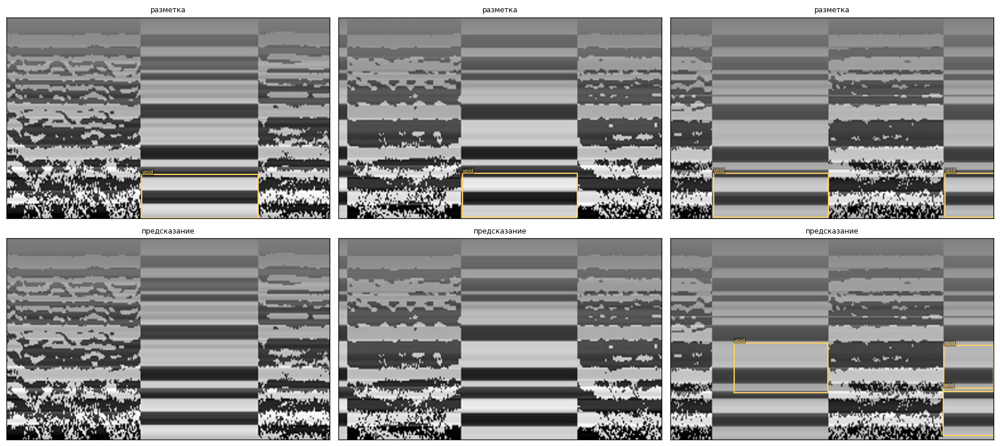

In [83]:
r7 = next((x for x in RESULTS if x["эксперимент"] == "e7_usbr_void"), None)
if r7 is not None and usbr_void_yaml:
    display(class_table("e7_usbr_void", usbr_void_yaml, ["void"], split="val"))
    show_predictions(r7["_model"], usbr_void_yaml, ["void"], split="val", n=3, conf=0.3)

Модель воспроизводит слабую разметку USBR плохо: AP@0.5 = 0.235 при precision и
recall около 0.36. Поскольку сама разметка под вопросом (раздел 2.5), вывод о
качестве поиска пустот по этому эксперименту не делается.

### 11.16. Ансамбль по классам: идея, которая не подтвердилась

Идея была такой: раз разные модели сильны на разных классах, можно брать каждый
класс у лучшей для него модели. Например, пустоты — у модели со своей синтетикой
200 МГц, остальные классы — у модели со стартом с COCO. Дополнительного обучения это
не требует.

Основание оказалось ложным. Оно опиралось на числа из `ultralytics`, где у модели с
синтетикой 200 МГц `Cavity` имел AP = 0.598, а это, как показано в разделе 11.13,
следствие режима NMS. По правильному пересчёту всё наоборот: 0.204 у COCO против
0.004 у синтетики. Таблица ниже это подтверждает: ансамбль хуже одной модели с COCO.

Есть и методическая ловушка: если выбирать источник для каждого класса по тесту и на
нём же измерять выигрыш, «улучшение» получится почти всегда. Правильно выбирать на
валидации и проверять один раз на тесте.

In [84]:
def class_wise_merge(frames_by_source, class_source):
    """Собирает предсказания из разных моделей: для каждого класса берётся та,
    которая на нём лучше. Рамки чужих классов из источника отбрасываются."""
    keys = list(frames_by_source)
    n = len(frames_by_source[keys[0]])
    out = []
    for i in range(n):
        merged = []
        for ci, src in class_source.items():
            fr = frames_by_source.get(src)
            if fr is None:
                continue
            merged += [p for p in fr[i]["pred"] if p[0] == ci]
        base = frames_by_source[keys[0]][i]
        out.append({"image": base["image"], "gt": base["gt"], "pred": merged})
    return out


mix_rows = []
need = {"e3a_road_coco_100": None, "e8_road_from200": None}
for tag in list(need):
    r = next((x for x in RESULTS if x["эксперимент"] == tag), None)
    if r is not None:
        need[tag] = collect_predictions(r["_model"], urdd_yaml, split="test")

if all(v is not None for v in need.values()):
    # Cavity — с модели, предобученной на синтетике 200 МГц; остальные — с COCO
    mapping = {0: "e8_road_from200", 1: "e3a_road_coco_100", 2: "e3a_road_coco_100",
               3: "e3a_road_coco_100"}
    variants = {"только COCO": need["e3a_road_coco_100"],
                "только синтетика 200 МГц": need["e8_road_from200"],
                "поклассовый ансамбль": class_wise_merge(need, mapping)}
    for name, fr in variants.items():
        aps, _ = ap_from_frames(fr, n_classes=len(ROAD_CLASSES))
        row = {"конфигурация": name, "macro mAP@0.5": float(np.nanmean(list(aps.values())))}
        for ci, cname in enumerate(ROAD_CLASSES):
            row[cname] = aps.get(ci, np.nan)
        mix_rows.append(row)
    mix_df = pd.DataFrame(mix_rows)
    display(mix_df.round(3))
    best_single = max(mix_df.loc[mix_df["конфигурация"] != "поклассовый ансамбль",
                                 "macro mAP@0.5"])
    got = float(mix_df.loc[mix_df["конфигурация"] == "поклассовый ансамбль",
                           "macro mAP@0.5"].iloc[0])
    print(f"поклассовый ансамбль: {got:.3f} против {best_single:.3f} у лучшей одиночной "
          f"модели — {'выигрыш' if got > best_single else 'проигрыш'} "
          f"{abs(got - best_single) * 100:.1f} п.п.")
    rap = recall_at_precision(variants["поклассовый ансамбль"], n_classes=len(ROAD_CLASSES))
    support = Counter(g[0] for f in variants["поклассовый ансамбль"] for g in f["gt"])
    display(pd.DataFrame([{"класс": ROAD_CLASSES[c], "объектов в test": support.get(c, 0),
                           "recall при precision ≥ 0.5 (порог с теста)": v[0]}
                          for c, v in rap.items()]).round(3))

,конфигурация,macro mAP@0.5,Cavity,Detachment,Looseness,Water-rich
0,только COCO,0.433,0.204,0.562,0.531,NaN
1,только синтетика 200 МГц,0.142,0.005,0.335,0.086,NaN
2,поклассовый ансамбль,0.366,0.005,0.562,0.531,NaN


поклассовый ансамбль: 0.366 против 0.433 у лучшей одиночной модели — проигрыш 6.6 п.п.


,класс,объектов в test,recall при precision ≥ 0.5 (порог с теста)
0,Cavity,16,0.000
1,Detachment,43,0.744
2,Looseness,14,0.571
3,Water-rich,0,NaN


---
## 12. Выводы

### 12.1. Сводка по всем запускам

Таблица собирается автоматически из результатов всех запусков. Под ней — выигрыш от
предобучения на синтетике по парам запусков (на валидации).

In [85]:
# Автоматическая сводка по всем запускам
summary_rows = []
for r in RESULTS:
    summary_rows.append({k: v for k, v in r.items() if not k.startswith("_")})
final = pd.DataFrame(summary_rows)
display(final.round(3))

def delta(a, b, metric="val mAP@0.5"):
    ra = next((x for x in RESULTS if x["эксперимент"] == a), None)
    rb = next((x for x in RESULTS if x["эксперимент"] == b), None)
    if ra is None or rb is None or metric not in ra or metric not in rb:
        return None
    return (rb[metric] - ra[metric]) * 100

print("\nВыигрыш от синтетического предобучения (в процентных пунктах mAP@0.5):")
for label, a, b in [("железобетон, 80 эпох", "e1a_concrete_coco", "e1b_concrete_tungpr"),
                    ("дороги, 80 эпох, 100% данных", "e2a_road_coco", "e2b_road_tungpr"),
                    ("дороги, 60 эпох, 100% данных", "e3a_road_coco_100", "e3b_road_tungpr_100"),
                    ("дороги, 60 эпох, 50% данных", "e3a_road_coco_50", "e3b_road_tungpr_50"),
                    ("дороги, 60 эпох, 25% данных", "e3a_road_coco_25", "e3b_road_tungpr_25")]:
    d = delta(a, b)
    if d is not None:
        print(f"  {label:32s} {d:+6.1f} п.п.")

try:
    print(f"\nКлассификация реальных дефектов (TIGPR): accuracy "
          f"{tigpr_result['test accuracy']:.3f}, macro-F1 {tigpr_result['test macro-F1']:.3f}")
except NameError:
    pass

,эксперимент,старт,эпох (бюджет),эпох фактически,доля обуч. данных,"время, мин",val mAP@0.5,val mAP@0.5:0.95,обучено сейчас,test mAP@0.5,test mAP@0.5:0.95
0,e0_src_tunnel,yolo11s,60,60,1.0,NaN,0.896,0.749,False,NaN,NaN
1,e1a_concrete_coco,yolo11s,80,80,1.0,NaN,0.834,0.390,False,0.564,0.255
2,e1b_concrete_tungpr,best,80,80,1.0,NaN,0.860,0.373,False,0.581,0.291
3,e2a_road_coco,yolo11s,80,80,1.0,NaN,0.521,0.302,False,0.428,0.175
4,e2b_road_tungpr,best,80,74,1.0,NaN,0.588,0.337,False,0.360,0.157
5,e3a_road_coco_25,yolo11s,60,60,1.0,NaN,0.214,0.076,False,0.273,0.130
6,e3b_road_tungpr_25,best,60,60,1.0,NaN,0.270,0.131,False,0.351,0.180
7,e3a_road_coco_50,yolo11s,60,52,1.0,NaN,0.217,0.112,False,0.167,0.064
8,e3b_road_tungpr_50,best,60,56,1.0,NaN,0.291,0.150,False,0.321,0.131
9,e3a_road_coco_100,yolo11s,60,60,1.0,NaN,0.601,0.341,False,0.485,0.208



Выигрыш от синтетического предобучения (в процентных пунктах mAP@0.5):
  железобетон, 80 эпох               +2.5 п.п.
  дороги, 80 эпох, 100% данных       +6.7 п.п.
  дороги, 60 эпох, 100% данных       +2.1 п.п.
  дороги, 60 эпох, 50% данных        +7.4 п.п.
  дороги, 60 эпох, 25% данных        +5.6 п.п.

Классификация реальных дефектов (TIGPR): accuracy 0.961, macro-F1 0.895


### 12.2. Результаты

**Что сделано.**

* Собраны и разобраны 11 открытых источников георадарных данных: синтетика,
  реальные дороги, железобетон, реальные тоннели, лабораторные и испытательные плиты.
  Для четырёх сырых форматов георадаров (IDS `.dt`, Sensors & Software `.dt1`, GSSI
  `.DZT`, MALÅ `.rd3`) написаны свои читалки, в том числе для формата IDS, для
  которого готового парсера на Python нет.
* Разметка из разных форматов (VOC, COCO, YOLO, папки классов) сведена в одну
  таблицу; проведены EDA и анализ без учителя (эмбеддинги ResNet-18, кластеризация,
  поиск дубликатов и аномалий).
* Подготовлены чистые выборки: одинаковый формат изображений, удаление дубликатов,
  разбиение по группам кадров со стратификацией редких классов, проверка на утечки.
* Обучен детектор YOLO11s — всего 24 запуска: предобучение на синтетике, два
  реальных набора, зависимость от объёма разметки, аугментации, дополнительные
  каналы, своя синтетика gprMax 200 МГц (140 профилей), перекрёстная проверка на
  4 фолдах. Дополнительно обучен классификатор дефектов на TIGPR.

**Основные результаты.**

| Эксперимент | val mAP@0.5 | test mAP@0.5 |
|---|---:|---:|
| E0 — синтетика TunGPR, 6 классов | **0.896** | — |
| E1a / E1b — железобетон P-GPR: старт с COCO / с синтетики | 0.834 / **0.860** | 0.564 / **0.581** |
| E2a / E2b — дороги URDD, 80 эпох: COCO / синтетика | 0.521 / **0.588** | **0.428** / 0.360 |
| E3 — дороги, 60 эпох, 25% разметки: COCO / синтетика | 0.214 / **0.270** | 0.273 / **0.351** |
| E3 — то же, 50% | 0.217 / **0.291** | 0.167 / **0.321** |
| E3 — то же, 100% | 0.601 / **0.621** | **0.485** / 0.417 |
| E4 — дороги, «наивные» аугментации | 0.487 | 0.556 |
| E6 — дополнительные каналы вместо амплитуды | 0.574 | 0.352 |
| E7 — воспроизведение слабой разметки USBR | 0.235 | — |
| E8 — предобучение на своей синтетике 200 МГц | 0.279 | 0.363 |
| E9 — перекрёстная проверка, среднее по 4 внешним фолдам: COCO / синтетика | — | 0.418 / 0.419 |

Классификация (E5, TIGPR): **test accuracy 0.961, macro-F1 0.895.**

**1. Качество зависит от класса.** Чем длиннее дефект и слабее его контраст, тем хуже
он находится:

| Данные | Класс | mAP@0.5 |
|---|---|---:|
| синтетика TunGPR | арматура, границы материалов, оба типа пустот | 0.98–0.99 |
| синтетика TunGPR | расслоение | 0.43 |
| реальный железобетон P-GPR | арматура / трубы | 0.85 / 0.31 |
| реальные дороги URDD | отслоение / разуплотнение / пустоты | 0.56 / 0.53 / 0.20 |

Практическая метрика — recall при точности 0.5, порог выбран на валидации и один раз
применён к тесту:

| Класс | Набор, объектов | Модель | recall | precision |
|---|---|---|---:|---:|
| арматура `steel` | P-GPR, 147 | E1b | 0.878 | 0.603 |
| отслоение `Detachment` | URDD, 43 | E2a | 0.628 | 0.529 |
| разуплотнение `Looseness` | URDD, 14 | E2a | 0.500 | 0.500 |
| трубы `pipe` | P-GPR, 36 | E1b | 0.556 | **0.247** |
| пустоты `Cavity` | URDD, 16 | E2a | 0.125 | 0.400 |

Арматура находится надёжно: почти 9 из 10 стержней. Отслоение и разуплотнение —
примерно в половине случаев. По трубам порог с валидации на тесте не держится
(precision 0.25). **Пустоты — самый важный класс — модель почти не находит:** 2
объекта из 16.

**2. Гипотеза о пользе синтетики не подтвердилась.** На одном разбиении
предобучение на синтетике выигрывало во всех парах на валидации (+2.1…+7.4 п.п.),
но на тесте для дорог давало проигрыш. Парный бутстрэп показал, что разница
статистически не значима (−8.0 п.п., интервал [−21.5; +1.1]). Перекрёстная проверка
на 4 фолдах дала **+0.2 п.п.** при стандартном отклонении 5.0 п.п. (t = 0.07): на
полном объёме данных выбор старта влияет на результат не сильнее, чем случайность
разбиения. При 25–50% разметки синтетика выигрывала и на тесте (+7.8 и +15.4 п.п.),
что согласуется с гипотезой, но это одно разбиение, и перекрёстной проверкой оно не
подкреплено.

**3. Синтетика под целевую частоту не помогла.** Своя синтетика gprMax 200 МГц,
сделанная под параметры дорожной съёмки, дала результат хуже обоих вариантов:
macro AP 0.142 против 0.433 у старта с COCO, по пустотам 0.005 против 0.204. Причину
без дополнительных экспериментов назвать нельзя: одновременно поменялись частота,
геометрия, объём и состав классов.

**4. Что сработало, а что нет.**

* **TTA** (прогон на нескольких масштабах с горизонтальным отражением) — единственное
  улучшение, давшее прирост: **+6.0 п.п.** для базовой модели и **+3.2 п.п.** для
  модели с синтетикой, без дообучения.
* **Классификатор TIGPR** уверенно различает нарушение сцепления слоёв (F1 0.977),
  разуплотнение (0.965) и трещины (0.914); кадры без дефектов — без ошибок. Пустоты
  и здесь слабее всего (F1 0.621). Значит, трещины и разуплотнение на реальном
  сигнале различимы — для них не хватает только разметки рамками.
* **Не сработали:** дополнительные каналы сигнала (−13.3 п.п.), ансамбль WBF двух
  моделей (0.353 против 0.386), ансамбль по классам (0.366 против 0.433).

**5. Результаты о самих данных.**

* **Синтетика и реальные данные различимы, но не полностью.** Линейный классификатор
  по эмбеддингам отличает их с AUC = **0.810**. Если не соблюдать разбиение по
  наборам и подготовку признаков внутри фолда, получается завышенная AUC = 1.000.
* **Перенос на реальные тоннели не виден.** На шести реальных кадрах обделки модель,
  обученная только на синтетике, нашла три объекта — только границы материалов — и
  ни одного дефекта. Это иллюстрация, а не измерение: разметки для этих кадров нет.
* **Пустоты трудны даже для специалиста.** В контролируемом эксперименте USBR, где
  пустоты заложены под плиты специально, авторы съёмки не выделили их ни на одной
  опубликованной сетке, включая плиту без арматуры. Значит, плохой результат по
  пустотам объясняется не только моделью и не только экранированием арматурой.
* **Трещина — это не один класс.** Эксперимент на данных Solla показал, что
  георадар реагирует на заполнитель трещины (вода — сильно, сухой песок и битум —
  слабо), а тонкая воздушная трещина почти не видна.

### 12.3. Практические уроки

**Открытые наборы нельзя брать «как есть».** В каждом использованном наборе нашлась
ловушка, которая искажает метрики:

* *TunGPR*: тег `<filename>` в XML не совпадает с именем файла, и сопоставление по
  нему перемешивает метки; часть объектов размечена повёрнутыми рамками `robndbox`,
  которые простой парсер теряет; кадры с дефектами лежат в JPEG, а без дефектов — в
  PNG, то есть формат файла подсказывает класс.
* *URDD*: 136 кадров из 527 имеют одинаковый перцептивный хеш с другими кадрами и
  при случайном разбиении попадают и в обучение, и в тест. Это совпадение хеша, а не
  точные копии: проверка по пикселям (раздел 6.3) показала, что часть таких кадров
  различается.
* *Morocco*: заявленные 2239 изображений — это аугментированные копии 285 исходных
  профилей, а класс в каждой папке записан как id 0, поэтому при простом объединении
  трубы превращаются в пустоты.

**Метрику стоит проверять второй реализацией.** `ultralytics` показал по пустотам
AP = 0.598, а независимый пересчёт — 0.004. Без второй проверки в работу попал бы
ложный вывод «синтетика под целевую частоту даёт +27.8 п.п. по пустотам». Причина
оказалась в режиме NMS `multi_label=True` внутри `val()` (раздел 11.13). Важно было
довести проверку до конца, а не остановиться на первом правдоподобном объяснении.

**Разрешение при инференсе должно совпадать с обучением.** Сначала предсказания
собирались при 640, хотя дорожные модели обучены при 960. На вытянутых кадрах
1763×548 это в разы занижало качество. Теперь разрешение берётся из самой модели.

**Порог перцептивного хеша нужно подбирать под данные.** Пороги для фотографий
(расстояние 5–10) на георадарограммах выбрасывают до 95% выборки: текстура
однородная, и хеши похожи. Надёжен только порог точного совпадения.

**Первичные документы набора нужно читать целиком.** Заметки обработчика USBR лежали
рядом с данными и прямо противоречили первоначальному выводу, что пустота видна на
плите без арматуры и пропадает под сеткой.

**Версии библиотек нужно фиксировать точно.** Умолчания `ultralytics` меняются между
версиями и влияют на метрики. Кроме того, библиотека сама доустанавливает пакеты:
вызов `val(save_json=True)` установил `pycocotools`, а вместе с ним numpy 2.x, и
окружение, собранное под numpy 1.26, перестало работать.

**Аугментации нужно проверять, а не полагаться на общие рекомендации.** В
`ultralytics` 8.4 `flipud` и `mixup` по умолчанию и так выключены, а эксперимент E4
на одном разбиении дал противоположный знак разницы на валидации и тесте.

### 12.4. Ограничения

1. **Реальные тоннели оценены только визуально.** Модели обучались и оценивались на
   дорожных и железобетонных наборах. Реальные тоннельные записи (Guangzhou, три
   тоннеля, 1.7 млн трасс) есть, но разметки к ним нет, поэтому метрику на тоннелях
   посчитать нельзя.
2. **Мало повторов.** Перекрёстная проверка сделана на 4 фолдах с одним seed. Этого
   хватает, чтобы выигрыш от синтетики не подтвердился, но не хватает, чтобы доказать,
   что его нет. Разброс от случайной инициализации не измерялся: для этого нужно 3–5
   seed на каждую точку, то есть ещё около 40 запусков. Даже у классификатора TIGPR
   повторные прогоны дают разброс около 1 п.п. (0.967 / 0.965 / 0.961), поэтому
   числа относятся к конкретным сохранённым моделям.
3. **Редкие классы.** По `Water-rich` (6 объектов на весь набор) выводы сделать
   нельзя. Этого класса нет в тесте URDD, поэтому val-mAP усредняется по четырём
   классам, а test-mAP — по трём, и сравнивать их напрямую нельзя.
4. **Группы съёмки восстановлены приблизительно.** В URDD и TIGPR нет номеров
   профилей, и группы построены по блокам подряд идущих кадров (10 и 25). Часть
   зависимости между выборками могла остаться, поэтому оценки скорее завышены.
5. **Синтетика однотипна.** TunGPR посчитан для одной частоты (800 МГц) и одного
   окна по времени; для другой аппаратуры синтетику нужно пересчитывать.
6. **Трещины без рамок.** Единственный найденный набор с рамками трещин (LGSC/PGSC)
   скачать не удалось, поэтому трещины оценены только классификатором.

### 12.5. Что нужно для практического применения

1. **Своя разметка** тоннельных записей специалистом-георадарщиком, в координатах
   «положение вдоль тоннеля × время», а не в пикселях. Сколько её нужно, из этой
   работы оценить нельзя: на URDD качество продолжает расти и на 100% разметки.
   Ориентир из литературы — несколько сотен фрагментов на класс.
2. **Тестовый полигон** с заложенными пустотами известного размера, полостями с
   водой, трубами и арматурой — для калибровки, честного теста и адаптации модели.
3. **Синтетика под свою аппаратуру**: gprMax с параметрами реального комплекта —
   частота, окно, шаг, антенна.
4. **Фиксированная предобработка.** Удаление прямой волны, усиление и фильтрация
   должны быть частью модели: детектор, обученный на одном усилении, плохо работает
   на другом.

### 12.6. Направления развития

* Самообучение (SSL) на неразмеченных архивах георадарных съёмок РЖД: таких записей
  терабайты, и разметка для этого не нужна.
* Доменная адаптация «синтетика → реальные данные» (состязательное обучение,
  выравнивание статистик признаков) вместо простого дообучения.
* Абляции для синтетики 200 МГц: менять по одному фактору (частоту, геометрию, состав
  классов, объём), чтобы понять, почему она не помогла.
* Проверка выигрыша синтетики при малой разметке (25–50%) перекрёстной проверкой и
  несколькими seed.
* Сегментация границ слоёв: толщина обделки и положение границ — это задача
  регрессии и сегментации, а не детекции.
* Объединение георадара с лазерным сканированием и фото: трещины на поверхности
  лучше видны оптикой.

### 12.7. Итог

В работе построен полный пайплайн детекции скрытых дефектов на георадарограммах: от
чтения сырых форматов георадаров и очистки открытых наборов до обучения детектора
YOLO11s и статистически корректной оценки результатов. Детектор надёжно находит
арматуру (recall 0.88), примерно в половине случаев — отслоение и разуплотнение, а
классификатор на TIGPR уверенно различает трещины, разуплотнение и нарушения
сцепления слоёв. Главная цель — надёжный поиск пустот в тоннельной обделке — на
открытых данных пока не достигнута: пустоты находятся единицами. Гипотеза о том, что
предобучение на синтетике заметно улучшает результат, при корректной проверке не
подтвердилась. Главный вывод работы: для практического применения важнее всего
собственные размеченные тоннельные данные и тестовый полигон, а не архитектура
модели.